In [3]:
#imports go here

from sage.plot.polygon import Polygon
from sage.plot.colors import rainbow
import time
import threading
import scipy.sparse as sps
from scipy.sparse.linalg import matrix_power
from shapely.geometry import Polygon
from shapely.ops import unary_union
import gc
import sys
import pickle
import numpy as np

In [21]:
# PICKLES

with open("kenyon_1_collars.pickle", "rb") as f:
    one_collars = pickle.load(f)

with open("kenyon_1_collars_list_to_code.pickle", "rb") as f:
    one_collar_list_to_code_dict = pickle.load(f)

with open("kenyon_1_collars_code_to_list.pickle", "rb") as f:
    one_collar_code_to_list_dict = pickle.load(f)

with open("kenyon_2_collars.pickle", "rb") as f:
    two_collars = pickle.load(f)

# L = list(list(two_collars)[0][1])[0][1].parent()

with open("kenyon_2_collars_list_to_code.pickle", "rb") as f:
    collar_list_to_code_dict = pickle.load(f)

# N = list(list(collar_list_to_code_dict.keys())[0][1])[0][1].parent()

with open("kenyon_2_collars_code_to_list.pickle", "rb") as f:
    collar_code_to_list_dict = pickle.load(f)

# N = list(collar_code_to_list_dict['C00'][1])[0][1].parent()

with open("kenyon_2_collared_2_sub_rule.pickle", "rb") as f:
    collared_sub_dict = pickle.load(f)

U = list(list(collared_sub_dict.keys())[0][2])[0][1].parent()

with open("kenyon_2.5_collars.pickle", "rb") as f:
    two_half_collars = pickle.load(f)

M = list(list(two_half_collars)[0])[0][1].parent()

with open("kenyon-one-cell.pickle", "rb") as f:
    one_cells = pickle.load(f)

with open("kenyon-label-to-one-cell.pickle", "rb") as f:
    label_to_one_cell_dict = pickle.load(f)

T = label_to_one_cell_dict['E00'][1][0][1].parent()
    
with open("kenyon-one-cell-to-label.pickle", "rb") as f:
    one_cell_to_label_dict = pickle.load(f)

with open("kenyon-zero-cell.pickle", "rb") as f:
    zero_cells = pickle.load(f)
    
with open("kenyon-zero-cell-to-label.pickle", "rb") as f:
    zero_cell_to_label_dict = pickle.load(f)
    
with open("kenyon-label-to-zero-cell.pickle", "rb") as f:
    label_to_zero_cell_dict = pickle.load(f)

W = label_to_zero_cell_dict['V00'][0][1].parent()

with open("kenyon_uncollared_APlvl1_two_collars.pickle", "rb") as f:
    uncollared_lvl_1_two_collars = pickle.load(f)

uncollared_lvl_1_two_collars_parent = list(list(uncollared_lvl_1_two_collars)[0][1])[0][1].parent()

with open("kenyon_uncollared_APlvl1_two_collars_code_to_list.pickle", "rb") as f:
    uncollared_lvl_1_collar_code_to_list_dict = pickle.load(f)


with open("kenyon_uncollared_APlvl1_two_collars_list_to_code.pickle", "rb") as f:
    uncollared_lvl_1_collar_list_to_code_dict = pickle.load(f)

unc_1_collar_list_to_code_dict_parent = list(list(uncollared_lvl_1_collar_list_to_code_dict.keys())[0][1])[0][1].parent()

with open("kenyon_uncollared_APlvl1_2.5_collars.pickle", "rb") as f:
    uncollared_lvl_1_two_half_collars = pickle.load(f)

with open("kenyon-APlvl1-one-cell.pickle", "rb") as f:
    lvl_1_one_cells = pickle.load(f)

with open("kenyon-APlvl1-label-to-one-cell.pickle", "rb") as f:
    lvl_1_label_to_one_cell_dict = pickle.load(f)
    
with open("kenyon-APlvl1-one-cell-to-label.pickle", "rb") as f:
    lvl_1_one_cell_to_label_dict = pickle.load(f)

with open("kenyon-APlvl1-zero-cell.pickle", "rb") as f:
    lvl_1_zero_cells = pickle.load(f)
    
with open("kenyon-APlvl1-zero-cell-to-label.pickle", "rb") as f:
    lvl_1_zero_cell_to_label_dict = pickle.load(f)
    
with open("kenyon-APlvl1-label-to-zero-cell.pickle", "rb") as f:
    lvl_1_label_to_zero_cell_dict = pickle.load(f)

with open("kenyon_one_cell_sub_dict.pickle", "rb") as f:
    one_cell_sub_dict = pickle.load(f)

with open("kenyon_one_cell_orientations.pickle", "rb") as f:
    orientation_info = pickle.load(f)


print(unc_1_collar_list_to_code_dict_parent)

Number Field in lam with defining polynomial x^3 - x^2 + 2*x + 1


# Number Field Generation and Basic Functions

In [5]:
print(len(one_collars))
print(len(two_collars))


# Expanion factor for Kenyon tiling is complex norm of largest root of x^3 - x^2 + 2*x + 1
# lam = 1/6*sqrt((sqrt(3)*(9/2*sqrt(29) - 43/2)^(1/3) + 5*sqrt(3)*2^(1/3)/(9*sqrt(29) - 43)^(1/3))^2 + ((9/2*sqrt(29) - 43/2)^(1/3) - 5*2^(1/3)/(9*sqrt(29) - 43)^(1/3) - 2)^2)

# We are going to work with number fields.... They are much faster! We start by defining the number field:
R.<x> = QQ[]               # Define the polynomial ring R=Q[x]
f = x^3 - x^2 + 2*x + 1    # f is a polynomial in Q[x] which defines our number field K = R/f
K.<lam> = NumberField(f)

# Now everything should be an element of K, defined in terms of lam(bda). We do computation over K. 
# If we need to graph something (e.g. for bugfixing or just to look at pretty pictures), then we need to embed this into
# C, and then map this onto R^2. 
# sigma = max(K.embeddings(CC), key=lambda r: norm(r(lam))) # This leads to everything being reflected because we take the conjugate of the one we want
sigma = K.embeddings(CC)[2]

# Maps elements of K into points which we can graph. Note: this depends on the embedding sigma.
def number_field_to_vector(pt, a=1, b=0):
    if pt not in K:
        raise Exception("pt must be an element of the number field K")

    return (sigma(a * (pt + b)).real(), sigma(a * (pt + b)).imag())


substitutions = {
    "B": [
        ("R", -lam^2)
    ],
    
    "R": [
        ("R", 0),
        ("R", lam),
        ("G", 2*lam - lam^2)
    ],
    
    "G": [
        ("R", 0),
        ("B", lam - 1)   
    ],
}



# These are the vertices for the Kenyon (1,2,1) tiling, ordered CCW.
tile_vertices = {
    "B" : (0, -lam, 1-lam, 1),
    
    "R" : (0, -lam^2, lam - lam^2, lam),

    "G" : (0, 1, 1 + lam^2, lam^2)
}
    
    

# Finds the two edge endpoints which border (0,0) in a collar, given a collar code and origin.
def find_collar_edges(code, origin, AP_level) -> set:
#     if len(code) < 4:
#         raise Exception(f"{code} is not a 1-collar code.")
    

    collar_vertices = generate_k_collar_vertices(code, origin, AP_level)
    
    edges = set()
    for i in range(len(collar_vertices)):
        edges.add(frozenset({collar_vertices[i], collar_vertices[(i+1) % len(collar_vertices)]}))
        
    return edges

# Takes in a collar code and origin, and outputs a list of vertices corresponding to the center tile of the collar (i.e. the non-decoration one)
def generate_k_collar_vertices(code, origin, AP_level) -> list:
    if code in "RBG":
        center_tile_code = code
    elif code[0] == '1':
        center_tile_code = uncollared_lvl_1_collar_code_to_list_dict[code][0][1:]
    elif code[0] == 'C':
        center_tile_code = collar_code_to_list_dict[code][0]

    if AP_level == 0:
        return generate_tile_vertices(center_tile_code, origin)
    elif AP_level == 1:
        return generate_supertile_vertices(center_tile_code, origin)

def generate_tile_vertices(code, origin) -> list:
    shifted_vertices = list()
    for pt in tile_vertices[code]:
        shifted_vertices.append(pt + origin)

    return shifted_vertices

def generate_supertile_vertices(code, origin) -> list:
    shifted_vertices = list()
    for pt in supertile_vertices[code]:
        shifted_vertices.append(pt + origin)

    return shifted_vertices


num_prototiles_dict = {
    "B" : [1],
    "R" : [1],
    "G" : [1]
}
def count_prototiles(code, level):
    assert (level >= 0)
    
    if code == "B":
        if len(num_prototiles_dict["B"]) < level + 1:
            num_tiles = count_prototiles("R", level - 1)
            num_prototiles_dict["B"].append(num_tiles)
        return num_prototiles_dict["B"][level]
        
    if code == "R":
        if len(num_prototiles_dict["R"]) < level + 1:
            num_tiles = 2*count_prototiles("R", level - 1) + count_prototiles("G", level - 1)
            num_prototiles_dict["R"].append(num_tiles)
        return num_prototiles_dict["R"][level]
        
    if code == "G":
        if len(num_prototiles_dict["G"]) < level + 1:
            num_tiles = count_prototiles("R", level - 1) + count_prototiles("B", level - 1)
            num_prototiles_dict["G"].append(num_tiles)
        return num_prototiles_dict["G"][level]

num_supertiles_dict = {
    "B" : [1],
    "R" : [1],
    "G" : [1]
}
def count_supertiles(code, level):
    assert (level >= 0)
    
    if code == "B":
        if len(num_supertiles_dict["B"]) < level + 1:
            num_tiles = 2*count_supertiles("R", level - 1) + count_supertiles("G", level - 1)
            count_supertiles("B", level - 1)
            num_supertiles_dict["B"].append(num_tiles)
        return num_supertiles_dict["B"][level]
        
    if code == "R":
        if len(num_supertiles_dict["R"]) < level + 1:
            num_tiles = 5*count_supertiles("R", level - 1) + 2*count_supertiles("G", level - 1) + count_supertiles("B", level - 1)
            num_supertiles_dict["R"].append(num_tiles)
        return num_supertiles_dict["R"][level]
        
    if code == "G":
        if len(num_supertiles_dict["G"]) < level + 1:
            num_tiles = 3*count_supertiles("R", level - 1) + count_supertiles("G", level - 1)
            num_supertiles_dict["G"].append(num_tiles)
        return num_supertiles_dict["G"][level]

elem_U = list(list(collared_sub_dict.keys())[0][2])[0][1]
U = elem_U.parent()
gen_U = U.gen()

to_U = K.hom([gen_U], U)
to_K_subdict = U.hom([lam], K)

# we need to do the same thing for the half collars
elem_M = list(list(two_half_collars)[1])[0][1]
M = elem_M.parent()
# gen is the generator of M
gen_M = M.gen()

# so we need to define homomorphisms between L and K so that we can check equivalence and do operations
#  between elements of K and L
to_M = K.hom([gen_M], M)
to_K_half = M.hom([lam], K)
    
# given a pickled list of half collars, converts all origins to be in the field K
def convert_half_collar_list(half_collar_list):
    new_half_collar_list = set()
    for half_collar in half_collar_list:
        new_half_collar = set()
        for collar in half_collar:
            collar_code = collar[0]
            new_origin = to_K_half(collar[1])
            new_half_collar.add((collar_code, new_origin))
        new_half_collar_list.add(frozenset(new_half_collar))
    return new_half_collar_list

def convert_collared_sub_dict(collared_sub_dict):
    new_collared_sub_dict = dict()
    for collar in collared_sub_dict.keys():
        new_collar = convert_raw_collar(collar)
        
        (subbed_collars, extra_tiles) = collared_sub_dict[collar]
        
        new_subbed_collars = set()
        for subbed_collar in subbed_collars:
            new_subbed_collar = convert_raw_collar(subbed_collar)
            new_subbed_collars.add(new_subbed_collar)
            
        new_tiles = set()
        for tile in extra_tiles:
            new_tile = (tile[0], to_K_subdict(tile[1]))
            new_tiles.add(new_tile)

        new_collared_sub_dict[new_collar] = (frozenset(new_subbed_collars), frozenset(new_tiles))

    return new_collared_sub_dict

def convert_raw_collar(raw_collar):
    new_decoration = set()
    for tile in raw_collar[2]:
        new_tile = (tile[0], to_K_subdict(tile[1]))
        new_decoration.add(new_tile)
    new_collar = (raw_collar[0], to_K_subdict(raw_collar[1]), frozenset(new_decoration))

    return new_collar

def build_supertile_vertices_dict():
    global supertile_vertices
    
    supertile_vertices = dict()

    for code in substitutions.keys():
        supertile = []
        for located_subtile in substitutions[code]:
            subtile_loc = located_subtile[1]
            subtile_code = located_subtile[0]
            for located_subtile in substitutions[subtile_code]:
                prototile_loc = located_subtile[1] + subtile_loc*lam
                prototile_code = located_subtile[0]
                
                supertile.append(generate_tile_vertices(prototile_code, prototile_loc))
        
        # STAGE 1
        
        # Now we will check each point in subtile.edge to see if it is on the edge of the supertile. If so,
        # we add it to self.edge
        
        is_edge = False
        while is_edge == False:
            for tile_verts in supertile:
                for pt in tile_verts:
                    i = tile_verts.index(pt)
                    # point immediately counterclockwise of pt
                    nxt_pt = tile_verts[(i+1) % len(tile_verts)]

                    # check how many tiles contain both pt and nxt_pt
                    common_tiles = set()
                    for tile_verts_2 in supertile:
                        if pt in tile_verts_2 and nxt_pt in tile_verts_2:
                            common_tiles.add(tuple(tile_verts_2))

                    # if pt and nxt_pt only have one tile in common, pt is on the edge
                    if len(list(common_tiles)) == 1:
                        is_edge = True
                        break
                if is_edge == True:
                    break
            # if pt is on the edge, add it to self.edge
            if is_edge == True:        
                supertile_vertices[code] = [pt, nxt_pt]
                # self.edge_tiles.add(list(common_tiles)[0])

    
        # STAGE 2
        last_pt = nxt_pt
        
        # Now, we go from last_pt and try to complete the loop!
        finished = False
        while not finished:
            # Check all tiles containing last_pt
            for tile_verts in supertile:
                if last_pt in tile_verts:
                    i = tile_verts.index(last_pt)
                    
                    # Look at adjacent, more counterclockwise point
                    nxt_pt = tile_verts[(i+1) % len(tile_verts)]
                    # nxt_pt = vector(QQ[a], nxt_pt, immutable=True)
                    
                    # If nxt_pt is already in self.edge, the loop is closed and we are done
                    # if nxt_pt in supertile_vertices[code]:
                    #     finished = True
                    #     break
    
                    # If not, check if last_pt and nxt_pt share just one tile. If so, nxt_pt is on the edge
                    # (same process as before)
                    common_tiles = set()
                    for tile_verts_2 in supertile:
                        if last_pt in tile_verts_2 and nxt_pt in tile_verts_2:
                            common_tiles.add(tuple(tile_verts_2))
                    if len(list(common_tiles)) == 1:
                        if nxt_pt in supertile_vertices[code]:
                            finished = True
                        else:
                            supertile_vertices[code].append(nxt_pt)
                        # self.edge_tiles.add(list(common_tiles)[0])
                        break
            # The new most counterclockwise point is nxt_pt, and we repeat the process
            last_pt = nxt_pt

    return supertile

build_supertile_vertices_dict()

two_half_collars = convert_half_collar_list(list(two_half_collars))
new_M = list(list(two_half_collars)[0])[0][1].parent()

collared_sub_dict = convert_collared_sub_dict(collared_sub_dict)
new_U = list(collared_sub_dict.keys())[0][1].parent()
                                                     
print(K is new_M)
print(K is T)
print(K is W)
print(K is U)
print(K is new_U)
print(K is unc_1_collar_list_to_code_dict_parent)

13
33
True
True
True
True
True
True


# Patch\(\) class



In [6]:
# We want to redefine the Penrose substitution to handle arbitrary patches instead of specific supertiles. So, we need a new class.
# We should keep a set of prototiles in the patch, as well as a fixed origin. Tiles can be added/removed in the patch, and the entire 
# patch can be substituted arbitrarily. Note that many of the ot
class Patch:

    # A PenrosePatch consists of a set of prototiles, together with a fixed origin. By default, this is set to (0,0).
    # A prototile is a tuple represented as: (code, origin). See the documentation for generate_code(). The size of a
    # patch is the number of prototiles it contains. 
    def __init__(self, origin=0):
        self.prototiles = []
        self.origin = origin

        self.vertex_to_tiles = {}
        self.prev_prototiles = None

        self.adj = None
        self.has_vertex_list = False
        self.size = 0
        self.level = 0
        
        self.collars_set = set()
        self.half_collars_set = set()
        self.border_tiles = set()
        self.edge_tiles = set()

    # Resets certain properties of the patch. This is called when the patch is updated or changed and
    # these values have to be recalculated to be used. 
    def reset_properties(self):
        self.vertex_to_tiles = {}
        self.adj = None
        self.has_vertex_list = False
        self.border_tiles = set()
        

    # Displays the patch graphically
    def graph_patch(self):
        P = Graphics()
        ################# CHANGED color options #################
        for tile in self.prototiles:
            if tile in self.edge_tiles:
                P += self.tile_to_polygon(tile, False, 0.2)
            else:
                P += self.tile_to_polygon(tile, False, 0.2)

        return P

    
    # Add a prototile by its code and origin, rather than shape and orientation directly.
    def add_prototile_code(self, code, origin):
        if code not in "RGB":
            raise Exception(f"Invalid tile code: {code}")
        
        new_tile = (code, origin)
        self.prototiles.append(new_tile)
        self.reset_properties()
        self.size += 1

    # Removes a prototile with the given attributes from the patch. Returns -1 if none exists.
    def remove_prototile(self, tile):
        self.reset_properties()
        self.size -= 1
        return self.prototiles.remove(tile)

    # Substitutes the entire patch, according to the substitution rule.
    def substitute_patch(self):
        new_prototiles = []
        
        for tile in self.prototiles:
            for t in substitutions[tile[0]]:
                new_tile = (t[0], lam*(tile[1])+t[1])
                new_prototiles.append(new_tile)
                self.size += 1
            self.size -= 1
        self.level += 1

        if self.level == 2:
            self.prev_prototiles = self.prototiles

        self.prototiles = new_prototiles
        self.reset_properties()

    
    # MOVE OUTSIDE CLASS
    # returns the tile as a polygon of points (useful when doing graphing debugging stuff)
    def tile_to_polygon(self, tile, use_shapely=False, opacity=0.5):
        if tile[0] not in "BRG":
                raise Exception("Invalid code")

        colors = {
            'B' : 'blue',
            'R' : 'red',
            'G': 'grey'
        }
        
        real_verts = list()
        code = tile[0]
        for j in range(len(tile_vertices[code])):
            real_verts.append(number_field_to_vector(tile_vertices[code][j], 1, tile[1]))

        if use_shapely:
            return Polygon(real_verts)
    
        return polygon(real_verts, rgbcolor = colors[tile[0]], alpha=opacity, edgecolor='black', axes=False)
        

    # Preprocessing to store the list of tiles at each vertex, to efficiently find neighbors
    def generate_vertex_lists(self):       
        for tile in self.prototiles:
            for pt in tile_vertices[tile[0]]:
                shifted_pt = pt + tile[1]
                if shifted_pt not in self.vertex_to_tiles:
                    self.vertex_to_tiles[shifted_pt] = [tile]
                else:
                    self.vertex_to_tiles[shifted_pt].append(tile)

        self.has_vertex_list = True

    # In order to find collars, we build an adjacency matrix of the prototiles. An edge exists if two tiles
    # share a vertex. A k-collar around a tile is then a patch that consists of that tile and its k-neighborhood
    # in the adjacency matrix. We can then construct PenrosePatch objects for each collar that we find.
    def generate_adjacency_matrix(self, multithread=False):
        if not self.has_vertex_list:
            self.generate_vertex_lists()

        # Allows for inverse lookup - prototile -> index in self.prototiles
        self.prototile_indices = {}
        
        for k in range(len(self.prototiles)):
            tile = self.prototiles[k]
            self.prototile_indices[tile] = k
            
#         self.adj = sps.coo_matrix((self.size, self.size), dtype='bool')
        
        indices_to_set = []


        # Unthreaded code 
        # We want to discard collars that are 'incomplete', i.e. don't have decorating tiles fully surrounding the
        # tile we are collaring. We did this before by removing a collar if some edge of the collared tile was not
        # covered by another tile in the decoration. But this won't work now. 
        # Idea: for each vertex, we need to check if that vertex is surrounded. How? For each tile on that vertex,
        # find the angle made by the two edges which share that vertex and then make sure that the sum of the angles
        # is 2pi. Otherwise, the vertex isn't surrounded. 
        if not multithread:
            for tile_i in self.prototiles:
                for pt_i in tile_vertices[tile_i[0]]:
                    for tile_j in self.vertex_to_tiles[pt_i + tile_i[1]]:
                        i = self.prototile_indices[tile_i]
                        j = self.prototile_indices[tile_j]
                        indices_to_set.append((i,j))
                        
            d = [1] * len(indices_to_set)
            r = [i for (i,j) in indices_to_set]
            c = [j for (i,j) in indices_to_set]
            
            self.adj = sps.coo_matrix((d, (r, c)), shape=(self.size, self.size), dtype='bool') # + self.adj

        else:
            raise Exception("Multithreading not implemented...")


    # Finds the prototiles which lie along the border of two supertiles within a patch. This is used to optimize
    # the way we find collars. If we find all the collars in a patch and then substitute, all the new collars will
    # appear along the border of two supertiles in the substituted patch, so we use this to limit our search there.
    # This should only be used when the patch is just a single large supertile - otherwise, it will not work.
    def find_border(self, k):
        self.border_tiles = set()
        self.border_points = set()
        
        if self.adj == None:
            self.generate_adjacency_matrix()

        # prototile_nums: list
        # prototile_nums[i] is the number of prototiles in the (i+1)th defined level n-1 subtile and all previously defined subtiles
        # e.g. prototile_nums[0] is the number of prototiles belonging to the subtile that is defined first
        #      and prototile_nums[2] is the number of prototiles belonging to the subtiles that are defined third or earlier 
        prototile_nums = []
        for tile in self.prev_prototiles:
            if len(prototile_nums) == 0:
                # add number of prototiles in the first subtile 
                prototile_nums.append(count_prototiles(tile[0], self.level-1))
            else:
                # number of prototiles so far defined
                prev_num = prototile_nums[-1]
                # add the additional prototiles defined in (i+1)th subtile
                prototile_nums.append(count_prototiles(tile[0], self.level-1) + prev_num)

        mat = matrix_power(self.adj, k)
                
        ################# CHANGED number of subtiles #################
        # R has 3 subtiles. We will be dividing the adjacency matrix in 3 and iterating through the top right 3 squares
        if len(self.prev_prototiles) == 3:
            for i in range(1, 3):
                for j in range(i):
                    for k in range(prototile_nums[i-1], prototile_nums[i]):
                        if j == 0:
                            m = 0
                        else:
                            m = prototile_nums[j-1]
                        # can't column slice with COO array so convert to CSC array first
                        col = mat.tocsc()[:, k]
                        for l in range(m, prototile_nums[j]):
                            if col[l]:
                                tile_k = self.prototiles[k]
                                tile_l = self.prototiles[l]
                                
                                self.border_tiles.add(tile_k)
                                self.border_tiles.add(tile_l)
                                
                                for pt in tile_vertices[tile_k[0]]:
                                    self.border_points.add(pt+tile_k[1])
                                for pt in tile_vertices[tile_l[0]]:
                                    self.border_points.add(pt+tile_l[1])
        
        ################# CHANGED number of subtiles #################
        # G has 2 subtiles. We will be dividing the adjacency matrix in 2 and iterating through the top right square
        if len(self.prev_prototiles) == 2:
            for i in range(1, 2):
                for j in range(i):
                    for k in range(prototile_nums[i-1], prototile_nums[i]): # Is this right??
                        if j == 0:
                            m = 0
                        else:
                            m = prototile_nums[j-1]
                        # can't column slice with COO array so convert to CSC array first
                        col = mat.tocsc()[:, k]
                        for l in range(m, prototile_nums[j]):
                            if col[l]:
                                tile_k = self.prototiles[k]
                                tile_l = self.prototiles[l]
                                
                                self.border_tiles.add(tile_k)
                                self.border_tiles.add(tile_l)
                                
                                for pt in tile_vertices[tile_k[0]]:
                                    self.border_points.add(pt+tile_k[1])
                                for pt in tile_vertices[tile_l[0]]:
                                    self.border_points.add(pt+tile_l[1])
        
    def graph_subtiles(self):
        prototile_nums = []
        for tile in self.prev_prototiles:
            if len(prototile_nums) == 0:
                # add number of prototiles in the first subtile 
                prototile_nums.append(count_prototiles(tile[0], self.level-1))
            else:
                # number of prototiles so far defined
                prev_num = prototile_nums[-1]
                # add the additional prototiles defined in (i+1)th subtile
                prototile_nums.append(count_prototiles(tile[0], self.level-1) + prev_num)
                
        G = Graphics()
        
        colors = ['red', 'blue', 'yellow', 'purple']
        start_i = 0
        for j in range(len(self.prev_prototiles)):
            end_i = prototile_nums[j]
            for k in range(start_i, end_i):
                tile = self.prototiles[k]
                G += self.tile_to_polygon_obj(tile[0], tile[1], colors[j])
            start_i = end_i
            
        return G   
        
    # Actually while commenting this I realized it may be more efficient to make self.edge a list that
    # orders the points counterclockwise. Then, we can make it more efficient because as soon as we find a
    # point in subtile.edge that is also on the edge of the supertile, we can immediately move onto
    # STAGE 2 instead of looking at every single point in subtile.edge!!
    # good idea -nathan 
    def find_edge(self):
        
        self.edge = []
        self.edge_tiles = set()

        # Redoing this with shapely...
        polys = []
        for tile in self.prototiles:
            polys.append(self.tile_to_polygon(tile, True))

        merged = unary_union(polys)
        edge_pts = list(merged.exterior.coords)
        
        # Now we have a list of the points. We want to mark any tile which has a vertex close to one of these as an edge tile.
        # Note that these points are NOT stored symbolically, so we can't check exactly. We just check for a small distance.
        for tile in self.prototiles:
            for pt2 in edge_pts:
                for symb_pt in tile_vertices[tile[0]]:
                    pt1 = number_field_to_vector(symb_pt + tile[1])
                    if (vector(pt1) - vector(pt2)).norm() <= 0.1: # Might depend on the tiling? I think something like lam/2 is fine?
                        self.edge_tiles.add(tile)
                        break
                if tile in self.edge_tiles:
                    break

        return self.edge_tiles
              
                    
    # Finds the tiles which are on the 'border' of the patch - this is more complicated than it seems.
    # In the chair, it was easy since border tiles will always have an entire edge on the border. This
    # is no longer the case with the Kite-Dart. Here is an idea: for every vertex of the tile to collar,
    # check to make sure that every tile on that vertex shares an edge with 2 other tiles on that vertex.
    # Then, the vertex is surrounded. Maybe this is too slow? Good news: we only have to do it for tiles
    # on the border between supertiles. 
    def remove_edge(self, k):
        if self.adj == None:
            self.generate_adjacency_matrix()
        
        self.find_border(k)
        tiles_to_remove = set()
        points_to_remove = set()
        

        tiles_to_remove = self.find_edge()
        
        if k > 1:            
            more_tiles = set()
            mat = matrix_power(self.adj, k-1)

            for tile in tiles_to_remove:            
            # for tile in self.edge_tiles:
                j = self.prototile_indices[tile]
                col = mat.getcol(j).toarray()
                
                for i in range(self.size):
                    if col[i]:
                        tile_i = self.prototiles[i]
                        more_tiles.add(tile_i)
                        
                        for pt in tile_vertices[tile_i[0]]:
                            points_to_remove.add(pt + tile_i[1])
                        
                        
            tiles_to_remove = tiles_to_remove | more_tiles   
        
        result = self.border_tiles - tiles_to_remove
        self.border_tiles = result
        
        result = self.border_points - points_to_remove
        self.border_points = result
        
        return
    
#     '''########## functions to find k collars ##########'''    
    
    # Displays all k-collars present within the tile, excluding those which are on the border.
    def find_suptile_collars(self, k=1, seen_collars_set=set(), use_multithreading=False):
        mat = matrix_power(self.adj, k)
        
        for tile in self.border_tiles:
            collar = self.generate_collar(tile, mat, use_multithreading)
            
            # Quit early if we've already seen this collar
            if collar in seen_collars_set:
                continue 
            
            # # Assign this collar a specific collar code, and populate the dictionary to go between codes and collars.
            # collar_code = "C" + str(self.num_collars)
            # self.num_collars += 1
            # suptile_collars_dict[collar_code] = collar
            seen_collars_set.add(collar)     
            
        return seen_collars_set
    
    # Generates the k-collar of the tile with the given index, based on the previously calculated adjacency matrix.
    def generate_collar(self, tile_to_collar, mat, use_multithreading=False):
        index_of_collared_tile = self.prototile_indices[tile_to_collar]
        collar_tiles = set()
        origin_tile_code = tile_to_collar[0]

        origin_pt = tile_to_collar[1]
        
        # A collar is a set of tiles surrounding a specific tile, where everything should be shifted so the 
        # tile being collared is at the origin. 
        col = mat.getcol(index_of_collared_tile).toarray()
        for i in range(0, self.size):
            if col[i]:
                tile = self.prototiles[i]
                shifted_tile_origin = tile[1] - origin_pt
                collar_tile = (tile[0], shifted_tile_origin)       
                collar_tiles.add(collar_tile)

        return (origin_tile_code, frozenset(collar_tiles))

    
    # Displays a collar graphically
    def display_collar(self, collar):
        G = Graphics()
        
        for tile in collar[1]:
            opacity = 1 if (tile[0] == collar[0] and tile[1] == 0) else 0.2
            G += self.tile_to_polygon(tile, False, opacity)

        return G
        
    
    '''########## functions to find k+0.5 collars ##########'''    
    
    # Displays all k-collars present within the tile, excluding those which are on the border.
    def find_suptile_half_collars(self, k=1, seen_collars = set(), use_multithreading=False):
        self.half_collars_set = seen_collars
        mat = matrix_power(self.adj, k)
        # show(self.graph_patch() + points(list(self.border_points)))
        for point in self.border_points:
            collar = self.generate_half_collar(point, mat, k, use_multithreading)
            if collar in self.half_collars_set:
                continue
            self.half_collars_set.add(collar)
            
        return self.half_collars_set
    
    # Generates the (k+0.5)-collar of the tile with the given index, based on the previously calculated adjacency matrix.
    def generate_half_collar(self, point_to_collar, mat, k, use_multithreading=False):
        
        k_half_collar = set()
        
        # Let's get the 0.5 collar first, then expand it if needed. This part is easy!
        unshifted_half_collar_tiles = set(self.vertex_to_tiles[point_to_collar])

        # must shift the tiles so that the point_to_collar is at the origin
        for tile in unshifted_half_collar_tiles:
            shifted_tile_origin = tile[1] - point_to_collar
            # if k = 0, we just need a 0.5 collar. So, our job is
            # done, just add the tiles we found beforehand into the k_half_collar set (with their shifted origins)
            if k == 0:
                collar_tile = (tile[0], shifted_tile_origin)
                # now, each element of our 0.5 collar is:
                # (tile code, tile origin wrt center point)
                k_half_collar.add(collar_tile)
            # if we need more than 0.5 collar, we go through each tile and add its k-collar
            else:
                
                # recall: k collar = (center tile code, entire patch of tiles)
                k_collar = self.generate_collar(tile, mat)
                
                # we want to be consise and store the k collars with their codes if we can
                if k == 2:
                    try:

                        # collar_in_K = k_collar
                        # # decoration_in_L = set()
                        # # for neighbor_tile in collar_in_K[1]:
                        # #     loc_in_L = to_L(neighbor_tile[1])
                        # #     decoration_in_L.add((neighbor_tile[0], loc_in_L))

                        # # collar_in_L = (collar_in_K[0], frozenset(decoration_in_L))
                        # collar_in_L = convert_collar(collar_in_K, to_L)

                        
                        # k_collar_code = collar_list_to_code_dict[collar_in_L]
                        k_collar_code = collar_list_to_code_dict[k_collar]

                    except:
                        print(f'We found this supposed 2 collar: {k_collar}')
                        # print(f'Its code is {k_collar_code}')
                        G = self.graph_patch()
                        G += self.tile_to_polygon(tile)
                        # G += point([point_to_collar], marker='*', size=30)
                        show(G)
                    relative_k_collar = (k_collar_code, shifted_tile_origin)
                else:
                    relative_k_collar = (k_collar, shifted_tile_origin)
              
                k_half_collar.add(relative_k_collar)
        
        return frozenset(k_half_collar)
                
        
    # Displays a collar graphically
    def display_half_collar(self, half_collar, k, have_dict = False):
        G = Graphics()
        # plot the center point (with a fun star!)        
        G += point((0,0), size=200, marker='*', rgbcolor=(0,1,0), zorder=10)
        
        # A k.5-collar contains a set of k-collars. So we essentially just graph these all together.
        for element in half_collar:
            # elements are prototiles
            if k == 0:
                tile = element
                G += self.tile_to_polygon(tile, False, 0.2)
            
            # elements are k-collars
            else:
                # check if 2.5 collar
                if have_dict:
                    k_collar_code = element[0]
                    k_collar = collar_code_to_list_dict[k_collar_code]
                # not 1.5 collar:
                else:
                    k_collar = element[0]
                # either way, when we get the 'raw' k collar, its the same process:
                shifted_origin = element[1]
                # iterate through all tiles in each k collar
                for tile in k_collar[1]:
                    # shift the origin of each tile so that its origin is wrt the
                    # center point of the half collar
                    # new_tile = (tile[0], to_K(tile[1]) + shifted_origin)
                    new_tile = (tile[0], tile[1] + shifted_origin)
                    # now that the tile is described wrt the center point we can plot it
                    G += self.tile_to_polygon(new_tile, False, 0.2)
        show(G)

## Graphing Test

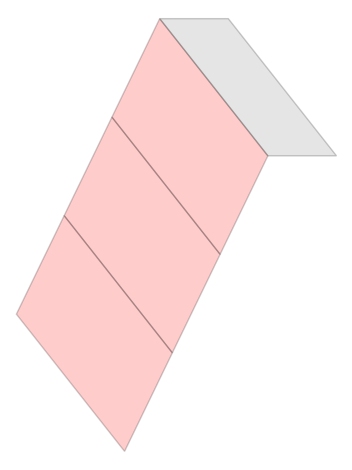

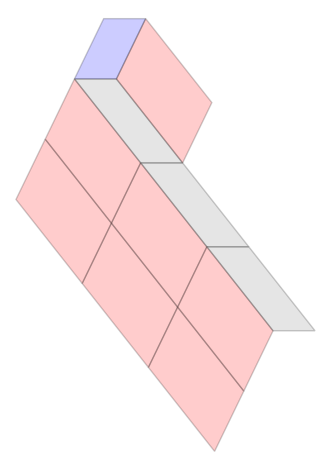

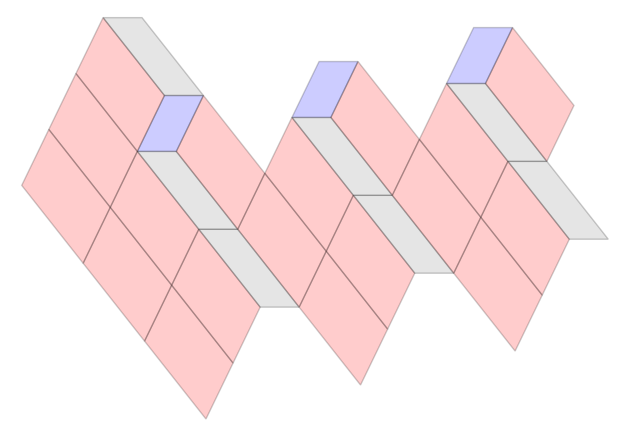

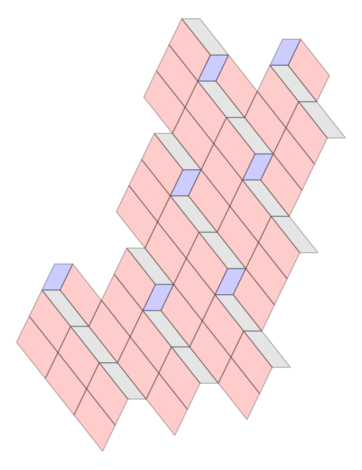

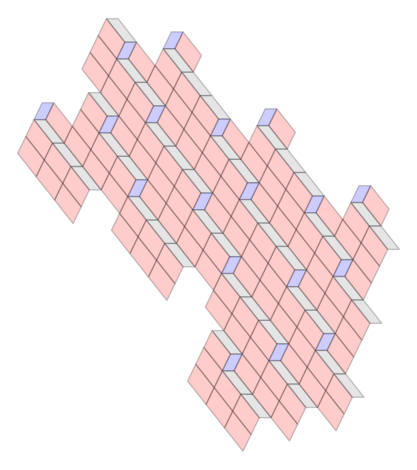

Took 2.13 seconds.


In [7]:
real_verts = [[None] * 4] * 3

def graph_kenyon_tile(code, a=1, b=0):
    if code not in "BRG":
        raise Exception()

    real_verts = list()
    for j in range(len(tile_vertices[code])):
        real_verts.append(number_field_to_vector(tile_vertices[code][j], a, b))

    return polygon(real_verts, fill=False)

                          

# G = Graphics()
# for child in substitutions['R']:
#     G += graph_kenyon_tile(child[0], lam, child[1])
# show(G)

# show(graph_kenyon_tile('G', 1, 0))

start = time.time()

patch = Patch()
patch.add_prototile_code("G", 0)
patch.substitute_patch()
for i in range(5):
    patch.substitute_patch()
    show(patch.graph_patch())

# patch.generate_vertex_lists()
# patch.find_edge()

# show(patch.graph_patch())

end = time.time()
print(f"Took {end - start:.2f} seconds.")

# CollaredKenyonPatch\(\) class



In [8]:
# I think i corrected all the tuples but i'll test it out to make sure
class CollaredKenyonPatch(Patch):
    def __init__(self, origin=0, sub_dict=None):
        self.collared_tiles = set()
        self.prototiles = [] # includes only extra tiles
        self.origin = origin
        self.sub_dict = sub_dict 

        self.vertex_to_tiles = {}
        self.prev_prototiles = None
        
        self.adj = None
        self.has_vertex_list = False
        self.size = 0
        self.level = 0
        self.marked_decorations = None

    def reset_properties(self):
        Patch.reset_properties(self)

    # Adds a collared prototile to the patch
    def add_collared_prototile(self, code, origin, collar_set):
        self.collared_tiles.add((code, origin, collar_set))
        

    # Displays the patch graphically
    def graph_patch(self):
        all_tiles = set(self.prototiles) 
        
        # accumulating all the tiles
        for collar_tile in self.collared_tiles:
            all_tiles.add((collar_tile[0], collar_tile[1]))
            for tile in collar_tile[2]:
                all_tiles.add((tile[0], tile[1] + collar_tile[1]))
        
        # get vertex lists
        if not self.has_vertex_list:
            self.generate_vertex_lists()

        # graph collared prototiles
        P = Graphics()
        for collar_tile in self.collared_tiles:
            P += self.tile_to_polygon((collar_tile[0], collar_tile[1]), False, 1.0)
                
        # graph all prototiles (overlap in collared tiles I guess?)
        for tile in all_tiles:
            P += self.tile_to_polygon(tile, False, 0.2)

        if self.marked_decorations != None:
            for tile in self.marked_decorations:
                P += self.tile_to_polygon(tile, False, 0.4)
            
        return P
    
    
    # Substitutes the collared patch according to the induced substitution rule
    def substitute(self, marked_decoration=None):
        self.reset_properties()
                
        if self.sub_dict == None:
            raise Exception("Substitution dictionary is not defined. Use 'self.substitute_once' to build a dictionary.")

        new_prototiles = set()
        self.marked_decorations = set()
        
        # First we just substitute the extras like normal.
        for tile in self.prototiles:
            for t in substitutions[tile[0]]:
                
                new_tile = (t[0], lam * tile[1] + t[1])
                new_prototiles.add(new_tile)

        # Now we substitute the collared tiles for the new collared tiles.
        new_collared_tiles = set()
        
        for collared_tile in self.collared_tiles:
            
            key_decoration = collared_tile[2] | frozenset({(collared_tile[0], 0)})
            collared_substitutions = self.sub_dict[(collared_tile[0], 0, key_decoration)]
            for collared_sub_tile in collared_substitutions[0]:
                new_collared_tile = (collared_sub_tile[0], collared_sub_tile[1]+lam*collared_tile[1], collared_sub_tile[2])
                new_collared_tiles.add(new_collared_tile) 

            # now look through all decoration tiles for the relevant one
            for decoration_tile in collared_tile[2]:
                if decoration_tile == marked_decoration:
                    # substitute this decoration tile and store in self.marked_decorations set
                    for t in substitutions[decoration_tile[0]]:                
                        decoration_sub_tile = (t[0], lam * decoration_tile[1] + t[1] + lam * collared_tile[1])
                        self.marked_decorations.add(decoration_sub_tile)

               
                

            for extra_sub_tile in collared_substitutions[1]:
                new_tile = (extra_sub_tile[0], extra_sub_tile[1] + lam*collared_tile[1])
                new_prototiles.add(new_tile)

        self.prototiles = list(new_prototiles)
        self.collared_tiles = new_collared_tiles

        return self.collared_tiles, self.marked_decorations

    # Substitutes a single collared tile once, in order to build up our substitution dictionary.
    def substitute_once(self, k, marked_tiles=None):
        self.k = k
        self.reset_properties()
        marked_decorations = set()

        self.prototiles = set(self.prototiles)
        for collar in self.collared_tiles:
            self.prototiles.add((collar[0], collar[1]))
            for tile in collar[2]:
                self.prototiles.add((tile[0], tile[1]+collar[1]))

        # Substitute the entire patch
        new_prototiles = set()
        new_collared_tiles = set()

        collared_prototiles = set()
        for collar in self.collared_tiles:
            collared_prototiles.add((collar[0], collar[1]))

        # Now we make a list of the substituted prototiles. The ones which aren't collared or part of a decoration
        # will be kept in self.prototiles, and the ones which are collared will be kept in self.collared_tiles.        
        for tile in self.prototiles:
            if tile in collared_prototiles:
                # We want to mark the new tiles we get as being collars. We can go back later to find exactly which collar they belong to.
                for t in substitutions[tile[0]]:
                    new_tile = (t[0], lam*(tile[1])+t[1], True)
                    new_collared_tiles.add(new_tile)

                
            for t in substitutions[tile[0]]:
                new_tile = (t[0], lam*(tile[1])+t[1])
                new_prototiles.add(new_tile)

                if tile in marked_tiles:
                    marked_decorations.add(new_tile)

        # Now new_prototiles has all of the tiles (including collared & decoration tiles), and new_collared_tiles has just the
        # new collared tiles but without any information about what their collar is. So we need to build the adjacency matrix
        # and figure out what to mark the new collared tiles as.
        self.prototiles = list(new_prototiles)
        self.collared_tiles = new_collared_tiles

        self.generate_adjacency_matrix()

        # Now we have the adjacency matrix. So we need to find the specific collar of every collared tile. 
        newer_collared_tiles = set()
        all_tiles_in_collar = set()
        
        for collar_tile in self.collared_tiles:
            collar_prototile = (collar_tile[0], collar_tile[1])
            mat = matrix_power(self.adj, k)
            index_of_collared_tile = self.prototile_indices[collar_prototile]
            tiles_in_collar = set()

            col = mat.getcol(index_of_collared_tile).toarray()
            for i in range(0, self.size):
                if col[i]:
                    tile = self.prototiles[i]
                    shifted_tile_origin = tile[1] - collar_prototile[1]
                    tile_in_collar = (tile[0], shifted_tile_origin)
                    tiles_in_collar.add(tile_in_collar)
                    
            newer_collared_tiles.add((collar_tile[0], collar_tile[1], frozenset(tiles_in_collar)))

            for tile in tiles_in_collar:
                all_tiles_in_collar.add(tile)

        
        self.collared_tiles = newer_collared_tiles
        self.marked_decorations = marked_decorations
        
        return newer_collared_tiles, marked_decorations


    def generate_adjacency_matrix(self):
        if not self.has_vertex_list:
            self.generate_vertex_lists()

        # Allows for inverse lookup - prototile -> index in self.prototiles
        self.prototile_indices = {}
        self.size = len(self.prototiles)
        
        for k in range(len(self.prototiles)):
            tile = self.prototiles[k]
            self.prototile_indices[tile] = k
            
        indices_to_set = []
                
        for tile_i in self.prototiles: 
            for pt_i in tile_vertices[tile_i[0]]:
                for tile_j in self.vertex_to_tiles[pt_i + tile_i[1]]:
                    i = self.prototile_indices[tile_i]
                    j = self.prototile_indices[tile_j]
                    indices_to_set.append((i,j))

        d = [1] * len(indices_to_set)
        r = [i for (i,j) in indices_to_set]
        c = [j for (i,j) in indices_to_set]

        self.adj = sps.coo_matrix((d, (r, c)), shape=(self.size, self.size), dtype='bool') # + self.adj


    def generate_vertex_lists(self):
        all_tiles = set(self.prototiles)
        
        for collar_tile in self.collared_tiles:
            all_tiles.add((collar_tile[0], collar_tile[1]))
            if collar_tile[2] == True:
                continue
            for tile in collar_tile[2]:
                all_tiles.add((tile[0], tile[1] + collar_tile[1]))
        
        
        for tile in all_tiles:
            for pt in tile_vertices[tile[0]]:
                shifted_pt = pt + tile[1]
                if shifted_pt not in self.vertex_to_tiles:
                    self.vertex_to_tiles[shifted_pt] = [tile]
                else:
                    self.vertex_to_tiles[shifted_pt].append(tile)

        self.has_vertex_list = True
        self.prototiles = list(all_tiles)
        

    def find_edge(self):
        
        self.generate_vertex_lists()
        possible_border_tiles = []
        
        # if we just have one collar, all points are on the edge
        if len(self.collared_tiles) == 0:
            possible_border_tiles = self.collared_tiles[1]
        else:
            possible_border_tiles = self.prototiles
#             center = collar[0]
#             center_pts = set(generate_tile_vertices(center, self.origin))
#             all_pts = set()
#             for decoration in collar[1]:
#                 dec_code = decoration[0]
#                 dec_origin = decoration[1]
#                 all_pts = all_pts | set(generate_tile_vertices(dec_code, dec_origin + self.origin)) 
#             self.edge = all_pts.difference(center_pts)
#             self.edge_tiles = self.prototiles
#             return
        
        self.edge = []
        self.edge_tiles = set()
        
        # STAGE 1
        
        # Now we will check each point in subtile.edge to see if it is on the edge of the supertile. If so,
        # we add it to self.edge
        
        is_edge = False
        while is_edge == False:
            for tile in possible_border_tiles:
                for pt in self.prototile_vertices[tile]:
                    i = self.prototile_vertices[tile].index(pt)
                    # point immediately counterclockwise of pt
                    nxt_pt = self.prototile_vertices[tile][(i+1) % len(self.prototile_vertices[tile])]

                    # check how many tiles contain both pt and nxt_pt
                    common_tiles = list(set(self.prototile_vertices_inverse[pt]) & set(self.prototile_vertices_inverse[nxt_pt]))

                    # if pt and nxt_pt only have one tile in common, pt is on the edge
                    if len(common_tiles) == 1:
                        is_edge = True
                        break
                if is_edge == True:
                    break
            # if pt is on the edge, add it to self.edge
            if is_edge == True:        
                self.edge.append(pt)
                self.edge.append(nxt_pt)
                self.edge_tiles.add(list(common_tiles)[0])

    
        # STAGE 2
        last_pt = nxt_pt
        
        # Now, we go from last_pt and try to complete the loop!
        finished = False
        while not finished:
            # Check all tiles containing last_pt
            for tile in self.prototile_vertices_inverse[last_pt]:
                i = self.prototile_vertices[tile].index(last_pt)
                
                # Look at adjacent, more counterclockwise point
                nxt_pt = self.prototile_vertices[tile][(i+1) % len(self.prototile_vertices[tile])]
                nxt_pt = vector(QQ[a], nxt_pt, immutable=True)
                
                # If nxt_pt is already in self.edge, the loop is closed and we are done
                if nxt_pt in self.edge:
                    finished = True
                    break

                # If not, check if last_pt and nxt_pt share just one tile. If so, nxt_pt is on the edge
                # (same process as before)
                common_tiles = set(self.prototile_vertices_inverse[last_pt]) & set(self.prototile_vertices_inverse[nxt_pt])
                if len(common_tiles) == 1:
                    self.edge.append(nxt_pt)
                    self.edge_tiles.add(list(common_tiles)[0])
                    break
            # The new most counterclockwise point is nxt_pt, and we repeat the process
            last_pt = nxt_pt
        

# CWComplex\(\) class



In [9]:
def translate_all_points(s: set, t: vector):
    result = set()
    for pt in s:
        new_pt = vector(QQ[a], pt + t, immutable=True)
        result.add(new_pt)
    return result


from collections import namedtuple

Vertex = namedtuple("Vertex",["collar","coord"])
Edge = namedtuple("Edge",["v_from","v_to"])
Face = namedtuple("Face",["verts"])


"""
To build the complex: disjoint sets of (TILE_CODE, ORIGIN). Each set refers to a particular edge.
If an element (TILE_CODE, ORIGIN) is in the set corresponding to (EDGE LABEL, POINT 1, POINT 2), then 
EDGE LABEL appears at the origin of (TILE_CODE, 0,0) when it is shifted to instead be at ORIGIN. 
The edge in the tile which corresponds to EDGE LABEL is the one that goes from POINT 1 to POINT 2, 
or the other way around (and then orientation is reversed).

It will help to store the edges as being entirely within the first quadrant, to avoid double counting.
"""
class CWComplex:
    
    def __init__(self, code_to_points_dict, points_to_code_dict):
#         self.ring = ring    # "ring"
        
        # assuming that these are lists of all vertices (0 cells), edges (1 cells), and faces (2 cells) in our CW complex
        # irregargless of gluings
        self.V = set()
        self.E = set()
        self.F = set()
        
        # what are these for
        self.vertex_coords = []
        self.tiles = []
        self.vertex_repr = {}
        
        # dictionaries to translate between codes and points
        self.code_to_points_dict = code_to_points_dict
        self.points_to_code_dict = points_to_code_dict
        
        # so this is the Disjoint set where we have all the gluings (for both edges and points?)
        self.uf = DisjointSet({})
        self.zero_cells_disjoint_set = DisjointSet({})
        self.zero_cells = []
    
    
    # in general, input is dictionary mapping from prototiles to their vertices, list of one collars
    def initiate_disjoint_set(self, k, AP_level):
        
        # the last two elements of our edge tuples only depend on the shape and orientation of the center
        # tile of a collar. So, we will just calculate those for C0 through C4 and then store in a dictionary
        edges_per_tile_type_dict = dict()
        
        for shape in tile_types: 
            edges_per_tile_type_dict[f'{shape}'] = set()
            # we need the vertices of the prototile to get the edge endpoints
            if AP_level == 0:
                vertices = generate_tile_vertices(f'{shape}', 0)
            elif AP_level == 1:
                vertices = generate_supertile_vertices(f'{shape}', 0)
                
            vertices = [K(vertex).vector() for vertex in vertices]

            # get the 'raw' edges, i.e. the endpoints are relative to the origin of the prototile
            n = len(vertices)
            raw_edges = [(vertices[i], vertices[(i + 1) % n]) for i in range(n)]


            for edge in raw_edges:
                # # we find the leftmost endpoint
                # tx = min(edge[0][0], edge[1][0])
                # # we find the lowest endpoint
                # ty = min(edge[0][1], edge[1][1])

                # # now we can translate the endpoints such that both endpoints are on the x or y axis respectively
                # # this translation removes information on the location of the edge relative to the tile, and it keeps
                # # information on the direction of the edge (in the chair tiling case, either horizontal or vertical)
                # #translation = vector(QQ[a], [-tx, -ty], immutable=True)
                # translation = vector([-tx, -ty], immutable = True)

                translation = [- min(edge[0][i], edge[1][i]) for i in range(K.degree())]
                translation = vector(translation, immutable = True)
                # translated_edge = frozenset({vector(QQ[a], edge[0] + translation, immutable=True), vector(QQ[a], edge[1]+translation, immutable=True)})
                translated_edge = frozenset({vector(edge[0] + translation, immutable = True), vector(edge[1]+translation, immutable = True)})
                    
                # We still need to know the location of the edge and prototile relative to eachother, and the translation
                # vector encodes that
                located_edge = (translation, translated_edge)
                if k==0:
                    self.E.add((f'{shape}', located_edge[0], located_edge[1]))
                else:
                    edges_per_tile_type_dict[f'{shape}'].add(located_edge)
                
                # basically what we did was take the 'raw' edge and seperate the information on its orientation and on its relative
                # location to the prototile. It is still the same amount of information, we are just writing it differently! (apparently
                # this way is simpler/more convenient??)
         
        if k > 0:
            # now we can list all edges for all k collars (not gluing anything yet)
            for k_code in list(self.code_to_points_dict.keys()): # we need to make general, do we pass the relevant dictionary to this function? or what
                k_collar = self.code_to_points_dict[k_code]
                # find out orientation of center tile, so we can reference our dictionary
                k_collar_center_code = k_collar[0][1:]
            
                for located_edge in edges_per_tile_type_dict[k_collar_center_code]:   
                    # list the k collar code along with the located edge 
                    final_edge = (k_code, located_edge[0], located_edge[1])
                    self.E.add(final_edge)
        
        # add edge to disjoint set
        self.uf = DisjointSet(self.E)
        
        
    def get_half_collar_prototile_vertices(self,half_collars_list):
        # Processes a list of k+0.5 collars (e.g., half_collars_list) and returns the vertex data for the prototiles that constitutes of edges starting/ending at the origin.
        # Update: using the helper function findedge_endpoints
        # half_collars_list: The list of half-collars.
 
        all_edge_lists = []
        i = 0
        for half_collar in half_collars_list:
            i += 1
            print(f'\tcreating edge list of half collar {i}/{len(half_collars_list)}')
            # k_collar_code is a list of prototile codes that make up the k-collar
        
            edge_list = []
        
            # Iterate through the 1-collars that make up the (k+0.5)-collar
            for k_collar in half_collar:

                edge_list.append({
                    "code": k_collar[0],
                    "edges": find_collar_edges(k_collar[0], k_collar[1], 1), # GENERALIZE; now works for prototiles
                    "old origin": k_collar[1]
                })
        
            # making it store the original half collar too for debugging purposes
            all_edge_lists.append((half_collar, edge_list)) 

        return all_edge_lists

    # sorry bad name ill change later
    def glue_all_edges(self,all_edge_lists):

        counter = 0
        for edge_list in all_edge_lists:
            counter += 1
            print(f'\tlooking at edge list {counter}/{len(all_edge_lists)}')
            
            unions = 0
            all_intersections = []
            
            for i in range(len(edge_list[1])):
                dict_i = edge_list[1][i]
                for j in range(i+1, len(edge_list[1])):
                    dict_j = edge_list[1][j]
                    
                    intersection = dict_i['edges'] & dict_j['edges']
                    for edge in intersection:  
                        
                        origin_i = vector(K(dict_i['old origin']).vector(), immutable = True)
                        origin_j = vector(K(dict_j['old origin']).vector(), immutable = True)
                        
                        ordered_edge = list(edge)
                        ordered_edge = [v.vector() for v in ordered_edge]
                        all_intersections.append(ordered_edge)
                        
                        # tx = -min(ordered_edge[0][0], ordered_edge[1][0])
                        # ty = -min(ordered_edge[0][1], ordered_edge[1][1])
                        # #translation = vector(QQ[a], [tx, ty], immutable=True)
                        # translation = vector([tx, ty], immutable = True)
                        translation = [- min(ordered_edge[0][i], ordered_edge[1][i]) for i in range(K.degree())]
                        translation = vector(translation, immutable = True)
                        
                        # translated_edge = frozenset({vector(QQ[a], (vector(ordered_edge[0]) + translation), immutable=True), vector(QQ[a], (vector(ordered_edge[1]) + translation), immutable=True)})
                        translated_edge = frozenset({vector((ordered_edge[0] + translation), immutable = True), vector((ordered_edge[1] + translation), immutable = True)})
                        located_edge = (translation, translated_edge)
                    
                        # these are the two edges (in 3-tuple format) that need to be glued together
                        # edge_i = (dict_i['code'], vector(QQ[a], located_edge[0] + origin_i, immutable=True), located_edge[1])
                        edge_i = (dict_i['code'], vector(located_edge[0] + origin_i, immutable = True), located_edge[1])
                        # edge_j = (dict_j['code'], vector(QQ[a], located_edge[0] + origin_j, immutable=True), located_edge[1])
                        edge_j = (dict_j['code'], vector(located_edge[0] + origin_j, immutable = True), located_edge[1])
                    
                        self.uf.union(edge_i, edge_j)
                        unions += 1
            codes = []
            for k_collar in edge_list[0]:
                codes.append(k_collar[0])
        
        self.one_cells = []
        for cell in self.uf:
            new_cell = [None, []]
            for edge in cell:
                trimmed_edge = (edge[0], edge[1])
                new_cell[1].append(trimmed_edge)
                new_cell[0] = edge[2]
            # # to fix hashing problem:
            # print(new_cell)
            # new_cell[1] = tuple(new_cell[1])
            # new_cell[0] = frozenset({new_cell[0]})
            # new_cell = tuple(new_cell)
                
            self.one_cells.append(new_cell)
        

        new_one_cells = []
        new_one_cells_shorthand = []
        matched_one_cells = set()
        unmatched_one_cells = set()

        print('merging one cells...')
        # compare all pairs of one cells to see if they 'stay together' in all
        # parts of the tiling. If so, they can be merged (not 'identified')
        
        # iterate through one cells
        for i in range(len(self.one_cells)):      
            print(f'\tfirst one cell {i}/{len(self.one_cells)}')
            # to prevent accidentally duplicating one cells while merging:
            if i in matched_one_cells:
                continue
            
            found_a_match = False
            cell_i = self.one_cells[i]
            new_cell_i = [set(),[]] 
            # iterate through other one cells
            for j in range(i+1, len(self.one_cells)):
                print(f'\t\tsecond one cell {j}/{len(self.one_cells)}')
                if j in matched_one_cells:
                    continue
                # the 'matched' variable indicates how many i edges (you know, the edges that are identified to
                # determine one cell i) ar next to an edge j in their collar
                matched = 0
                
                # Prevents unwanted additions to new_cell_i, in the case that two collars are identified but
                # the edges are not supposed to be merged.
                cand_cell_i = ({(cell_i[0], 'i')}, [])
                
                cell_j = self.one_cells[j]
                
                # get translation vectors to align the collar of edge i/j at
                # all possible edge endpoints
                i_translates = sorted(list(cell_i[0]))
                j_translates = sorted(list(cell_j[0]))
                
                # i_translate_1 = -vector(QQ[a], i_translates[0])
                # i_translate_2 = -vector(QQ[a], i_translates[1])  
                # j_translate_1 = -vector(QQ[a], j_translates[0])
                # j_translate_2 = -vector(QQ[a], j_translates[1])
                i_translate_1 = -i_translates[0]
                i_translate_2 = -i_translates[1]
                j_translate_1 = -j_translates[0]
                j_translate_2 = -j_translates[1]
                                
                # the final translation should be determined to be the same for all edge mergings.
                final_translation = 'not defined yet'
                
                # iterate through all edges in cell i
                for edge_i in cell_i[1]:
                    
                    # iterate through all edges in cell j, check if ANY edge j is next to edge i
                    for edge_j in cell_j[1]:
                        # check if on the same collar (otherwise can't be next to eachother)
                        if edge_i[0] == edge_j[0]: 
                            # i_position = vector(QQ[a], edge_i[1])
                            # j_position = vector(QQ[a], edge_j[1])
                            i_position = edge_i[1]
                            j_position = edge_j[1]
                                        

#                             if i_translate and j_translate:
                            if i_position + i_translate_1 == j_position + j_translate_1 or i_position + i_translate_1 == j_position + j_translate_2:
                                # we need to store j_position
                                if final_translation == 'not defined yet' or final_translation == i_translate_1:#, j_translate):
                                    # cand_cell_i[1].append((edge_i[0], vector(QQ[a], (i_position + i_translate_1), immutable=True)))
                                    cand_cell_i[1].append((edge_i[0], (i_position + i_translate_1)))
                                    cand_cell_i[0].add((cell_j[0], 'j'))
                                    matched += 1
                                    final_translation = i_translate_1#, j_translate)
                                    if i_position + i_translate_1 == j_position + j_translate_1:
                                        common_pt = (-i_translate_1, -j_translate_1)
                                    else:
                                        common_pt = (-i_translate_1, -j_translate_2)
                                    continue
                                
                            elif (i_position + i_translate_2 == j_position + j_translate_1) or (i_position + i_translate_2 == j_position + j_translate_2):
                                if final_translation == 'not defined yet' or final_translation == i_translate_2:
                                    # cand_cell_i[1].append((edge_i[0], vector(QQ[a], i_position + i_translate_2, immutable=True)))
                                    cand_cell_i[1].append((edge_i[0], i_position + i_translate_2))
                                    cand_cell_i[0].add((cell_j[0], 'j'))
                                    matched += 1
                                    final_translation = i_translate_2
                                    if i_position + i_translate_2 == j_position + j_translate_1:
                                        common_pt = (-i_translate_2, -j_translate_1)
                                    else:
                                        common_pt = (-i_translate_2, -j_translate_2)
                                    continue
                                
                                    
                          
                if matched == len(cell_i[1]):
                    # Commit the changes to the candidate cell into new_cell_i
                    translation = [0 for i in range(K.degree())]
                    # tx = 0
                    # ty = 0
                    
                    for labeled_edge in cand_cell_i[0]:
                            edge = list(labeled_edge[0])
                            label = labeled_edge[1]
                            if label == 'i':
                                initial_t = common_pt[0]
                            else:
                                initial_t = common_pt[1]
                            # edge[0] = vector(QQ[a], vector(edge[0]) - initial_t, immutable=True)
                            # edge[1] = vector(QQ[a], vector(edge[1]) - initial_t, immutable=True)
                            edge[0] = edge[0] - initial_t
                            edge[1] = edge[1] - initial_t

                            translation = [min(edge[0][i], edge[1][i], translation[i]) for i in range(K.degree())]
                            # tx = min(edge[0][0], edge[1][0], tx)
                            # ty = min(edge[0][1], edge[1][1], ty)
                            
                       
                    for labeled_edge in cand_cell_i[0]:
                        edge = list(labeled_edge[0])
                        # print(f'edge[0]: {edge[0]}')
                        # print(f'type edge[0]: {type(edge[0])}')
                        # print(f'edge[1]: {edge[1]}')
                        label = labeled_edge[1]
                        if label == 'i':
                            initial_t = common_pt[0]
                        else:
                            initial_t = common_pt[1]
                        
                        # edge[0] = vector(QQ[a], vector(edge[0]) - vector((tx, ty)) - initial_t, immutable=True)
                        # edge[1] = vector(QQ[a], vector(edge[1]) - vector((tx, ty)) - initial_t, immutable=True)
                        edge[0] = vector(edge[0] - vector(translation) - initial_t, immutable=True)
                        edge[1] = vector(edge[1] - vector(translation) - initial_t, immutable=True)

                        edge = frozenset(edge)
                        new_cell_i[0].add(edge)
                        
                    # Freeze everything so we can hash a one cell
                    final_edge_set = frozenset(new_cell_i[0])
                    new_cell_i[0] = final_edge_set
                    
                    for collar in cand_cell_i[1]:
                        # collar = (collar[0], vector(QQ[a], collar[1] - vector((tx, ty)), immutable=True))
                        collar = (collar[0],  vector(collar[1] - vector(translation), immutable=True))
                        
                        new_cell_i[1].append(collar)
                   
                    new_cell_i[1] = tuple(new_cell_i[1])
                    new_one_cells.append(tuple(new_cell_i))
                    new_one_cells_shorthand.append([i, j])
                    found_a_match = True
                    
                    if i in matched_one_cells:
                        print('we are merging something too many times')
                    
                    matched_one_cells.add(i)
                    matched_one_cells.add(j)
                    # continue
                    break
                 
                             
            if (not found_a_match) and (i not in matched_one_cells):
                # print("cell_i",cell_i)
                new_cell_i = (frozenset({cell_i[0]}), tuple(cell_i[1]))
                new_one_cells.append(new_cell_i)
                new_one_cells_shorthand.append([i])
                unmatched_one_cells.add(i)
                    
        self.old_one_cells = self.one_cells
        self.one_cells = new_one_cells 
        #self.convert_one_cells_to_poly()
        
#         print('matched one cells:', matched_one_cells)
        
#         print('unmatched one cells:', unmatched_one_cells)

        # print(f'shorthand: {new_one_cells_shorthand}')

    # converts points in one_cells into polynomial form instead of vector form
    def convert_one_cells_to_poly(self):
        one_cells = self.one_cells
        new_one_cells = list()
        for one_cell in one_cells:
            new_edges = list()
            for edge in one_cell[0]:
                new_edge = list()
                for vertex in edge:
                    new_vertex = K(vertex)
                    new_edge.append(new_vertex)
                new_edge = frozenset(new_edge)
                new_edges.append(new_edge)
            new_edges = frozenset(new_edges)
        
            new_collars = list()
            for collar in one_cell[1]:
                new_collar = (collar[0], K(collar[1]))
                new_collars.append(new_collar)
        
            new_collars = tuple(new_collars)
            new_one_cell = (new_edges, new_collars)
            new_one_cells.append(new_one_cell)
        
        self.one_cells = new_one_cells
    
    
    def obj_to_label_map(self, prefix="E"):
        obj_to_label = {}
        label_to_obj = {}
        width = len(str(len(self.one_cells) - 1))

        for i, one_cell in enumerate(self.one_cells, start=0):
            label = f"{prefix}{i:0{width}d}"
            label_to_obj[label] = one_cell
            obj_to_label[one_cell] = label

        return label_to_obj, obj_to_label
 
    
    
# given a set containing edges that connect (i.e. the first entry of the one_cell), returns a list of the endpoints
    def get_endpoints(self, edges):
        endpoints = []
            # Case A: cell itself is a single undirected edge: frozenset({v1, v2})
        if len(edges) == 1:
            # items = [vector(QQ[a], v, immutable=True) for v in list(edges)[0]]
            items = [v for v in list(edges)[0]]
            if len(items) == 2:
                v1, v2 = sorted(items)
                endpoints.append(v1)
                endpoints.append(v2)
        
        # Case B: cell is a collection of edges (e.g. set/frozenset of frozensets)
        # Extract all edges from it. 
        else:
            #print('case B', 'cell', cell)
            cell = list(edges)
            # first_edge = cell[0]
            # last_edge = cell[-1]
            # print(cell)
            vertices = [tuple(v) for v in cell]
            pts = []
            for item in vertices:
                for i in range(len(cell)):
                    if item[i] in pts:
                        pts.remove(item[i])
                    else:    
                        pts.append(item[i])
            endpoints.append(pts[0])
            endpoints.append(pts[-1])
        return endpoints
        
                
        # Note (Nov 28): Instead of having a whole list and merging stuff, we can populate another list from scratch to avoid repetitions (Nathan's suggestion)
                
    # Once we have the one-cells, we can generate the zero cells. A one cell looks like a list of: (collar, translation, edge). 
    # To generate the corresponding zero cells, we go through each pair of one cells, and identify them together if they both contain the same collared tile, relative to the point we are interested in. For instance, two one cells would get identified if they both include (C000, (-1,0)), where the coordinate gives the origin of the C000 tile, relative to the point we are interested in. 
    # Then a zero cell looks like a list of: (one cell, point on the edge) where the translation gives the position of the origin of the collar
    # relative to the point which is being identified. 
    def glue_zero_cells(self, one_cell_to_label_dict):
        # Initialize the disjoint set of zero cells
        print('\tInitializing the disjoint set of zero cells')
        for one_cell in self.one_cells:
            cell = one_cell[0]
            endpoints = self.get_endpoints(cell)
            for endpoint in endpoints:
                # pt = (one_cell_to_label_dict[one_cell], vector(QQ[a], endpoint, immutable=True))
                pt = (one_cell_to_label_dict[one_cell], endpoint)
                self.V.add(pt)
        self.zero_cells_disjoint_set = DisjointSet(self.V)

#         for endpoint in one_cell[0]:
#             pt = (tuple(one_cell[1]), tuple(endpoint))
#             self.V.add(pt)
#         self.zero_cells_disjoint_set = DisjointSet(self.V)

#         Now do the identifications.
        print('\tNow doing the identifications')
        for i in range(len(self.one_cells)):
            print(f'\t\tfirst one cell {i}/{len(self.one_cells)}')
            for j in range(i+1, len(self.one_cells)):
                print(f'\t\t\tsecond one cell {j}/{len(self.one_cells)}')
                one_cell_i = self.one_cells[i]
                one_cell_j = self.one_cells[j]  
                
                cell_i_endpoints = self.get_endpoints(one_cell_i[0])
                cell_j_endpoints = self.get_endpoints(one_cell_j[0])
                
                for pt_1 in cell_i_endpoints:
                    for edge in one_cell_i[1]:
                        # translated_cell_i = [(edge[0], vector(QQ[a], vector(edge[1]) - vector(pt_1), immutable=True)) for edge in one_cell_i[1]]
                        translated_cell_i = [(edge[0], vector(edge[1] - pt_1, immutable = True)) for edge in one_cell_i[1]]
                    for pt_2 in cell_j_endpoints:
                        # translated_cell_j = [(edge[0], vector(QQ[a], vector(edge[1]) - vector(pt_2), immutable=True)) for edge in one_cell_j[1]]
                        translated_cell_j = [(edge[0], vector(edge[1] - pt_2, immutable = True)) for edge in one_cell_j[1]]
                       
                        if len(set(translated_cell_i) & set(translated_cell_j)) != 0:
                            self.zero_cells_disjoint_set.union((one_cell_to_label_dict[one_cell_i], pt_1), (one_cell_to_label_dict[one_cell_j], pt_2))
    
        temp_zero_cells = list(self.zero_cells_disjoint_set)
        self.zero_cells = list()
        for zero_cell in temp_zero_cells:
            self.zero_cells.append(tuple(zero_cell)) # does this need to be a vector??
             
#                 for pt_1 in one_cell_i[0]:
#                     translated_cell_i = [(edge[0], tuple(vector(edge[1]) - vector(pt_1))) for edge in one_cell_i[1]] 
#                     for pt_2 in one_cell_j[0]:
#                         translated_cell_j = [(edge[0], tuple(vector(edge[1]) - vector(pt_2))) for edge in one_cell_j[1]]

#                         if len(set(translated_cell_i) & set(translated_cell_j)) != 0:
#                             self.zero_cells_disjoint_set.union((tuple(one_cell_i[1]), pt_1), (tuple(one_cell_j[1]), pt_2))

        #self.convert_zero_cells_to_poly()
    

    def convert_zero_cells_to_poly(self):
        zero_cells = self.zero_cells
        new_zero_cells = list()
        for zero_cell in zero_cells:
            new_zero_cell = list()
            for edge in zero_cell:
                new_edge = (edge[0], K(edge[1]))
                new_zero_cell.append(new_edge)
            new_zero_cell = tuple(new_zero_cell)
            new_zero_cells.append(new_zero_cell)
        self.zero_cells = new_zero_cells
    
           
                 

            
    # Post-process 1-cells to identify 'the same' one cells (e.g. the inner L in the chair)
    # Substitute 1-cells - just take a single collar in which the 1-cell appears, and substitute it.
    # Then look at where the 1-cell goes. It should be the intersection of two of the resulting 1-collars. After 
    # post-processing, this should be just a bunch of 1-cells. 
    # To substitute a 0 cell, do the same. The nice part is that a 0-cell only gets sent to one 0-cell, so it isn't branched.
    
    
    # Among the one cells which have been made, finds which one contains the input, where COLLAR is the code of the collar
    # which contains the edge we want, and EDGE is a description of the edge (in terms of its endpoints)
    def find_one_cell(self, collar, edge):
        if self.one_cells == None:
            raise Exception("Must generate one-cells first.")
            
    def obj_to_label_map_zero_cells(self, prefix="V"):
        obj_to_label = {}
        label_to_obj = {}
        width = len(str(len(self.zero_cells) - 1))

        for i, zero_cell in enumerate(self.zero_cells, start=0):
            label = f"{prefix}{i:0{width}d}"
            label_to_obj[label] = zero_cell
            obj_to_label[zero_cell] = label

        return label_to_obj, obj_to_label

# Finding Collars Functions

In [10]:
# Function to look for collars!
tile_types = ['R', 'G', 'B'] #We can skip B because it has the same supertiles as R, just one level removed.

def find_collars_iteratively(level_max, start_level=0, starting_collars_set=None, k=1):
    patches = [None] * len(tile_types)
    collars_set = set() if starting_collars_set == None else starting_collars_set
    num_collars = len(collars_set)
    # collars_dict = dict()
    
    for i in range(len(tile_types)):
        patches[i] = Patch()
        patches[i].add_prototile_code(tile_types[i], 0)
    
        patches[i].reset_properties()    
        patches[i].substitute_patch()
        
        while patches[i].level < start_level:
            patches[i].substitute_patch()
            
        print(f"Substituted patch of type {tile_types[i]} up to level {patches[i].level}")
        
        
    while patches[len(patches) - 1].level < level_max:
        num_older_collars = len(collars_set)
        num_old_collars = len(collars_set)
        
        for i in range(len(tile_types)): 
            patches[i].substitute_patch()
            patches[i].remove_edge(k)
            patches[i].num_collars = num_old_collars
            
            num_old_collars = len(collars_set)
            collars_set = patches[i].find_suptile_collars(k, collars_set, False)

            # collars_dict.update(suptile_dict)
            num_collars = len(collars_set)
            
            print(f"Found {num_collars - num_old_collars} new collars at level {patches[0].level} in patch of type {tile_types[i]}")
            
        if num_collars == num_older_collars and num_collars != 0:
            print(f"Found no new collars at level {patches[0].level} for all tile types")
            break
        
    return len(collars_set), collars_set

############################################################

def find_half_collars_iteratively(level_max, start_level=0, starting_collars_set=None, k=1):
    patches = [None] * len(tile_types)
    collars_set = set() if starting_collars_set == None else starting_collars_set
    num_collars = len(collars_set)
    # collars_dict = dict()
    
    for i in range(len(tile_types)):
        patches[i] = Patch()   
        patches[i].add_prototile_code(tile_types[i], 0)
    
        patches[i].reset_properties()    
        patches[i].substitute_patch()
        
        while patches[i].level < start_level:
            patches[i].substitute_patch()
            
        print(f"Substituted patch of type {tile_types[i]} up to level {patches[i].level}")
        
        
    while patches[len(patches) - 1].level < level_max:
        num_old_collars = len(collars_set)
        num_older_collars = len(collars_set)
        
        for i in range(len(tile_types)): 
            patches[i].substitute_patch()
            patches[i].remove_edge(k)
            patches[i].num_collars = num_old_collars
            
            num_old_collars = len(collars_set)
            collars_set = patches[i].find_suptile_half_collars(k, collars_set, False)

            # collars_dict.update(suptile_dict)
            num_collars = len(collars_set)
            
            print(f"Found {num_collars - num_old_collars} new collars at level {patches[0].level} in patch of type {tile_types[i]}")
            
        if num_collars == num_older_collars and num_collars != 0:
            print(f"Found no new collars at level {patches[0].level} for all tile types")
            break
        
    return len(collars_set), collars_set

############################################################

# finds the half collars for the level 1 AP complex, i.e. for the tilng defined by the collared supertiles/ substituted collars!!!
def find_suptile_half_collars_iteratively(level_max, start_level=0, starting_collars_set=None, k=0):
    patches = [None] * len(tile_types)
    collars_set = set() if starting_collars_set == None else starting_collars_set
    num_collars = len(collars_set)
    # collars_dict = dict()

    # substitute each supertile to the start level
    for i in range(len(tile_types)):
        patches[i] = Patch_2()   
        patches[i].add_prototile_code(f'1{tile_types[i]}', 0)
    
        patches[i].reset_properties()    
        patches[i].substitute_patch()
        
        while patches[i].level < start_level:
            patches[i].substitute_patch()
            
        print(f"Substituted patch of type f'1{tile_types[i]}' up to level {patches[i].level}")
        
    # substitute again and then search for half collars!!
    while patches[len(patches) - 1].level < level_max:
        num_old_collars = len(collars_set)
        # num of collars in previous level
        num_older_collars = len(collars_set)
        
        for i in range(len(tile_types)): 
            print('substituting...')
            patches[i].substitute_patch()
            print('removing edge...')
            patches[i].remove_edge(k)
            patches[i].num_collars = num_old_collars

            # num of collars in prev supertile type
            num_old_collars = len(collars_set)

            print('finding half collars')
            collars_set = patches[i].find_suptile_half_collars(k, collars_set, False)

            # collars_dict.update(suptile_dict)
            num_collars = len(collars_set)
            
            print(f"Found {num_collars - num_old_collars} new collars at level {patches[0].level} in patch of type f'1{tile_types[i]}'")
            
        if num_collars == num_older_collars and num_collars != 0:
            print(f"Found no new collars at level {patches[0].level} for all supertile types")
            break
        
    return len(collars_set), collars_set

############################################################

def find_suptile_collars_iteratively(level_max, start_level=0, starting_collars_set=None, k=1):
    patches = [None] * len(tile_types)
    collars_set = set() if starting_collars_set == None else starting_collars_set
    num_collars = len(collars_set)
    # collars_dict = dict()
    
    for i in range(len(tile_types)):
        patches[i] = Patch_2()
        patches[i].add_prototile_code(f'1{tile_types[i]}', 0)
    
        patches[i].reset_properties()    
        patches[i].substitute_patch()
        
        while patches[i].level < start_level:
            patches[i].substitute_patch()
            
        print(f"Substituted patch of type 1{tile_types[i]} up to level {patches[i].level}")
        
        
    while patches[len(patches) - 1].level < level_max:
        num_older_collars = len(collars_set)
        num_old_collars = len(collars_set)
        
        for i in range(len(tile_types)): 
            print('substituting...')
            patches[i].substitute_patch()
            print('removing edge...')
            patches[i].remove_edge(k)
            patches[i].num_collars = num_old_collars
            
            num_old_collars = len(collars_set)
            print('finding collars...')
            collars_set = patches[i].find_suptile_collars(k, collars_set, False)

            # collars_dict.update(suptile_dict)
            num_collars = len(collars_set)
            
            print(f"Found {num_collars - num_old_collars} new collars at level {patches[0].level} in patch of type 1{tile_types[i]}")
            
        if num_collars == num_older_collars and num_collars != 0:
            print(f"Found no new collars at level {patches[0].level} for all tile types")
            break
        
    return len(collars_set), collars_set

############################################################

def generate_code_dicts(items, type_):
    to_item_dict = dict()
    from_item_dict = dict()

    if 'collar' in type_:
        to_item_title = f'_{type_}_code_to_list'
        from_item_title = f'_{type_}_list_to_code'
        letter = '1C'
    elif type_ == 'one_cells':
        to_item_title = '-label-to-one-cell'
        from_item_title = '-one-cell-to-label'
        letter = 'E'
    elif type_ == 'zero_cells':
        to_item_title = '-label-to-zero-cell'
        from_item_title = '-zero-cell-to-label'
        letter = 'V'
    
    items = list(items)
    digits = len(str(len(items) - 1))
    
    for i in range(len(items)):
        item = items[i]
        code = f"{letter}{i:0{digits}d}"
        # print(code)
    
        from_item_dict[item] = code
        to_item_dict[code] = item
    

    with open("kenyon" + to_item_title + ".pickle", "wb") as f:
        pickle.dump(to_item_dict, f)
    
    with open("kenyon" + from_item_title + ".pickle", "wb") as f:
        pickle.dump(from_item_dict, f)

    with open("kenyon_" + type_ + ".pickle", "wb") as f:
        pickle.dump(set(items), f)

# generate_code_dicts(uncollared_lvl_1_two_collars, 'uncollared_APlvl_1_two_collars')

# Border Forcing Function and Finding Induced sub rule Function

In [11]:
# we need generate_tile_vertices() and find_edge() functions specifically for the CollaredPatchClass

from shapely.geometry import Polygon 
import matplotlib.pyplot as plt

# For a given collared substitution tiling, checks if this level of collaring forces the border for that substitution.
# Inputs: A list of all k-collars for this subtitution, and the substitution rule.
# Might not be optimal in all cases
def check_border_forcing(CollaredPatchClass, k_collar_list, k, n=1):
    # get vertices of a prototile after expanded
    count = 0
    start = time.time()
    
    for collar in k_collar_list:
        # substitute collar
        # get vertices of substituted collar
        # check if the expanded prototile is inside the substituted collar

        patch = CollaredPatchClass()
        patch.add_collared_prototile(collar[0], 0, collar[1])
        patch.generate_vertex_lists()
        small_polys = []
        for tile in patch.prototiles:
            small_polys.append(patch.tile_to_polygon(tile, True))
        
        small_polygon = unary_union(small_polys)

        for i in range(n):
            patch.substitute_once(k)
        patch.generate_vertex_lists()
        large_polys = []
        for tile in patch.prototiles:
            large_polys.append(patch.tile_to_polygon(tile, True))
        
        large_polygon = unary_union(large_polys)
        
        ##
        coords1 = list(small_polygon.exterior.coords)
        show(polygon(coords1, fill=False, axes=True))
            
        coords2 = list(large_polygon.exterior.coords)
        show(polygon(coords2, fill=False, axes=True, edgecolor='red', rgbcolor = 'red'))

        G = Graphics()
        G += polygon(coords1, fill=False, axes=True)
        G += polygon(coords2, fill=False, axes=True, edgecolor='red', rgbcolor = 'red')
        show(G)

        patch = CollaredPatchClass()
        patch.add_collared_prototile(collar[0], 0, collar[1])
        G += patch.graph_patch()
        for i in range(n):
            patch.substitute_once(k)
        G += patch.graph_patch()
        show(G)
        ##
        
        if not large_polygon.contains_properly(small_polygon):
            print(f"Test failed:")
            return large_polygon, small_polygon, collar
        
             
        count += 1
        end = time.time()    
        print(f"{count} collar(s) passed. Took {end - start} seconds.")
       
    return None, None, None

# meh, lame, bad_collar = check_border_forcing(CollaredKenyonPatch, one_collars, 1, 3)

# if bad_collar:
#     patch = Patch()
#     show(patch.display_collar(bad_collar))


# meh, lame, bad_collar = check_border_forcing(CollaredKenyonPatch, two_collars, 2, 3)
    
# if bad_collar:
#     patch = Patch()
#     show(patch.display_collar(bad_collar))


#################################################################################33

def find_collar_induced_sub(CollaredPatchClass, k_collar_list, k):
    collared_sub_dict = {}
    count = 0
    well_defined = False
    n = 0

    while well_defined == False:
        print(f'Subbing {n} times does not lead to a well_defined sub rule')
        print('#######################LETS TRY AGAIN#######################')
        n += 1
        collared_sub_dict, well_defined = find_collar_induced_sub_helper(CollaredPatchClass, k_collar_list, k, n)

    return collared_sub_dict, n
    

    return collared_sub_dict, well_defined

def find_collar_induced_sub_helper(CollaredPatchClass, k_collar_list, k, n):
    collared_sub_dict = {}
    count = 0
    
    for k_collar in k_collar_list:
        collared_tile_decoration = set()
        for tile in k_collar[1]:
            collared_tile_decoration.add(tile)

        test_collar_patch = CollaredPatchClass(0, collared_sub_dict)
        test_collar_patch.add_collared_prototile(k_collar[0], 0, frozenset(collared_tile_decoration))
        show(test_collar_patch.graph_patch())
        for i in range(n):
            well_defined = test_collar_patch.substitute_once(k, k_collar_list)
        show(test_collar_patch.graph_patch())
    
        collared_sub_dict[(k_collar[0], 0, frozenset(collared_tile_decoration))] = (test_collar_patch.collared_tiles, test_collar_patch.prototiles)
        count += 1

    return collared_sub_dict, well_defined

# subdict, how_many = find_collar_induced_sub(CollaredKenyonPatch, list(two_collars), 2)

# print(f'subbing {how_many} times lead to a well defined sub rule')
    

# Finding level 1 Induced sub rule function

In [12]:
# lvl_1_collared_sub_rule = {}
# # iterate through the collars
# for code in collar_code_to_list_dict.keys():
#     # "1 + collar code" represents that collar code that has ALREADY been substituted (twice). it makes
#     # more sense to just use the original collar codes instead of coming up with new 'subbed collar' codes
#     # that would be 1:1 with the original collar codes anyway
#     lvl_1_collared_sub_rule['1' + code] = set()
#     # substitute the collar 
#     for located_collar in collared_sub_dict[(collar_code_to_list_dict[code][0], 0, frozenset(collar_code_to_list_dict[code][1]))][0]:
#         collar_location = located_collar[1]
#         collar_code = collar_list_to_code_dict[(located_collar[0], frozenset(located_collar[2]))]
#         # since we are actually subbing twice as much as the codes suggest, we need to multiply by lamda**2
#         collared_supertile_loc = located_collar[1]*lam**2
#         collared_supertile_code = '1' + collar_code

#         lvl_1_collared_sub_rule['1' + code].add((collared_supertile_code, collared_supertile_loc))

tile_types = {'R', 'G', 'B'}
lvl_1_uncollared_sub_rule = {}
for tile in tile_types:
    lvl_1_uncollared_sub_rule['1' + tile] = set()
    for located_tile in substitutions[tile]:
        supertile_loc = located_tile[1]*lam**2
        supertile_code = '1' + located_tile[0]

        # for located_tile in substitutions[supertile_code]:
        #     uncollared_supertile_loc = (located_tile[1] + supertile_loc*lam)*lam**2
        #     uncollared_supertile_code = '1' + located_tile[0]

        lvl_1_uncollared_sub_rule['1' + tile].add((supertile_code, supertile_loc))

# Level 1 UNCOLLARED AP Complex Patch Class

In [13]:
# We want to redefine the Penrose substitution to handle arbitrary patches instead of specific supertiles. So, we need a new class.
# We should keep a set of prototiles in the patch, as well as a fixed origin. Tiles can be added/removed in the patch, and the entire 
# patch can be substituted arbitrarily. Note that many of the ot
class Patch_2:

    # A PenrosePatch consists of a set of prototiles, together with a fixed origin. By default, this is set to (0,0).
    # A prototile is a tuple represented as: (code, origin). See the documentation for generate_code(). The size of a
    # patch is the number of prototiles it contains. 
    def __init__(self, origin=0):
        self.prototiles = []
        self.origin = origin

        self.vertex_to_tiles = {}
        self.prev_prototiles = None

        self.adj = None
        self.has_vertex_list = False
        self.size = 0
        self.level = 0
        
        self.collars_set = set()
        self.half_collars_set = set()
        self.border_tiles = set()
        self.border_points = set()
        self.edge_tiles = set()

    # Resets certain properties of the patch. This is called when the patch is updated or changed and
    # these values have to be recalculated to be used. 
    def reset_properties(self):
        self.vertex_to_tiles = {}
        self.adj = None
        self.has_vertex_list = False
        self.border_tiles = set()
        

    # Displays the patch graphically
    def graph_patch(self):
        P = Graphics()
        ################# CHANGED color options #################
        for tile in self.prototiles:
            if tile in self.border_tiles:
                P += self.tile_to_polygon(tile, False, 0.4)
            else:
                P += self.tile_to_polygon(tile, False, 0.2)

        if self.border_points:
            for pt in self.border_points:
                P += point(number_field_to_vector(pt))

        return P

    
    # Add a prototile by its code and origin, rather than shape and orientation directly.
    def add_prototile_code(self, code, origin):
        if code[0]!='1' or code[1:] not in "RGB":
            raise Exception(f"Invalid tile code: {code}")
        
        new_tile = (code, origin)
        self.prototiles.append(new_tile)
        self.reset_properties()
        self.size += 1

    # Removes a prototile with the given attributes from the patch. Returns -1 if none exists.
    def remove_prototile(self, tile):
        self.reset_properties()
        self.size -= 1
        return self.prototiles.remove(tile)

    # Substitutes the entire patch, according to the substitution rule.
    def substitute_patch(self):
        new_prototiles = []
        
        for tile in self.prototiles:
            for t in lvl_1_uncollared_sub_rule[tile[0]]:
                new_tile = (t[0], lam*(tile[1])+t[1])
                new_prototiles.append(new_tile)
                self.size += 1
            self.size -= 1
        self.level += 1

        if self.level == 2:
            self.prev_prototiles = self.prototiles

        self.prototiles = new_prototiles
        self.reset_properties()

    
    # MOVE OUTSIDE CLASS
    # returns the tile as a polygon of points (useful when doing graphing debugging stuff)
    def tile_to_polygon(self, tile, use_shapely=False, opacity=0.5):
        if tile[0][0] != '1' or tile[0][1:] not in "BRG":
                raise Exception(f"Invalid code: {tile}")

        colors = {
            '1B' : 'blue',
            '1R' : 'red',
            '1G': 'grey'
        }
        
        real_verts = list()
        code = tile[0]
        for j in range(len(supertile_vertices[code[1:]])):
            real_verts.append(number_field_to_vector(supertile_vertices[code[1:]][j], 1, tile[1]))

        if use_shapely:
            return Polygon(real_verts)
    
        return polygon(real_verts, rgbcolor = colors[tile[0]], alpha=opacity, edgecolor='black', axes=False)
        

    # Preprocessing to store the list of tiles at each vertex, to efficiently find neighbors
    def generate_vertex_lists(self):       
        for tile in self.prototiles:
            for pt in supertile_vertices[tile[0][1:]]:
                shifted_pt = pt + tile[1]
                if shifted_pt not in self.vertex_to_tiles:
                    self.vertex_to_tiles[shifted_pt] = [tile]
                else:
                    self.vertex_to_tiles[shifted_pt].append(tile)

        self.has_vertex_list = True

    # In order to find collars, we build an adjacency matrix of the prototiles. An edge exists if two tiles
    # share a vertex. A k-collar around a tile is then a patch that consists of that tile and its k-neighborhood
    # in the adjacency matrix. We can then construct PenrosePatch objects for each collar that we find.
    def generate_adjacency_matrix(self, multithread=False):
        if not self.has_vertex_list:
            self.generate_vertex_lists()

        # Allows for inverse lookup - prototile -> index in self.prototiles
        self.prototile_indices = {}
        
        for k in range(len(self.prototiles)):
            tile = self.prototiles[k]
            self.prototile_indices[tile] = k
            
#         self.adj = sps.coo_matrix((self.size, self.size), dtype='bool')
        
        indices_to_set = []


        # Unthreaded code 
        # We want to discard collars that are 'incomplete', i.e. don't have decorating tiles fully surrounding the
        # tile we are collaring. We did this before by removing a collar if some edge of the collared tile was not
        # covered by another tile in the decoration. But this won't work now. 
        # Idea: for each vertex, we need to check if that vertex is surrounded. How? For each tile on that vertex,
        # find the angle made by the two edges which share that vertex and then make sure that the sum of the angles
        # is 2pi. Otherwise, the vertex isn't surrounded. 
        if not multithread:
            for tile_i in self.prototiles:
                for pt_i in supertile_vertices[tile_i[0][1:]]:
                    for tile_j in self.vertex_to_tiles[pt_i + tile_i[1]]:
                        i = self.prototile_indices[tile_i]
                        j = self.prototile_indices[tile_j]
                        indices_to_set.append((i,j))
                        
            d = [1] * len(indices_to_set)
            r = [i for (i,j) in indices_to_set]
            c = [j for (i,j) in indices_to_set]
            
            self.adj = sps.coo_array((d, (r, c)), shape=(self.size, self.size), dtype='bool') # + self.adj

        else:
            raise Exception("Multithreading not implemented...")


    # Finds the prototiles which lie along the border of two supertiles within a patch. This is used to optimize
    # the way we find collars. If we find all the collars in a patch and then substitute, all the new collars will
    # appear along the border of two supertiles in the substituted patch, so we use this to limit our search there.
    # This should only be used when the patch is just a single large supertile - otherwise, it will not work.
    def find_border(self, k):
        self.border_tiles = set()
        self.border_points = set()
        
        if self.adj == None:
            self.generate_adjacency_matrix()

        # prototile_nums: list
        # prototile_nums[i] is the number of prototiles in the (i+1)th defined level n-1 subtile and all previously defined subtiles
        # e.g. prototile_nums[0] is the number of prototiles belonging to the subtile that is defined first
        #      and prototile_nums[2] is the number of prototiles belonging to the subtiles that are defined third or earlier 
        prototile_nums = []
        for tile in self.prev_prototiles:
            if len(prototile_nums) == 0:
                # add number of prototiles in the first subtile 
                prototile_nums.append(count_prototiles(tile[0][1:], self.level-1))
            else:
                # number of prototiles so far defined
                prev_num = prototile_nums[-1]
                # add the additional prototiles defined in (i+1)th subtile
                prototile_nums.append(count_prototiles(tile[0][1:], self.level-1) + prev_num)

        if k != 0:
            mat = matrix_power(self.adj, k)
        else:
            mat = self.adj

        num_subtiles = len(self.prev_prototiles)
        
        ################# CHANGED number of subtiles #################
        # R has 8 subtiles. We will be dividing the adjacency matrix in 3 and iterating through the top right 3 squares
        if len(self.prev_prototiles) == 3:
            print('supertile is R:')
            for i in range(1, 3):
                print(f'\ti: {i}/2')
                for j in range(i):
                    print(f'\t\tj: {j}/{i}')
                    for p in range(prototile_nums[i-1], prototile_nums[i]):
                        if p%50 == 0:
                            print(f'\t\t\tp: {p}/{prototile_nums[i] - 1}')
                        if j == 0:
                            m = 0
                        else:
                            m = prototile_nums[j-1]
                        # can't column slice with COO array so convert to CSC array first
                        col = mat.tocsc()[:, p]
                        for l in range(m, prototile_nums[j]):
                            if col[l]:
                                tile_p = self.prototiles[p]
                                tile_l = self.prototiles[l]
                                
                                self.border_tiles.add(tile_p)
                                self.border_tiles.add(tile_l)
                                
                                # for pt in supertile_vertices[tile_k[0][1:]]:
                                #     self.border_points.add(pt+tile_k[1])
                                # for pt in supertile_vertices[tile_l[0][1:]]:
                                #     self.border_points.add(pt+tile_l[1])


                                # now to add the border points (needed for finding k+0.5 collars):

                                # if k=0 that means we need to find all points with an
                                # undiscovered 0.5 collar. The relevant points to look at are
                                # right on the border - aka the points of tile p and tile l that
                                # intersect, for all tiles p in subtile j and tiles l in subtile i

                                # if k != 0, then we need to look for the points with possbly new k+0.5 collars,
                                # aka points that border new k collars. That would be all points bordering tiles p
                                # and tiles l for all tiles p in subtile j and tiles l in subtile i

                                tile_p_pts = set()
                                tile_l_pts = set()
                                for pt in supertile_vertices[tile_p[0][1:]]:
                                    tile_p_pts.add(pt+tile_p[1])
                                for pt in supertile_vertices[tile_l[0][1:]]:
                                    tile_l_pts.add(pt+tile_l[1])

                                if k != 0:
                                    self.border_points.update(tile_p_pts)
                                    self.border_points.update(tile_l_pts)
                                else:
                                    self.border_points.update(tile_p_pts.intersection(tile_l_pts))
        
        
        ################# CHANGED number of subtiles #################
        # G has 4 subtiles. We will be dividing the adjacency matrix in 2 and iterating through the top right square
        if len(self.prev_prototiles) == 2:
            print('supertile is G:')
            for i in range(1, 2):
                print(f'\ti: {i}/1')
                for j in range(i):
                    print(f'\t\tj: {j}/{i}')
                    for p in range(prototile_nums[i-1], prototile_nums[i]): # Is this right??
                        if p%50 == 0:
                            print(f'\t\t\tp: {p}/{prototile_nums[i] - 1}')
                        if j == 0:
                            m = 0
                        else:
                            m = prototile_nums[j-1]
                        # can't column slice with COO array so convert to CSC array first
                        col = mat.tocsc()[:, p]
                        for l in range(m, prototile_nums[j]):
                            if col[l]:
                                tile_p = self.prototiles[p]
                                tile_l = self.prototiles[l]
                                
                                self.border_tiles.add(tile_p)
                                self.border_tiles.add(tile_l)

                                # now to get the border points
                                tile_p_pts = set()
                                tile_l_pts = set()
                                for pt in supertile_vertices[tile_p[0][1:]]:
                                    tile_p_pts.add(pt+tile_p[1])
                                for pt in supertile_vertices[tile_l[0][1:]]:
                                    tile_l_pts.add(pt+tile_l[1])

                                if k != 0:
                                    self.border_points.update(tile_p_pts)
                                    self.border_points.update(tile_l_pts)
                                # for 0.5 collar, only want points on the very edge of the subtiles, so
                                # we must take intersection
                                else:
                                    self.border_points.update(tile_p_pts.intersection(tile_l_pts))

            ################# CHANGED number of subtiles #################
        # B has 3 subtiles. We will be dividing the adjacency matrix in 2 and iterating through the top right square
        if len(self.prev_prototiles) == 1:
            for i in range(1, 1):
                print(f'\ti: {i}/2')
                for j in range(i):
                    print(f'\t\tj: {j}/{i}')
                    for p in range(prototile_nums[i-1], prototile_nums[i]): # Is this right??
                        if p%50 == 0:
                            print(f'\t\t\tp: {p}/{prototile_nums[i] - 1}')
                        if j == 0:
                            m = 0
                        else:
                            m = prototile_nums[j-1]
                        # can't column slice with COO array so convert to CSC array first
                        col = mat.tocsc()[:, p]
                        for l in range(m, prototile_nums[j]):
                            if col[l]:
                                tile_p = self.prototiles[p]
                                tile_l = self.prototiles[l]
                                
                                self.border_tiles.add(tile_p)
                                self.border_tiles.add(tile_l)
                                
                                tile_p_pts = set()
                                tile_l_pts = set()
                                for pt in supertile_vertices[tile_p[0][1:]]:
                                    tile_p_pts.add(pt+tile_p[1])
                                for pt in supertile_vertices[tile_l[0][1:]]:
                                    tile_l_pts.add(pt+tile_l[1])

                                if k != 0:
                                    self.border_points.update(tile_p_pts)
                                    self.border_points.update(tile_l_pts)
                                else:
                                    self.border_points.update(tile_p_pts.intersection(tile_l_pts))
        
    def graph_subtiles(self):
        prototile_nums = []
        for tile in self.prev_prototiles:
            if len(prototile_nums) == 0:
                # add number of prototiles in the first subtile 
                prototile_nums.append(count_prototiles(tile[0][1:], self.level-1))
            else:
                # number of prototiles so far defined
                prev_num = prototile_nums[-1]
                # add the additional prototiles defined in (i+1)th subtile
                prototile_nums.append(count_prototiles(tile[0][1:], self.level-1) + prev_num)
                
        G = Graphics()
        
        colors = ['red', 'blue', 'yellow', 'purple']
        start_i = 0
        for j in range(len(self.prev_prototiles)):
            end_i = prototile_nums[j]
            for k in range(start_i, end_i):
                tile = self.prototiles[k]
                G += self.tile_to_polygon(tile[0], tile[1], colors[j])
            start_i = end_i
            
        return G   
        
    # Actually while commenting this I realized it may be more efficient to make self.edge a list that
    # orders the points counterclockwise. Then, we can make it more efficient because as soon as we find a
    # point in subtile.edge that is also on the edge of the supertile, we can immediately move onto
    # STAGE 2 instead of looking at every single point in subtile.edge!!
    # good idea -nathan 
    def find_edge(self):
        
        self.edge = []
        self.edge_tiles = set()

        # Redoing this with shapely...
        print('doing unary union to find edge:')
        polys = []
        for tile in self.prototiles:
            polys.append(self.tile_to_polygon(tile, True))

        merged = unary_union(polys)
        edge_pts = list(merged.exterior.coords)
        
        # Now we have a list of the points. We want to mark any tile which has a vertex close to one of these as an edge tile.
        # Note that these points are NOT stored symbolically, so we can't check exactly. We just check for a small distance.
        print('looking at close points to identify actual edge pts')
        for tile in self.prototiles:
            for pt2 in edge_pts:
                for symb_pt in supertile_vertices[tile[0][1:]]:
                    pt1 = number_field_to_vector(symb_pt + tile[1])
                    if (vector(pt1) - vector(pt2)).norm() <= 0.1: # Might depend on the tiling? I think something like lam/2 is fine?
                        self.edge_tiles.add(tile)
                        break
                if tile in self.edge_tiles:
                    break

        return self.edge_tiles
              
                    
    # Finds the tiles which are on the 'border' of the patch - this is more complicated than it seems.
    # In the chair, it was easy since border tiles will always have an entire edge on the border. This
    # is no longer the case with the Kite-Dart. Here is an idea: for every vertex of the tile to collar,
    # check to make sure that every tile on that vertex shares an edge with 2 other tiles on that vertex.
    # Then, the vertex is surrounded. Maybe this is too slow? Good news: we only have to do it for tiles
    # on the border between supertiles. 
    def remove_edge(self, k):
        if self.adj == None:
            self.generate_adjacency_matrix()
        
        self.find_border(k)
        print('\tfound border')
        tiles_to_remove = set()
        points_to_remove = set()
        
        tiles_to_remove = self.find_edge()
        print('\tfound edge')

        if k == 1:
            for tile in tiles_to_remove:
                for pt in supertile_vertices[tile[0][1:]]:
                    points_to_remove.add(pt + tile[1])

        if k > 1:
            print('\tsince k>1, there are still more tiles to add to the edge')
            more_tiles = set()
            mat = matrix_power(self.adj, k-1) #matrix_power(self.adj, k-1)

            for tile in tiles_to_remove:            
            # for tile in self.edge_tiles:
                j = self.prototile_indices[tile]
                col = mat.tocsc()[:, j] # mat.getcol(j).toarray()
                
                for i in range(self.size):
                    if col[i]:
                        tile_i = self.prototiles[i]
                        more_tiles.add(tile_i)
                        
                        for pt in supertile_vertices[tile_i[0][1:]]:
                            points_to_remove.add(pt + tile_i[1])
                        
                        
            tiles_to_remove = tiles_to_remove | more_tiles   
        
        result = self.border_tiles - tiles_to_remove
        self.border_tiles = result

        result = self.border_points - points_to_remove
        self.border_points = result
        print('\tdone!')
            
        return
    
#     '''########## functions to find k collars ##########'''    
    
    # Displays all k-collars present within the tile, excluding those which are on the border.
    def find_suptile_collars(self, k=1, seen_collars_set=set(), use_multithreading=False):
        mat = matrix_power(self.adj, k)

        num_border_tiles = len(self.border_tiles)
        border_tiles = list(self.border_tiles)
        for i in range(num_border_tiles):
            tile = border_tiles[i]
            collar = self.generate_collar(tile, mat, use_multithreading)
            
            # Quit early if we've already seen this collar
            if collar in seen_collars_set:
                print(f'Already seen collar from tile {i}/{num_border_tiles}')
                continue 
            
            # # Assign this collar a specific collar code, and populate the dictionary to go between codes and collars.
            # collar_code = "C" + str(self.num_collars)
            # self.num_collars += 1
            # suptile_collars_dict[collar_code] = collar
            seen_collars_set.add(collar)
            print(f'Added collar from tile {i}/{num_border_tiles}')
            
        return seen_collars_set
    
    # Generates the k-collar of the tile with the given index, based on the previously calculated adjacency matrix.
    def generate_collar(self, tile_to_collar, mat, use_multithreading=False):
        index_of_collared_tile = self.prototile_indices[tile_to_collar]
        collar_tiles = set()
        origin_tile_code = tile_to_collar[0]

        origin_pt = tile_to_collar[1]
        
        # A collar is a set of tiles surrounding a specific tile, where everything should be shifted so the 
        # tile being collared is at the origin. 
        col = mat.tocsc()[:, index_of_collared_tile] # mat.getcol(index_of_collared_tile).toarray()
        for i in range(0, self.size):
            if col[i]:
                tile = self.prototiles[i]
                shifted_tile_origin = tile[1] - origin_pt
                collar_tile = (tile[0], shifted_tile_origin)       
                collar_tiles.add(collar_tile)

        return (origin_tile_code, frozenset(collar_tiles))

    
    # Displays a collar graphically
    def display_collar(self, collar):
        G = Graphics()
        
        for tile in collar[1]:
            opacity = 1 if (tile[0] == collar[0] and tile[1] == 0) else 0.2
            G += self.tile_to_polygon(tile, False, opacity)

        return G
        
    
    '''########## functions to find k+0.5 collars ##########'''    
    
    # Displays all k-collars present within the tile, excluding those which are on the border.
    def find_suptile_half_collars(self, k=1, seen_collars = set(), use_multithreading=False):
        self.half_collars_set = seen_collars
        mat = matrix_power(self.adj, k)
        # show(self.graph_patch() + points(list(self.border_points)))
        num_border_points = len(self.border_points)
        border_points = list(self.border_points)
        for i in range(num_border_points):
            point = border_points[i]
            collar = self.generate_half_collar(point, mat, k, use_multithreading)
            if collar in self.half_collars_set:
                print(f'Already seen half collar from point {i}/{num_border_points}')
                continue
            self.half_collars_set.add(collar)
            print(f'Added half collar from point {i}/{num_border_points}')
            
        return self.half_collars_set
    
    # Generates the (k+0.5)-collar of the tile with the given index, based on the previously calculated adjacency matrix.
    def generate_half_collar(self, point_to_collar, mat, k, use_multithreading=False):
        
        k_half_collar = set()
        
        # Let's get the 0.5 collar first, then expand it if needed. This part is easy!
        unshifted_half_collar_tiles = set(self.vertex_to_tiles[point_to_collar])

        # must shift the tiles so that the point_to_collar is at the origin
        for tile in unshifted_half_collar_tiles:
            shifted_tile_origin = tile[1] - point_to_collar
            # if k = 0, we just need a 0.5 collar. So, our job is
            # done, just add the tiles we found beforehand into the k_half_collar set (with their shifted origins)
            if k == 0:
                collar_tile = (tile[0], shifted_tile_origin)
                # now, each element of our 0.5 collar is:
                # (tile code, tile origin wrt center point)
                k_half_collar.add(collar_tile)
            # if we need more than 0.5 collar, we go through each tile and add its k-collar
            else:
                
                # recall: k collar = (center tile code, entire patch of tiles)
                k_collar = self.generate_collar(tile, mat)
                if k == 2:
                    k_collar_code = uncollared_lvl_1_collar_list_to_code_dict[k_collar]
                    relative_k_collar = (k_collar_code, shifted_tile_origin)
                else:
                    relative_k_collar = (k_collar, shifted_tile_origin)           
                k_half_collar.add(relative_k_collar)
        
        return frozenset(k_half_collar)
                
        
    # Displays a collar graphically
    def display_half_collar(self, half_collar, k, have_dict = False):
        G = Graphics()
        # plot the center point (with a fun star!)        
        G += point((0,0), size=200, marker='*', rgbcolor=(0,1,0), zorder=10)
        
        # A k.5-collar contains a set of k-collars. So we essentially just graph these all together.
        for element in half_collar:
            # elements are prototiles
            if k == 0:
                tile = element
                G += self.tile_to_polygon(tile, False, 0.2)
            
            # elements are k-collars
            else:
                # check if has dict, then have to convert from collar codes to collar lists
                if have_dict:
                    k_collar_code = element[0]
                    k_collar = uncollared_lvl_1_collar_code_to_list_dict[k_collar_code]
                else:
                    k_collar = element[0]
                # either way, when we get the 'raw' k collar, its the same process:
                shifted_origin = element[1]
                # iterate through all tiles in each k collar
                for tile in k_collar[1]:
                    # shift the origin of each tile so that its origin is wrt the
                    # center point of the half collar
                    # new_tile = (tile[0], to_K(tile[1]) + shifted_origin)
                    new_tile = (tile[0], tile[1] + shifted_origin)
                    # now that the tile is described wrt the center point we can plot it
                    G += self.tile_to_polygon(new_tile, False, 0.2)
        show(G)

27
158


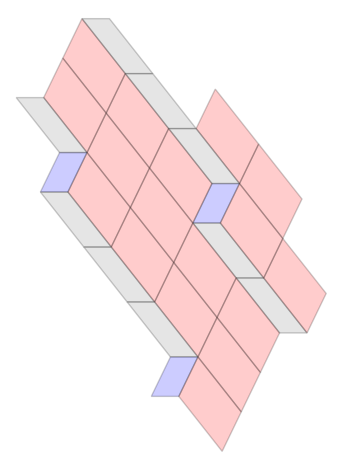

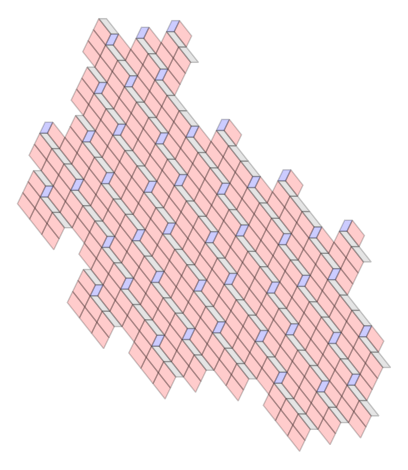

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', 3*lam^2 - lam - 1), ('1R', lam^2 + 3*lam + 1), ('1G', 2*lam^2 - 4*lam - 2), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1B', 8*lam + 3), ('1R', lam^2 - 2*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1B', -2*lam^2 - 3*lam - 1), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1G', lam^2 - 7*lam - 3), ('1G', -lam^2 + 5*lam + 2), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1G', -2*lam^2 - 3*lam - 1), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1B', 3*lam^2 - lam - 1), ('1R', -5*lam - 2), ('1R', 4*lam^2 - lam - 1), ('1R', 3*lam^2 - 4*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 + 2*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


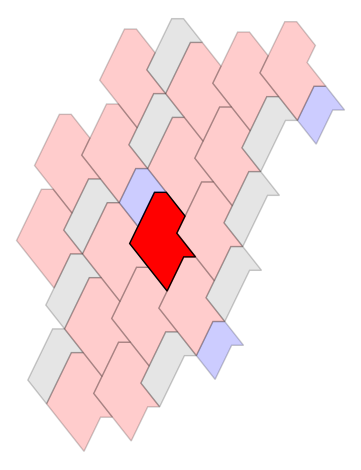

----------------------------------------------------------------------


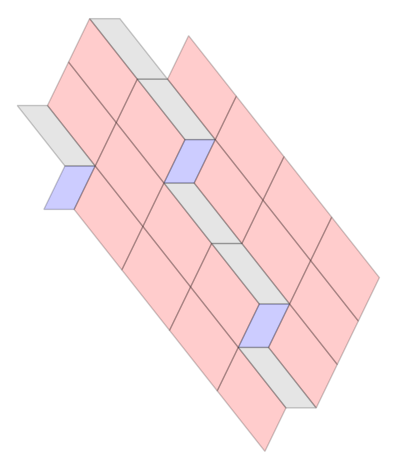

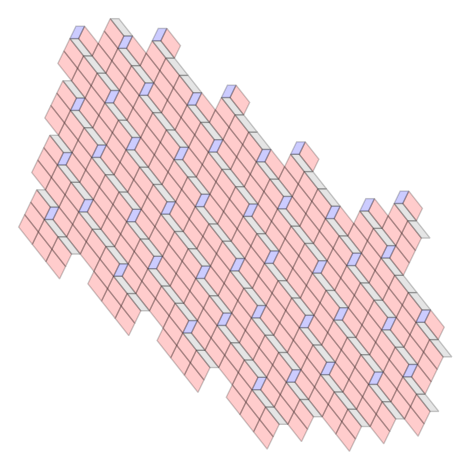

subbed_two_collar: ('1G', frozenset({('1B', -5*lam - 2), ('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -lam^2 + 7*lam + 3), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1R', 3*lam^2 + lam), ('1R', lam^2), ('1G', -4*lam^2 - 4*lam - 1), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1R', -4*lam^2 - 7*lam - 2), ('1G', -5*lam - 2), ('1R', lam^2 + 5*lam + 2), ('1B', lam^2 + 3*lam + 1), ('1G', -lam^2 - 8*lam - 3), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 + 3*lam + 1), ('1R', -3*lam^2 - 9*lam - 3), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 2*lam^2 + 3*lam + 1), ('1B', -4*lam^2 - 4*lam - 1), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


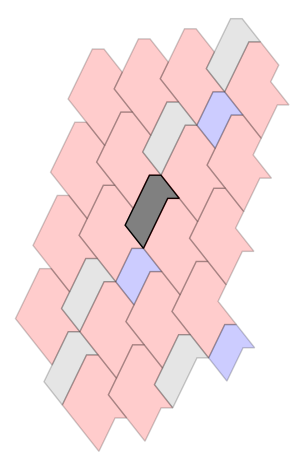

----------------------------------------------------------------------


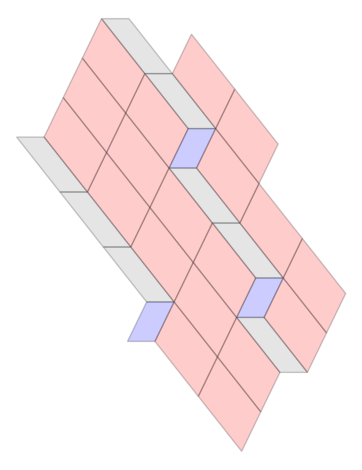

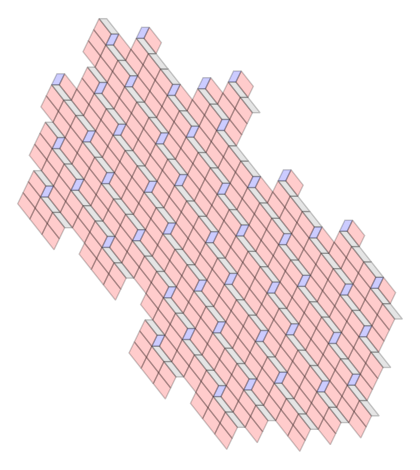

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -3*lam^2 - lam), ('1R', 2*lam^2 - 7*lam - 3), ('1R', 2*lam^2 - 2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', -lam^2 + 7*lam + 3), ('1B', -lam^2 + 5*lam + 2), ('1G', 2*lam^2 - 4*lam - 2), ('1R', 5*lam + 2), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1R', lam^2 + 8*lam + 3), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1G', lam^2 - 7*lam - 3), ('1G', -lam^2 + 5*lam + 2), ('1G', 3*lam^2 + 9*lam + 3), ('1B', 2*lam^2 - 4*lam - 2), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', -5*lam - 2), ('1R', 3*lam^2 - 4*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 + 2*lam + 1), ('1B', 3*lam^2 + 4*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


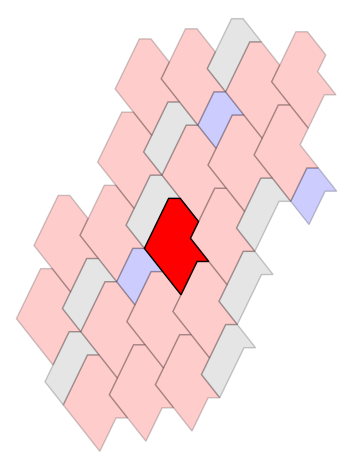

----------------------------------------------------------------------


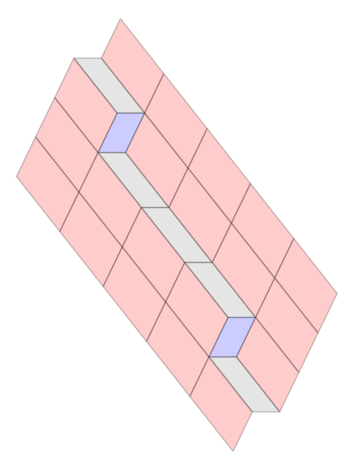

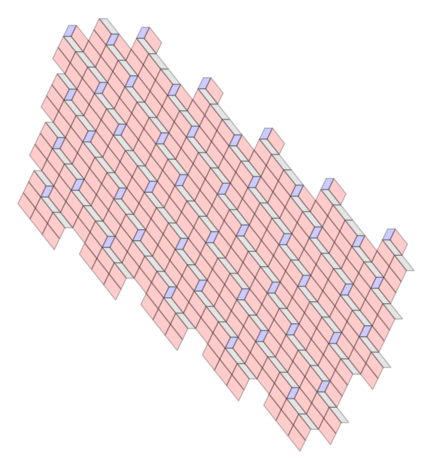

subbed_two_collar: ('1G', frozenset({('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -lam^2 + 7*lam + 3), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1R', -lam^2 - 6*lam - 2), ('1R', lam^2), ('1R', 3*lam^2 + lam), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1B', -lam^2 - 8*lam - 3), ('1G', -lam^2 - 3*lam - 1), ('1R', -5*lam^2 - 5*lam - 1), ('1R', -4*lam^2 - 7*lam - 2), ('1R', lam^2 + 5*lam + 2), ('1R', -lam^2 - 11*lam - 4), ('1B', lam^2 + 3*lam + 1), ('1G', -lam^2 - 8*lam - 3), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1G', lam^2 + 3*lam + 1), ('1R', -3*lam^2 - 9*lam - 3), ('1R', 2*lam^2 + 3*lam + 1), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


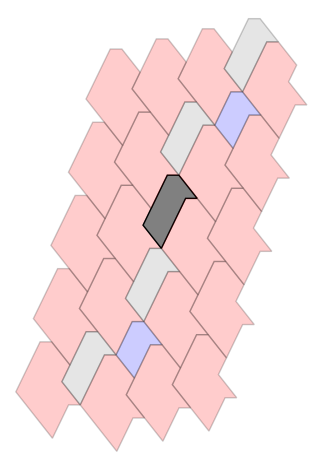

----------------------------------------------------------------------


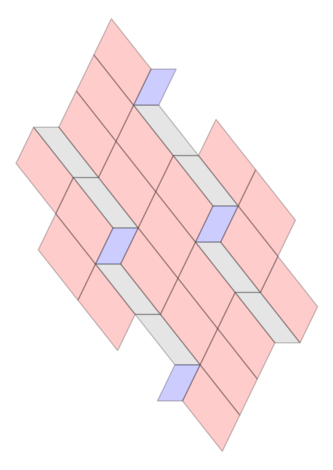

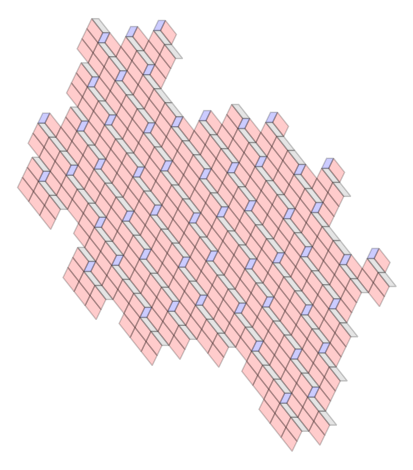

subbed_two_collar: ('1R', frozenset({('1G', 3*lam^2 - lam - 1), ('1G', 2*lam^2 - 4*lam - 2), ('1G', 3*lam^2 + 4*lam + 1), ('1B', 8*lam + 3), ('1R', lam^2 - 2*lam - 1), ('1R', 2*lam^2 + 6*lam + 2), ('1G', -2*lam^2 - 3*lam - 1), ('1R', 10*lam + 4), ('1R', -5*lam - 2), ('1B', 3*lam^2 - lam - 1), ('1R', -10*lam - 4), ('1R', 4*lam^2 - lam - 1), ('1R', 3*lam^2 - 4*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1R', lam^2 + 3*lam + 1), ('1B', 2*lam^2 - 9*lam - 4), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1R', 3*lam^2 + lam), ('1G', -lam^2 + 5*lam + 2), ('1R', -3*lam^2 - lam), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1R', -4*lam^2 - 4*lam - 1), ('1R', -4*lam^2 + lam + 1), ('1R', 0), ('1R', -3*lam^2 + 4*lam + 2), ('1B', -lam^2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', -lam^2 + 2*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


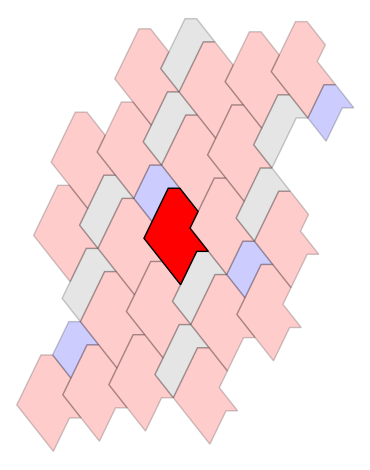

----------------------------------------------------------------------


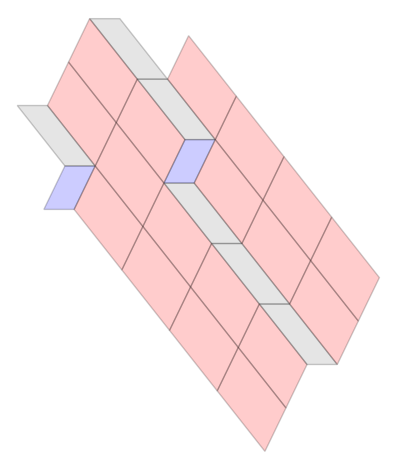

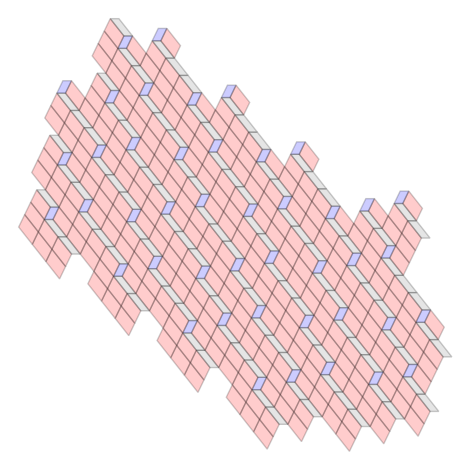

subbed_two_collar: ('1G', frozenset({('1B', -5*lam - 2), ('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -lam^2 + 7*lam + 3), ('1R', 5*lam + 2), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1G', 2*lam^2 + 6*lam + 2), ('1R', 3*lam^2 + lam), ('1R', lam^2), ('1G', -4*lam^2 - 4*lam - 1), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1R', -4*lam^2 - 7*lam - 2), ('1G', -5*lam - 2), ('1G', -lam^2 - 8*lam - 3), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 + 3*lam + 1), ('1R', -3*lam^2 - 9*lam - 3), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 2*lam^2 + 3*lam + 1), ('1B', -4*lam^2 - 4*lam - 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


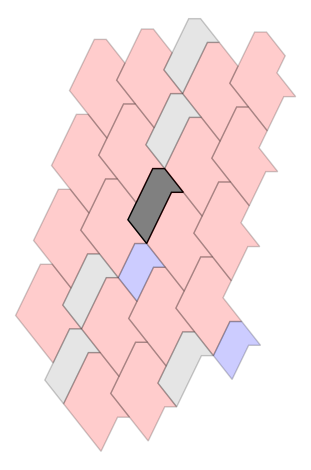

----------------------------------------------------------------------


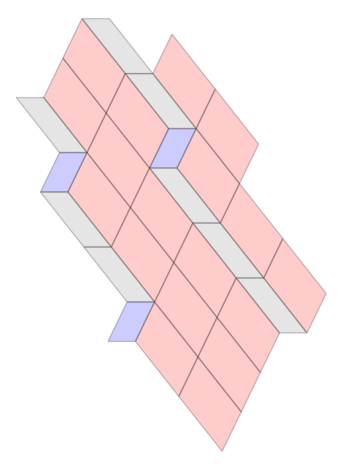

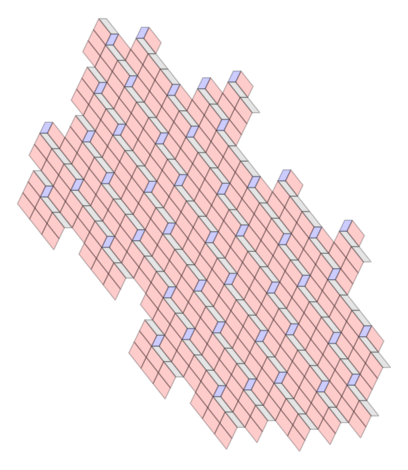

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1R', 2*lam^2 - 7*lam - 3), ('1R', 2*lam^2 - 2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', -lam^2 + 7*lam + 3), ('1B', -lam^2 + 5*lam + 2), ('1G', 2*lam^2 - 4*lam - 2), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1R', lam^2 + 8*lam + 3), ('1B', -2*lam^2 - 3*lam - 1), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1G', lam^2 - 7*lam - 3), ('1G', -lam^2 + 5*lam + 2), ('1B', 2*lam^2 - 4*lam - 2), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 4*lam^2 + 7*lam + 2), ('1G', -2*lam^2 - 3*lam - 1), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', -5*lam - 2), ('1R', 3*lam^2 - 4*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 + 2*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


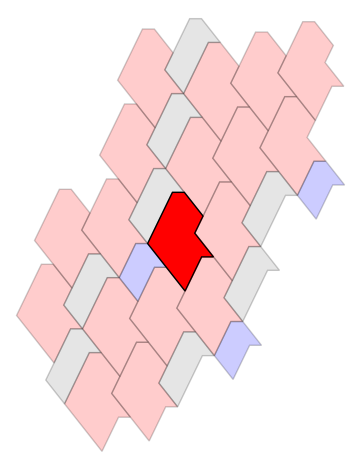

----------------------------------------------------------------------


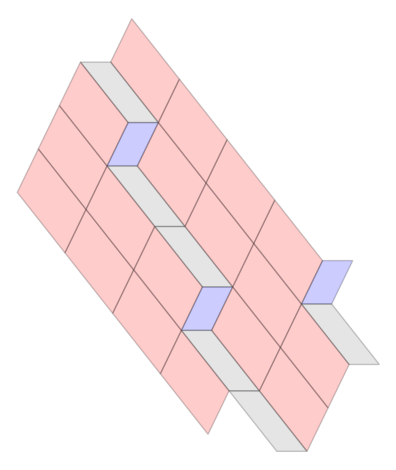

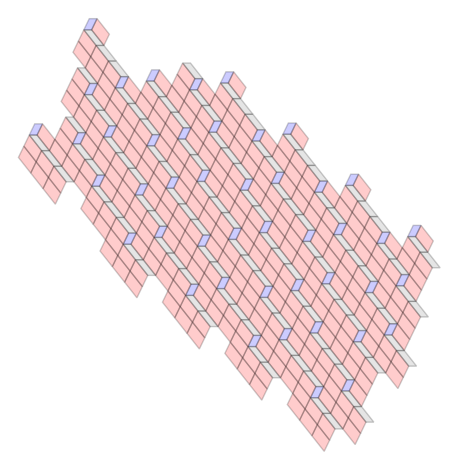

subbed_two_collar: ('1G', frozenset({('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1B', 4*lam^2 - lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1R', -lam^2 - 6*lam - 2), ('1R', lam^2), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1B', -lam^2 - 8*lam - 3), ('1R', -5*lam^2 - 5*lam - 1), ('1R', -4*lam^2 - 7*lam - 2), ('1R', lam^2 + 5*lam + 2), ('1R', -lam^2 - 11*lam - 4), ('1G', -lam^2 - 8*lam - 3), ('1G', 4*lam^2 + 4*lam + 1), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1G', 5*lam + 2), ('1R', 2*lam + 1), ('1R', 2*lam^2 + 3*lam + 1), ('1R', -3*lam^2 - 9*lam - 3), ('1G', -lam^2 - 3*lam - 1), ('1B', 0), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


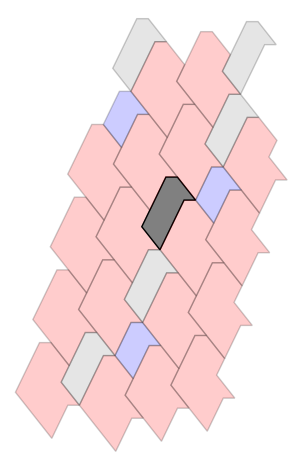

----------------------------------------------------------------------


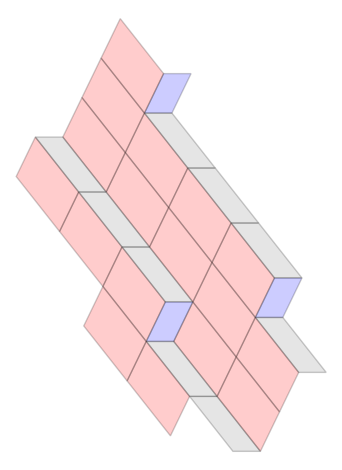

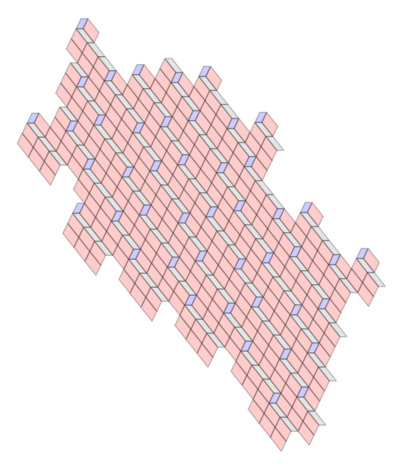

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1G', lam^2 + 11*lam + 4), ('1G', 3*lam^2 - lam - 1), ('1R', lam^2 + 3*lam + 1), ('1B', 2*lam^2 - 9*lam - 4), ('1G', 2*lam^2 - 4*lam - 2), ('1R', 5*lam + 2), ('1B', 3*lam + 1), ('1R', lam^2 - 2*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1R', -3*lam^2 - lam), ('1R', -2*lam^2 + 7*lam + 3), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1R', -2*lam^2 + 2*lam + 1), ('1G', -2*lam^2 - 3*lam - 1), ('1R', -4*lam^2 - 4*lam - 1), ('1R', 0), ('1B', 4*lam^2 + 2*lam), ('1R', -3*lam^2 + 4*lam + 2), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', -2*lam^2 - 6*lam - 2), ('1G', 4*lam^2 + 2*lam), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


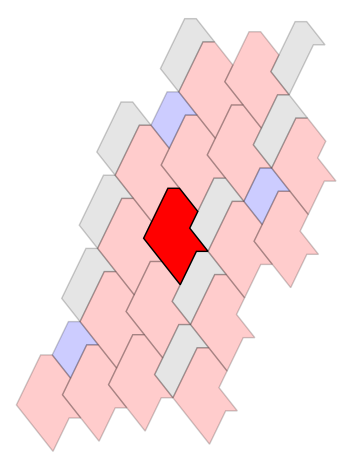

----------------------------------------------------------------------


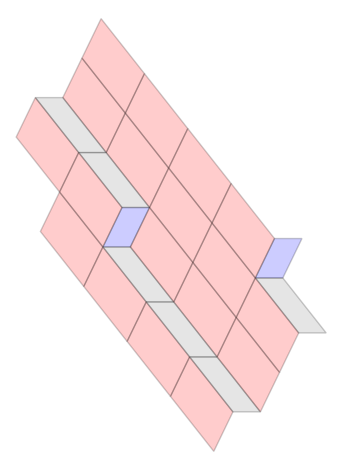

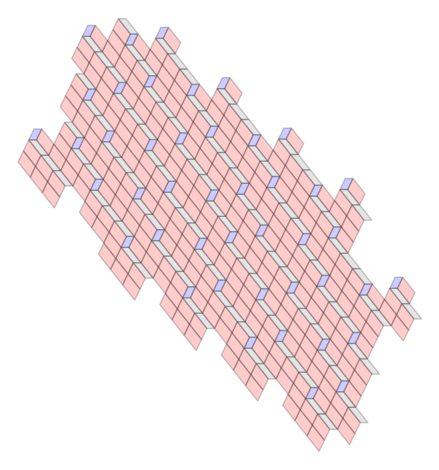

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1B', -2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', lam^2 - 2*lam - 1), ('1G', -lam^2 - 5*lam - 2), ('1B', 5*lam^2 - 1), ('1R', 3*lam^2 - lam - 1), ('1G', -2*lam - 1), ('1R', -3*lam^2 - lam), ('1R', 2*lam^2 - 4*lam - 2), ('1R', 2*lam^2 + 6*lam + 2), ('1G', lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1R', 3*lam^2 + 4*lam + 1), ('1R', -2*lam^2 + 2*lam + 1), ('1R', -3*lam^2 - 6*lam - 2), ('1R', 0), ('1R', -lam^2 + 5*lam + 2), ('1G', 2*lam^2 + 9*lam + 3), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1G', 5*lam^2 + 5*lam + 1), ('1R', 8*lam + 3), ('1R', -2*lam^2 - 3*lam - 1), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


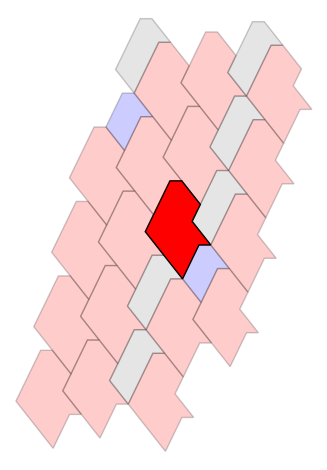

----------------------------------------------------------------------


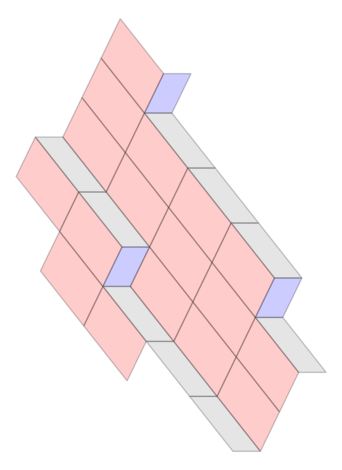

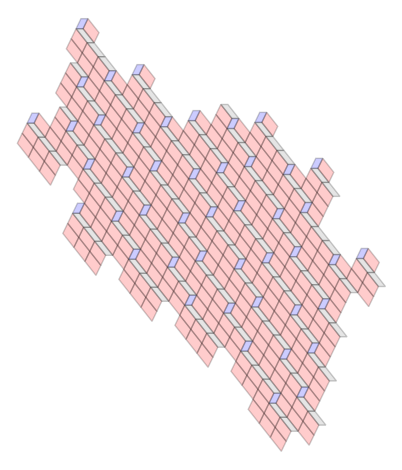

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1G', lam^2 + 11*lam + 4), ('1G', 3*lam^2 - lam - 1), ('1R', lam^2 + 3*lam + 1), ('1B', 2*lam^2 - 9*lam - 4), ('1G', 2*lam^2 - 4*lam - 2), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 - 2*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1G', -lam^2 + 5*lam + 2), ('1R', -3*lam^2 - lam), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1G', -2*lam^2 - 3*lam - 1), ('1R', -4*lam^2 - 4*lam - 1), ('1R', -4*lam^2 + lam + 1), ('1R', 0), ('1B', 4*lam^2 + 2*lam), ('1R', -3*lam^2 + 4*lam + 2), ('1R', -5*lam - 2), ('1B', -lam^2), ('1R', -10*lam - 4), ('1R', -2*lam^2 - 6*lam - 2), ('1G', 4*lam^2 + 2*lam), ('1R', -lam^2 + 2*lam + 1), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


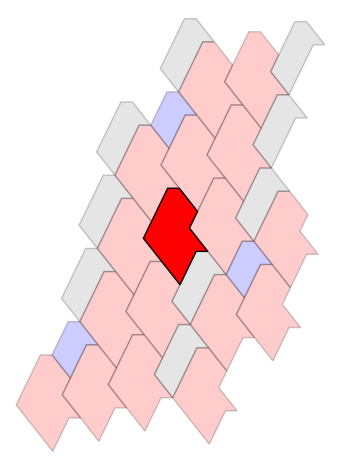

----------------------------------------------------------------------


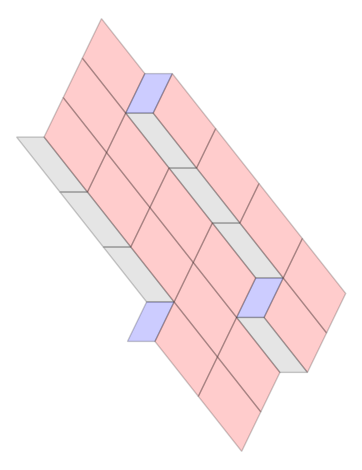

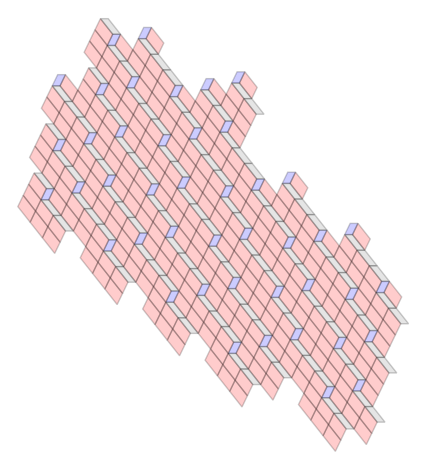

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -3*lam^2 - lam), ('1R', 2*lam^2 - 2*lam - 1), ('1B', lam^2 - 7*lam - 3), ('1R', -lam^2 + 7*lam + 3), ('1B', -lam^2 + 5*lam + 2), ('1R', lam^2 + 3*lam + 1), ('1R', 5*lam + 2), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1R', lam^2 + 8*lam + 3), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1G', -lam^2 + 5*lam + 2), ('1G', 3*lam^2 + 9*lam + 3), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 - 2*lam - 1), ('1B', 3*lam^2 + 4*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


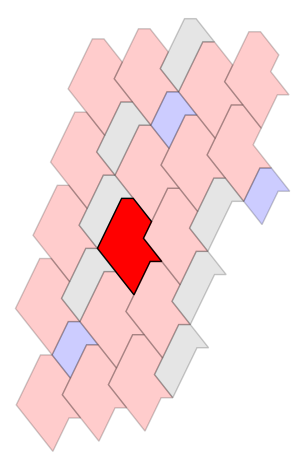

----------------------------------------------------------------------


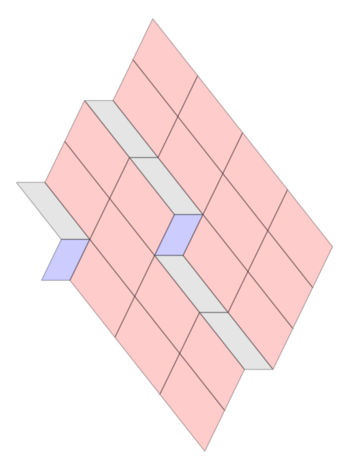

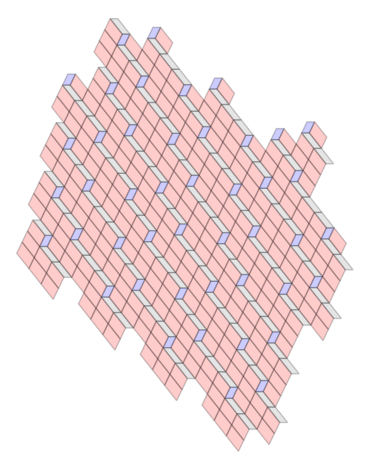

subbed_two_collar: ('1B', frozenset({('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 + 3*lam + 2), ('1R', -lam^2 + 7*lam + 3), ('1R', -4*lam^2 - 2*lam), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1G', -4*lam^2 + lam + 1), ('1R', -lam^2 - 6*lam - 2), ('1R', lam^2), ('1R', 3*lam^2 + lam), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1R', -3*lam^2 + 6*lam + 3), ('1R', -2*lam^2 + 9*lam + 4), ('1R', lam^2 + 5*lam + 2), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1G', 5*lam + 2), ('1R', 2*lam + 1), ('1R', 2*lam^2 + 3*lam + 1), ('1G', -lam^2 - 3*lam - 1), ('1B', -4*lam^2 + lam + 1), ('1B', 0), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


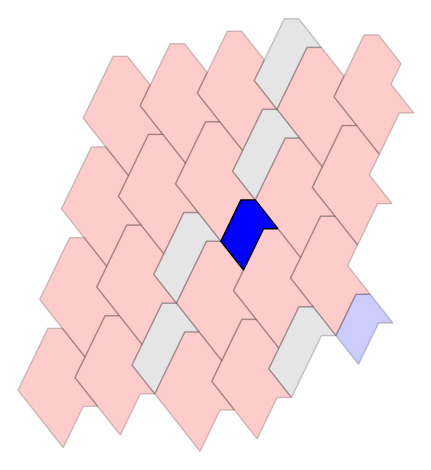

----------------------------------------------------------------------


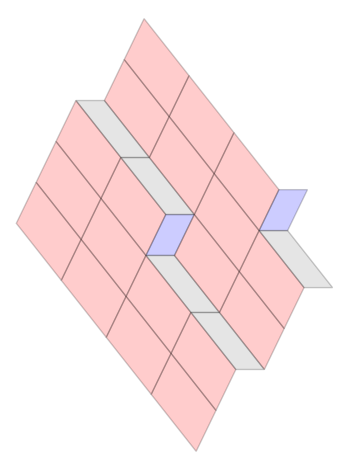

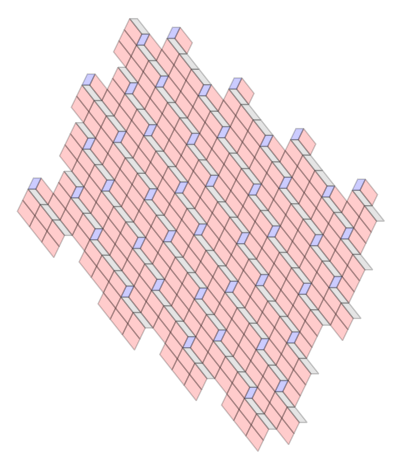

subbed_two_collar: ('1B', frozenset({('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 + 3*lam + 2), ('1R', -lam^2 + 7*lam + 3), ('1B', 4*lam^2 - lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1R', -lam^2 - 6*lam - 2), ('1R', lam^2), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1R', -3*lam^2 + 6*lam + 3), ('1R', -2*lam^2 + 9*lam + 4), ('1R', lam^2 + 5*lam + 2), ('1G', 4*lam^2 + 4*lam + 1), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', -5*lam^2 + 1), ('1G', 5*lam + 2), ('1R', 2*lam + 1), ('1R', 2*lam^2 + 3*lam + 1), ('1G', -lam^2 - 3*lam - 1), ('1B', 0), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


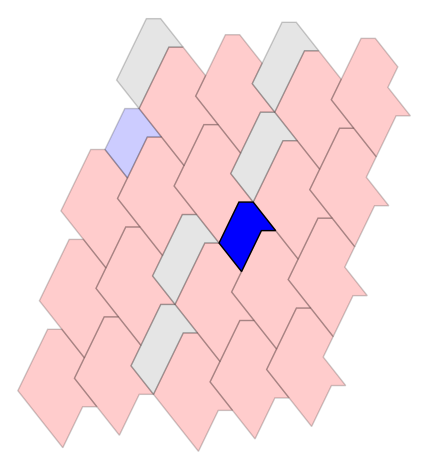

----------------------------------------------------------------------


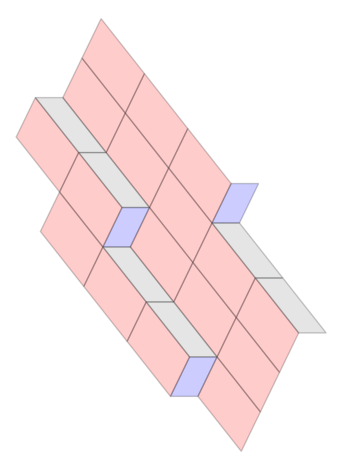

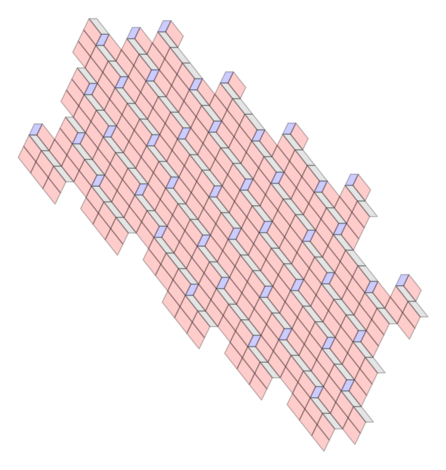

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1B', -2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1B', lam^2 + 6*lam + 2), ('1R', lam^2 - 2*lam - 1), ('1G', -lam^2 - 5*lam - 2), ('1R', lam^2 + 8*lam + 3), ('1G', -2*lam - 1), ('1B', 4*lam^2 - 3*lam - 2), ('1R', -3*lam^2 - lam), ('1R', 2*lam^2 - 4*lam - 2), ('1R', 2*lam^2 + 6*lam + 2), ('1G', lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1R', 3*lam^2 + 4*lam + 1), ('1R', -2*lam^2 + 2*lam + 1), ('1R', -3*lam^2 - 6*lam - 2), ('1R', 0), ('1R', -lam^2 + 5*lam + 2), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1G', 5*lam^2 + 5*lam + 1), ('1G', 4*lam^2 + 2*lam), ('1R', -2*lam^2 - 3*lam - 1), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


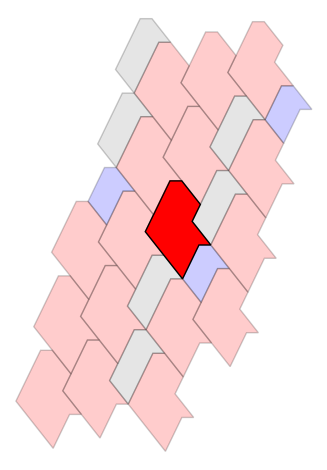

----------------------------------------------------------------------


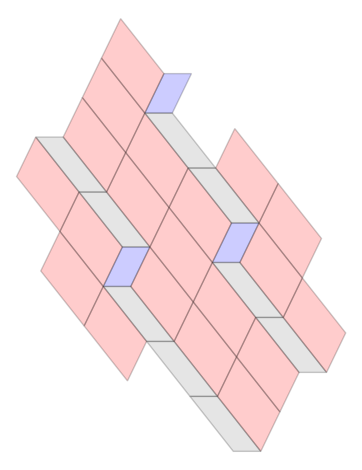

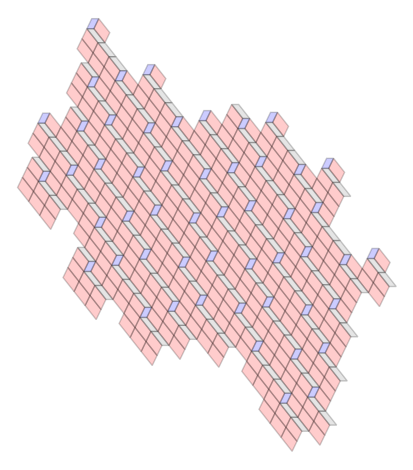

subbed_two_collar: ('1R', frozenset({('1G', lam^2 + 11*lam + 4), ('1G', 3*lam^2 - lam - 1), ('1G', 2*lam^2 - 4*lam - 2), ('1G', 3*lam^2 + 4*lam + 1), ('1R', lam^2 - 2*lam - 1), ('1R', 2*lam^2 + 6*lam + 2), ('1G', -2*lam^2 - 3*lam - 1), ('1R', -5*lam - 2), ('1B', 3*lam^2 - lam - 1), ('1R', -10*lam - 4), ('1R', 4*lam^2 - lam - 1), ('1R', 3*lam^2 - 4*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1R', lam^2 + 3*lam + 1), ('1B', 2*lam^2 - 9*lam - 4), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1R', 3*lam^2 + lam), ('1G', -lam^2 + 5*lam + 2), ('1R', -3*lam^2 - lam), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1R', -4*lam^2 - 4*lam - 1), ('1R', -4*lam^2 + lam + 1), ('1R', 0), ('1R', -3*lam^2 + 4*lam + 2), ('1B', -lam^2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', -lam^2 + 2*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


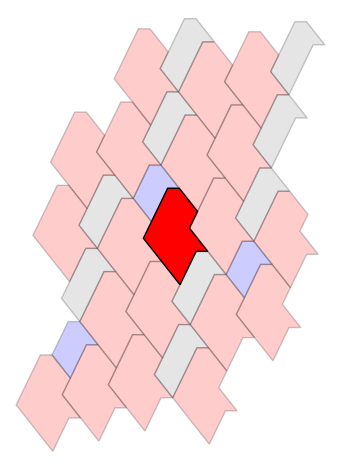

----------------------------------------------------------------------


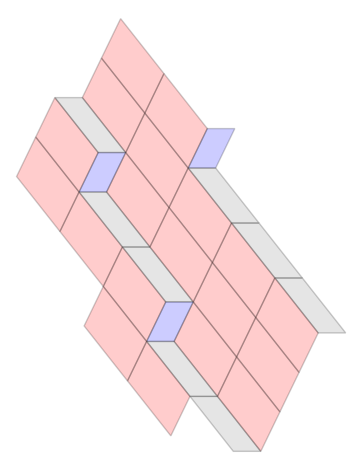

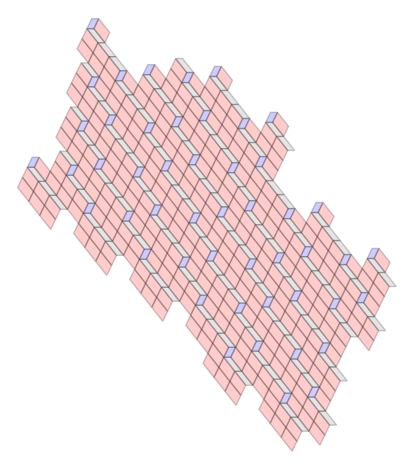

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1G', lam^2 + 11*lam + 4), ('1G', 3*lam^2 - lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', 5*lam + 2), ('1B', 3*lam + 1), ('1R', lam^2 - 2*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1G', -lam^2 - 5*lam - 2), ('1R', lam^2 + 8*lam + 3), ('1B', 3*lam^2 - 6*lam - 3), ('1R', -3*lam^2 - lam), ('1R', -2*lam^2 + 7*lam + 3), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1G', 8*lam + 3), ('1R', 3*lam^2 + 4*lam + 1), ('1R', -2*lam^2 + 2*lam + 1), ('1R', -3*lam^2 - 6*lam - 2), ('1R', -4*lam^2 - 4*lam - 1), ('1R', 0), ('1R', -3*lam^2 + 4*lam + 2), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1G', 5*lam^2 + 5*lam + 1), ('1B', -lam^2 - 5*lam - 2), ('1G', 4*lam^2 + 2*lam), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


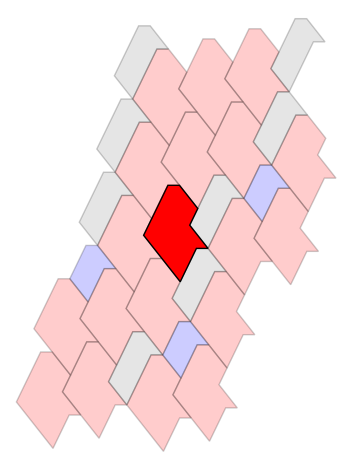

----------------------------------------------------------------------


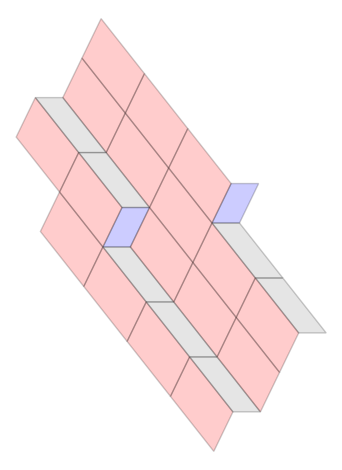

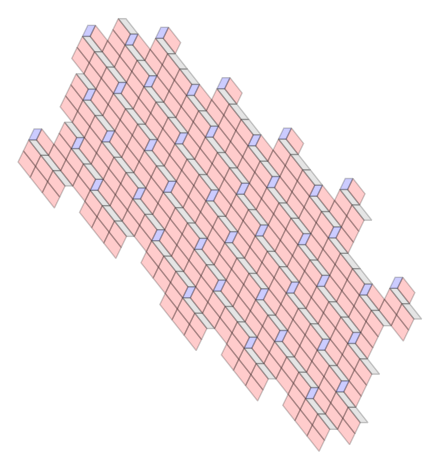

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1B', -2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', 8*lam + 3), ('1R', lam^2 - 2*lam - 1), ('1G', -lam^2 - 5*lam - 2), ('1G', -2*lam - 1), ('1B', 4*lam^2 - 3*lam - 2), ('1R', -3*lam^2 - lam), ('1R', 2*lam^2 - 4*lam - 2), ('1R', 2*lam^2 + 6*lam + 2), ('1G', lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1R', 3*lam^2 + 4*lam + 1), ('1R', -2*lam^2 + 2*lam + 1), ('1R', -3*lam^2 - 6*lam - 2), ('1R', 0), ('1R', -lam^2 + 5*lam + 2), ('1G', 2*lam^2 + 9*lam + 3), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1G', 5*lam^2 + 5*lam + 1), ('1G', 4*lam^2 + 2*lam), ('1R', -2*lam^2 - 3*lam - 1), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


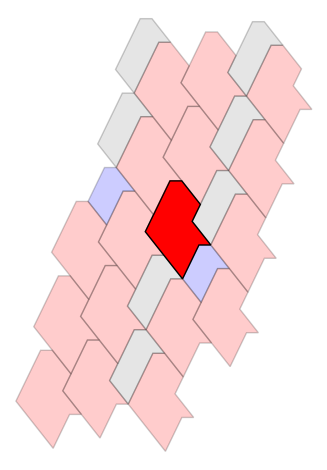

----------------------------------------------------------------------


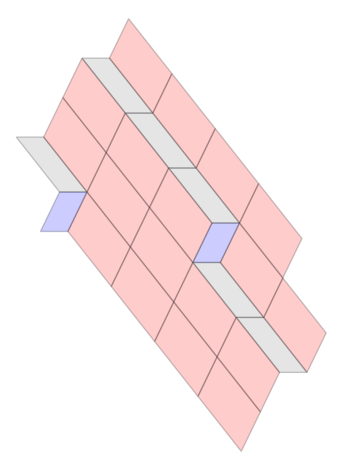

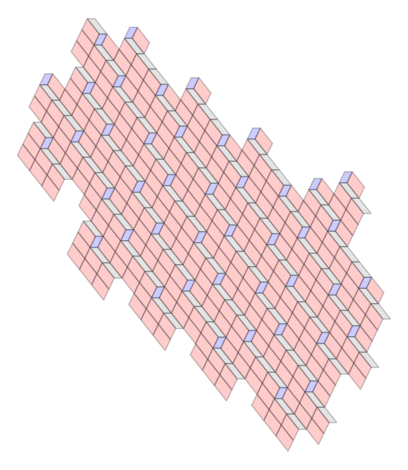

subbed_two_collar: ('1R', frozenset({('1G', -3*lam^2 - lam), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -lam^2 + 7*lam + 3), ('1R', 5*lam + 2), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 2*lam^2 + 6*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1R', 3*lam^2 + lam), ('1R', -8*lam - 3), ('1B', 2*lam^2 + lam), ('1R', -2*lam^2 + 4*lam + 2), ('1G', 3*lam^2 + 9*lam + 3), ('1G', -5*lam - 2), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1B', -3*lam^2 - lam), ('1R', 2*lam^2 + 3*lam + 1), ('1R', -2*lam^2 - 6*lam - 2), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 - 2*lam - 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


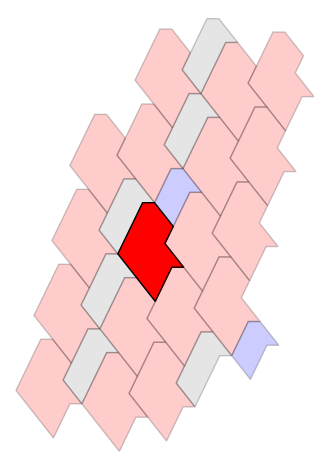

----------------------------------------------------------------------


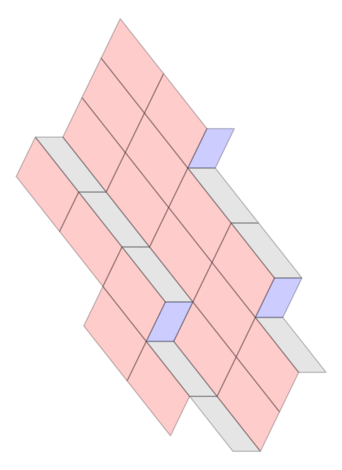

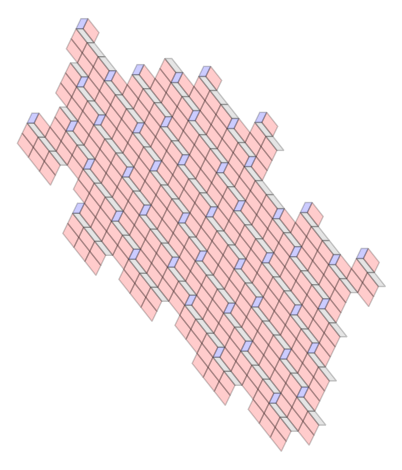

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1G', lam^2 + 11*lam + 4), ('1G', 3*lam^2 - lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', 5*lam + 2), ('1B', 3*lam + 1), ('1R', lam^2 - 2*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1B', 3*lam^2 - 6*lam - 3), ('1R', -3*lam^2 - lam), ('1R', -2*lam^2 + 7*lam + 3), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1R', -2*lam^2 + 2*lam + 1), ('1G', -2*lam^2 - 3*lam - 1), ('1R', -4*lam^2 - 4*lam - 1), ('1R', 0), ('1B', 4*lam^2 + 2*lam), ('1R', -3*lam^2 + 4*lam + 2), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1R', -2*lam^2 - 6*lam - 2), ('1G', 4*lam^2 + 2*lam), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


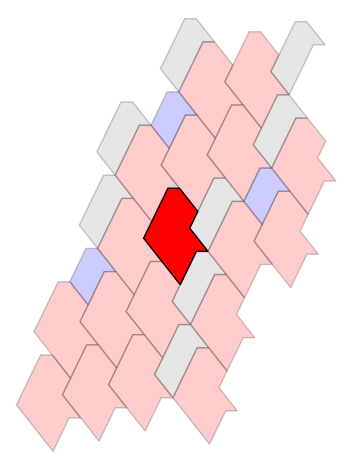

----------------------------------------------------------------------


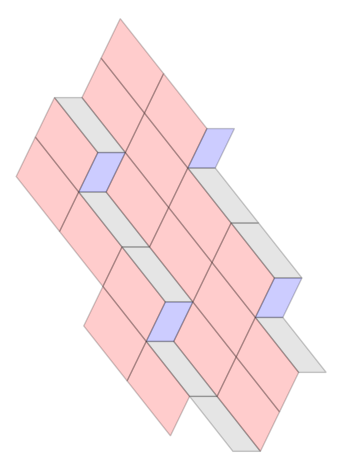

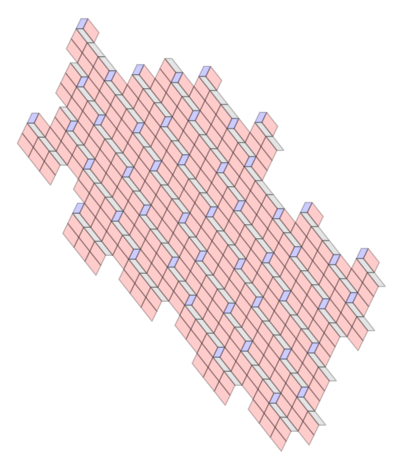

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1G', lam^2 + 11*lam + 4), ('1G', 3*lam^2 - lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', 5*lam + 2), ('1B', 3*lam + 1), ('1R', lam^2 - 2*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1G', -lam^2 - 5*lam - 2), ('1R', lam^2 + 8*lam + 3), ('1B', 3*lam^2 - 6*lam - 3), ('1R', -3*lam^2 - lam), ('1R', -2*lam^2 + 7*lam + 3), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1R', -2*lam^2 + 2*lam + 1), ('1R', -3*lam^2 - 6*lam - 2), ('1R', -4*lam^2 - 4*lam - 1), ('1R', 0), ('1B', 4*lam^2 + 2*lam), ('1R', -3*lam^2 + 4*lam + 2), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1B', -lam^2 - 5*lam - 2), ('1G', 4*lam^2 + 2*lam), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


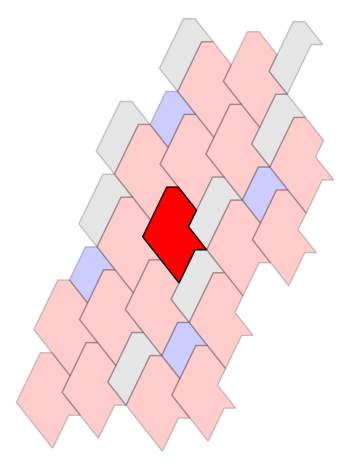

----------------------------------------------------------------------


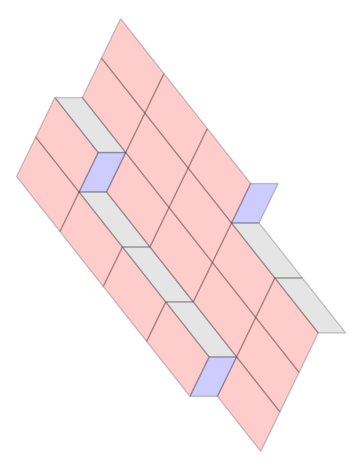

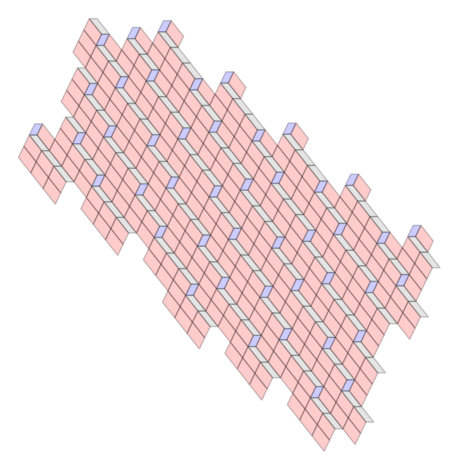

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1R', lam^2 + 3*lam + 1), ('1B', lam^2 + 6*lam + 2), ('1R', lam^2 - 2*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1G', -lam^2 - 5*lam - 2), ('1R', lam^2 + 8*lam + 3), ('1B', 4*lam^2 - 3*lam - 2), ('1R', -3*lam^2 - lam), ('1R', 2*lam^2 - 4*lam - 2), ('1R', 2*lam^2 + 6*lam + 2), ('1G', lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1R', 3*lam^2 + 4*lam + 1), ('1R', -2*lam^2 + 2*lam + 1), ('1R', -3*lam^2 - 6*lam - 2), ('1R', -4*lam^2 - 4*lam - 1), ('1R', 0), ('1R', -lam^2 + 5*lam + 2), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1G', 5*lam^2 + 5*lam + 1), ('1B', -lam^2 - 5*lam - 2), ('1G', 4*lam^2 + 2*lam), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


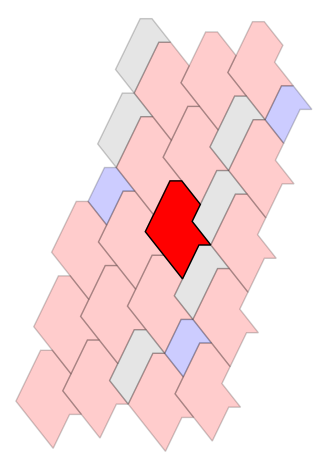

----------------------------------------------------------------------


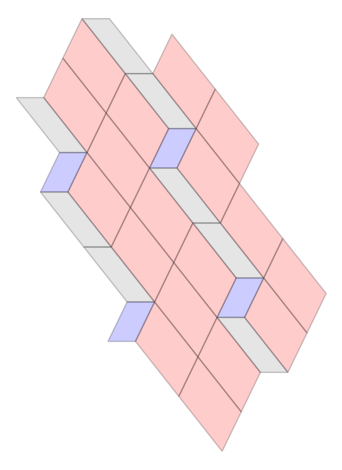

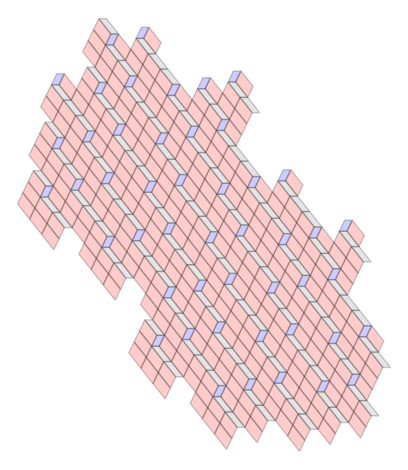

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1R', 2*lam^2 - 7*lam - 3), ('1R', 2*lam^2 - 2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', -lam^2 + 7*lam + 3), ('1B', -lam^2 + 5*lam + 2), ('1G', 2*lam^2 - 4*lam - 2), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1R', lam^2 + 8*lam + 3), ('1B', -2*lam^2 - 3*lam - 1), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1G', lam^2 - 7*lam - 3), ('1G', -lam^2 + 5*lam + 2), ('1G', 3*lam^2 + 9*lam + 3), ('1B', 2*lam^2 - 4*lam - 2), ('1R', 3*lam^2 + 6*lam + 2), ('1G', -2*lam^2 - 3*lam - 1), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', -5*lam - 2), ('1R', 3*lam^2 - 4*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 + 2*lam + 1), ('1B', 3*lam^2 + 4*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


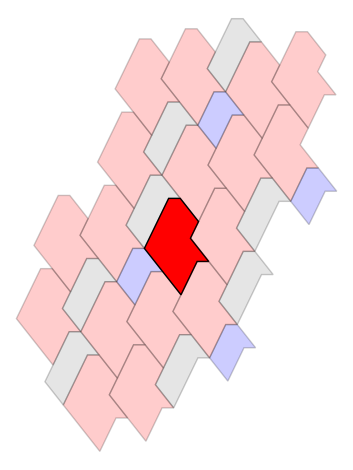

----------------------------------------------------------------------


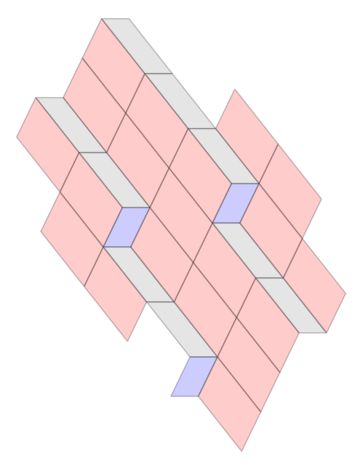

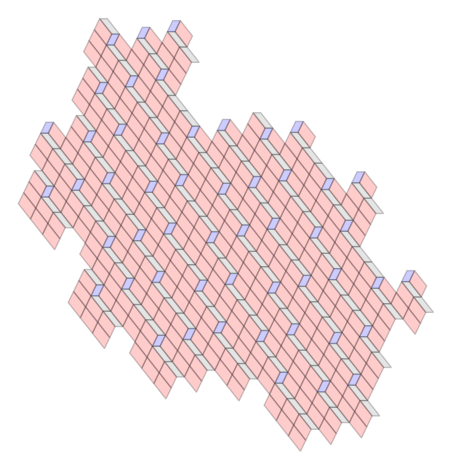

subbed_two_collar: ('1R', frozenset({('1G', 3*lam^2 - lam - 1), ('1G', 2*lam^2 - 4*lam - 2), ('1G', 3*lam^2 + 4*lam + 1), ('1B', 8*lam + 3), ('1R', lam^2 - 2*lam - 1), ('1R', 2*lam^2 + 6*lam + 2), ('1G', -2*lam^2 - 3*lam - 1), ('1R', 10*lam + 4), ('1R', -5*lam - 2), ('1B', 3*lam^2 - lam - 1), ('1R', 4*lam^2 - lam - 1), ('1R', 3*lam^2 - 4*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1R', lam^2 + 3*lam + 1), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1R', 3*lam^2 + lam), ('1G', lam^2 - 7*lam - 3), ('1G', -lam^2 + 5*lam + 2), ('1R', -3*lam^2 - lam), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1R', -4*lam^2 - 4*lam - 1), ('1R', -4*lam^2 + lam + 1), ('1R', 0), ('1R', -3*lam^2 + 4*lam + 2), ('1B', -lam^2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', -lam^2 + 2*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


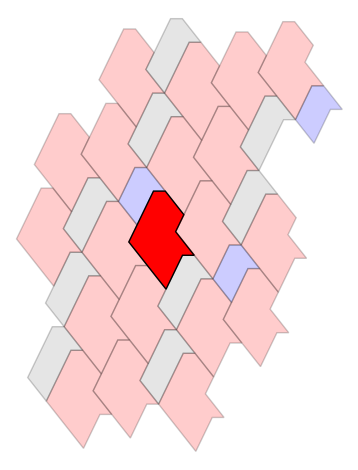

----------------------------------------------------------------------


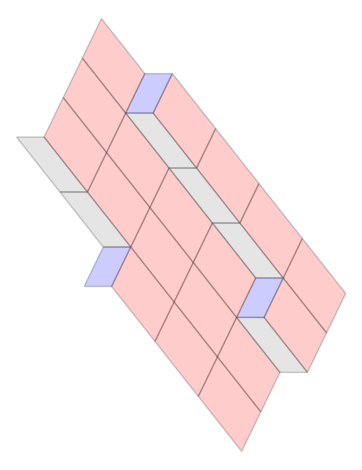

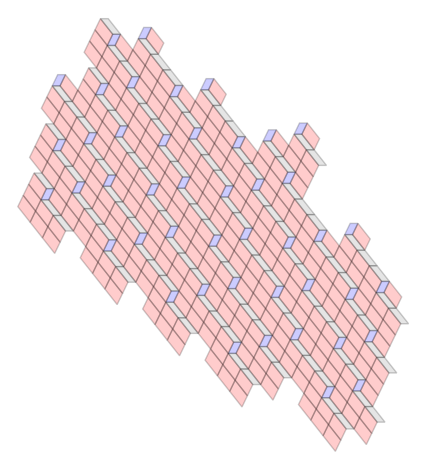

subbed_two_collar: ('1R', frozenset({('1B', -2*lam^2 + 2*lam + 1), ('1R', -lam^2 - 8*lam - 3), ('1G', -3*lam^2 - lam), ('1R', 2*lam^2 - 2*lam - 1), ('1B', lam^2 - 7*lam - 3), ('1R', -lam^2 + 7*lam + 3), ('1R', lam^2 + 3*lam + 1), ('1R', 5*lam + 2), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1R', lam^2 + 8*lam + 3), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1R', -2*lam^2 + 4*lam + 2), ('1G', 3*lam^2 + 9*lam + 3), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 - 2*lam - 1), ('1B', 3*lam^2 + 4*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


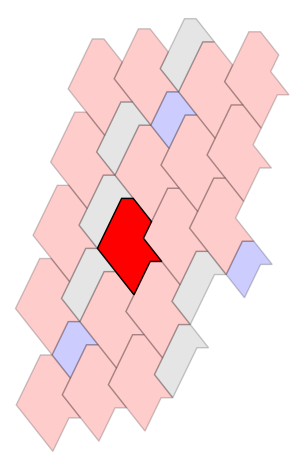

----------------------------------------------------------------------


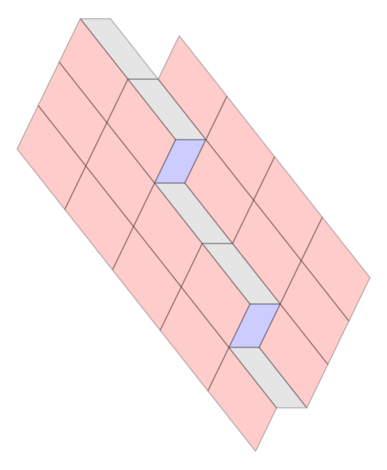

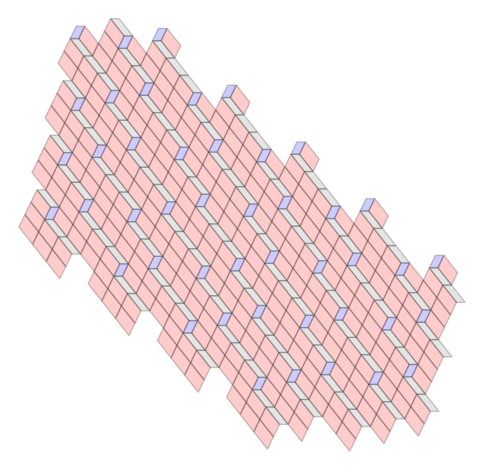

subbed_two_collar: ('1G', frozenset({('1B', -5*lam - 2), ('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -lam^2 + 7*lam + 3), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1R', 3*lam^2 + lam), ('1R', lam^2), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1R', -5*lam^2 - 5*lam - 1), ('1R', -4*lam^2 - 7*lam - 2), ('1G', -5*lam - 2), ('1R', lam^2 + 5*lam + 2), ('1B', lam^2 + 3*lam + 1), ('1G', -lam^2 - 8*lam - 3), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1G', lam^2 + 3*lam + 1), ('1R', -3*lam^2 - 9*lam - 3), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 2*lam^2 + 3*lam + 1), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


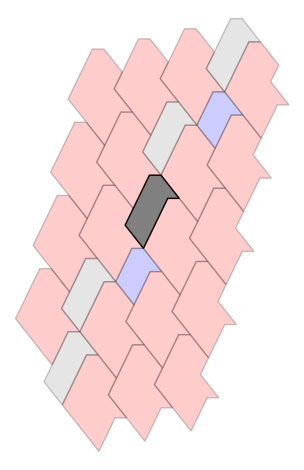

----------------------------------------------------------------------


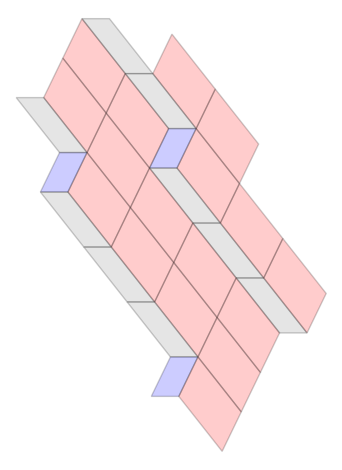

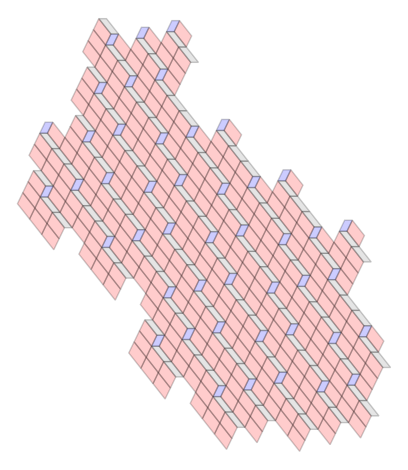

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1R', 2*lam^2 - 7*lam - 3), ('1R', 2*lam^2 - 2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1G', 2*lam^2 - 4*lam - 2), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1B', 8*lam + 3), ('1R', lam^2 + 8*lam + 3), ('1B', -2*lam^2 - 3*lam - 1), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1G', lam^2 - 7*lam - 3), ('1G', -lam^2 + 5*lam + 2), ('1B', 2*lam^2 - 4*lam - 2), ('1R', 2*lam^2 + 6*lam + 2), ('1G', 4*lam^2 + 7*lam + 2), ('1G', 8*lam + 3), ('1G', -2*lam^2 - 3*lam - 1), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', -5*lam - 2), ('1R', 3*lam^2 - 4*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1R', -lam^2 + 2*lam + 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


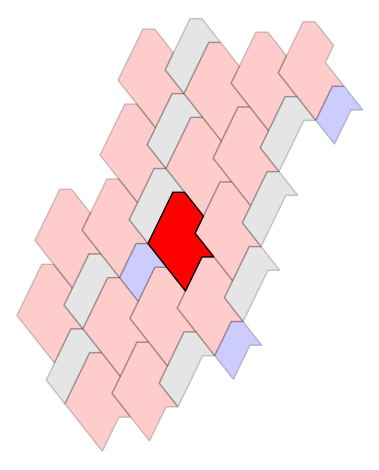

----------------------------------------------------------------------


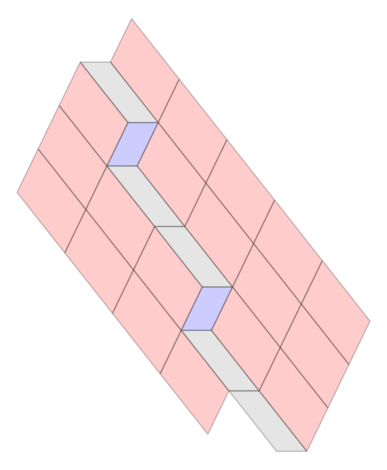

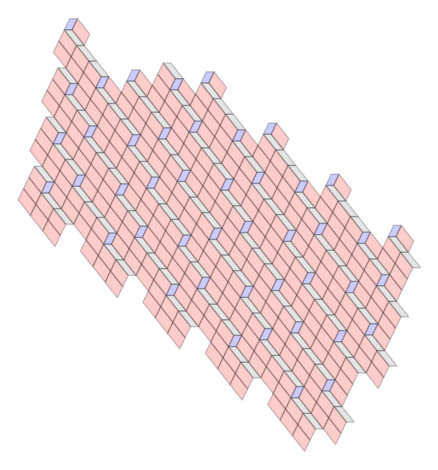

subbed_two_collar: ('1G', frozenset({('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1R', -lam^2 - 6*lam - 2), ('1R', lam^2), ('1R', 3*lam^2 + lam), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1B', -lam^2 - 8*lam - 3), ('1R', -5*lam^2 - 5*lam - 1), ('1R', -4*lam^2 - 7*lam - 2), ('1R', lam^2 + 5*lam + 2), ('1R', -lam^2 - 11*lam - 4), ('1G', -lam^2 - 8*lam - 3), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1G', 5*lam + 2), ('1R', 2*lam + 1), ('1R', 2*lam^2 + 3*lam + 1), ('1R', -3*lam^2 - 9*lam - 3), ('1G', -lam^2 - 3*lam - 1), ('1B', 0), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


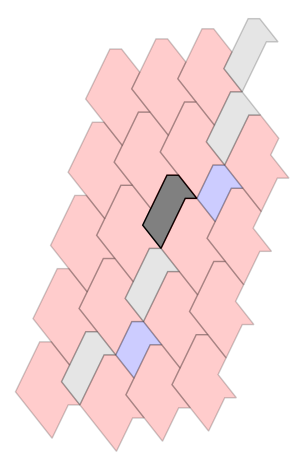

----------------------------------------------------------------------


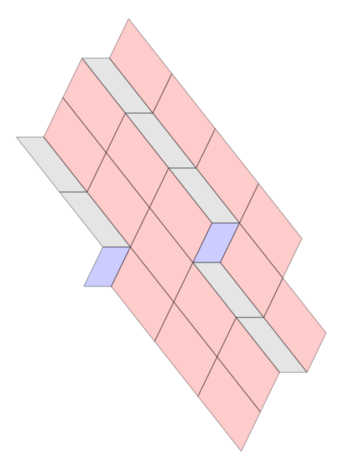

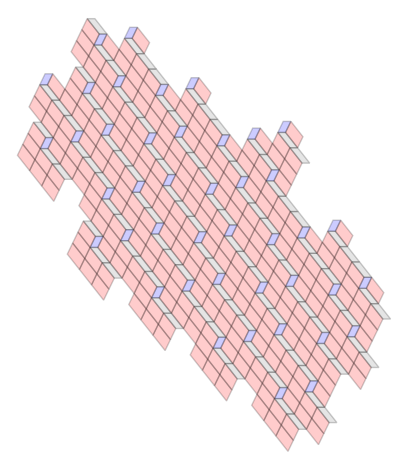

subbed_two_collar: ('1R', frozenset({('1B', -2*lam^2 + 2*lam + 1), ('1G', -3*lam^2 - lam), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -lam^2 + 7*lam + 3), ('1R', 5*lam + 2), ('1R', -3*lam^2 - 4*lam - 1), ('1G', 2*lam^2 + 6*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1R', -8*lam - 3), ('1B', 2*lam^2 + lam), ('1R', -2*lam^2 + 4*lam + 2), ('1G', 3*lam^2 + 9*lam + 3), ('1G', -5*lam - 2), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', 2*lam^2 + 3*lam + 1), ('1R', -2*lam^2 - 6*lam - 2), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 - 2*lam - 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


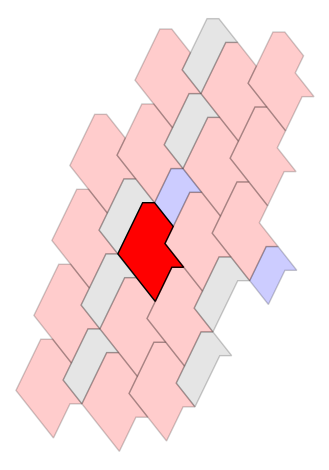

----------------------------------------------------------------------


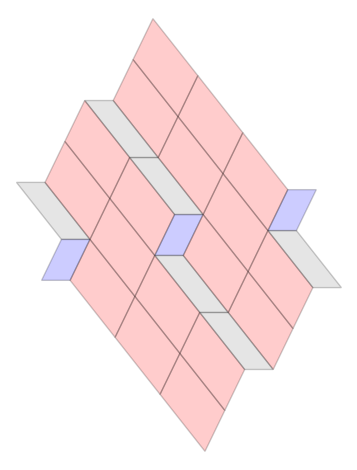

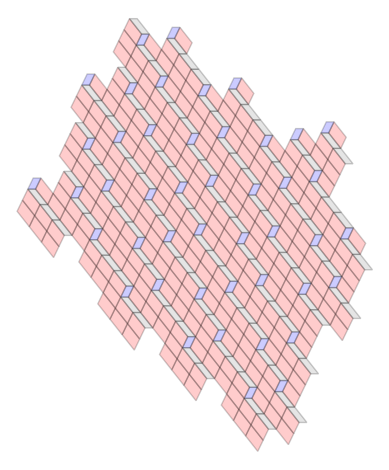

subbed_two_collar: ('1B', frozenset({('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', -4*lam^2 + 3*lam + 2), ('1R', -lam^2 + 7*lam + 3), ('1B', 4*lam^2 - lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1G', -4*lam^2 + lam + 1), ('1R', -lam^2 - 6*lam - 2), ('1R', lam^2), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1R', -3*lam^2 + 6*lam + 3), ('1R', -2*lam^2 + 9*lam + 4), ('1R', lam^2 + 5*lam + 2), ('1G', 4*lam^2 + 4*lam + 1), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1G', 5*lam + 2), ('1R', 2*lam + 1), ('1R', 2*lam^2 + 3*lam + 1), ('1G', -lam^2 - 3*lam - 1), ('1B', -4*lam^2 + lam + 1), ('1B', 0), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


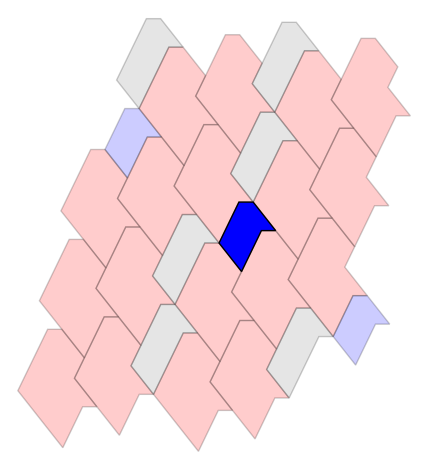

----------------------------------------------------------------------


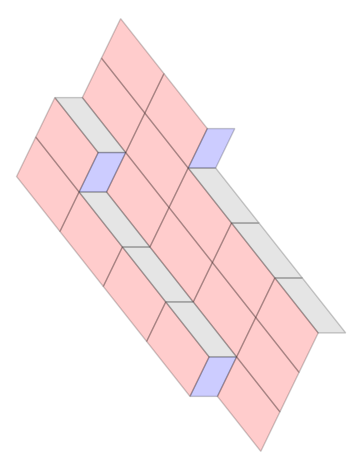

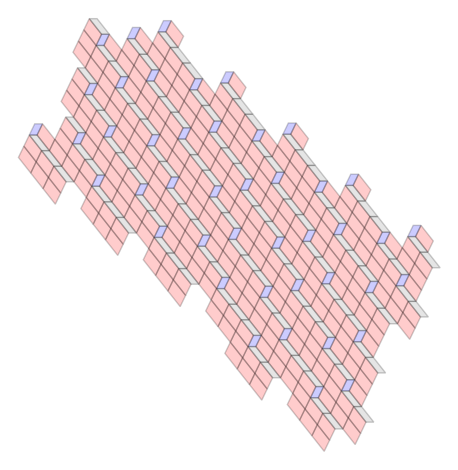

subbed_two_collar: ('1R', frozenset({('1R', -lam^2 - 8*lam - 3), ('1G', -lam^2), ('1G', 3*lam^2 - lam - 1), ('1R', lam^2 + 3*lam + 1), ('1B', lam^2 + 6*lam + 2), ('1R', lam^2 - 2*lam - 1), ('1R', -lam^2 - 3*lam - 1), ('1G', -lam^2 - 5*lam - 2), ('1R', lam^2 + 8*lam + 3), ('1B', 3*lam^2 - 6*lam - 3), ('1R', -3*lam^2 - lam), ('1R', 2*lam^2 + 6*lam + 2), ('1G', lam^2 + 6*lam + 2), ('1G', 3*lam + 1), ('1R', 3*lam^2 + 4*lam + 1), ('1R', -2*lam^2 + 2*lam + 1), ('1R', -3*lam^2 - 6*lam - 2), ('1R', -4*lam^2 - 4*lam - 1), ('1R', 0), ('1R', -lam^2 + 5*lam + 2), ('1R', -5*lam - 2), ('1R', -10*lam - 4), ('1R', lam^2 - 7*lam - 3), ('1G', 5*lam^2 + 5*lam + 1), ('1B', -lam^2 - 5*lam - 2), ('1G', 4*lam^2 + 2*lam), ('1R', 2*lam^2 + lam)}))
subbed lvl 0 two collar is a lvl 1 two collar


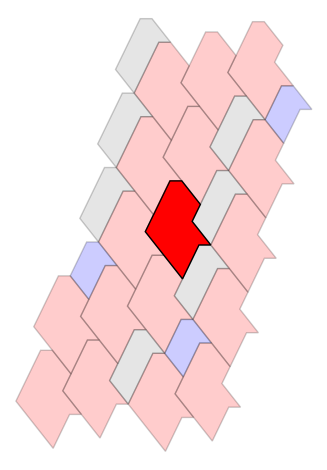

----------------------------------------------------------------------


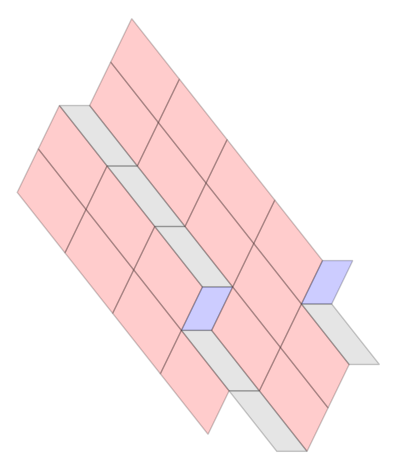

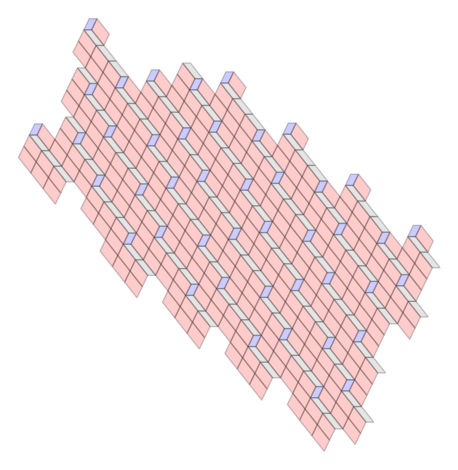

subbed_two_collar: ('1G', frozenset({('1R', -3*lam - 1), ('1R', 2*lam^2 - 2*lam - 1), ('1B', 4*lam^2 - lam - 1), ('1R', -4*lam^2 - 2*lam), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -3*lam^2 + lam + 1), ('1G', 0), ('1R', -lam^2 - 6*lam - 2), ('1R', lam^2), ('1R', -8*lam - 3), ('1R', -2*lam^2 + 4*lam + 2), ('1R', -5*lam^2 - 5*lam - 1), ('1R', -4*lam^2 - 7*lam - 2), ('1R', lam^2 + 5*lam + 2), ('1R', -lam^2 - 11*lam - 4), ('1G', -2*lam^2 - 6*lam - 2), ('1G', 4*lam^2 + 4*lam + 1), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', -2*lam^2 - 9*lam - 3), ('1R', 2*lam + 1), ('1G', 5*lam + 2), ('1R', 2*lam^2 + 3*lam + 1), ('1G', -lam^2 - 3*lam - 1), ('1B', 0), ('1G', lam^2 + 8*lam + 3)}))
subbed lvl 0 two collar is a lvl 1 two collar


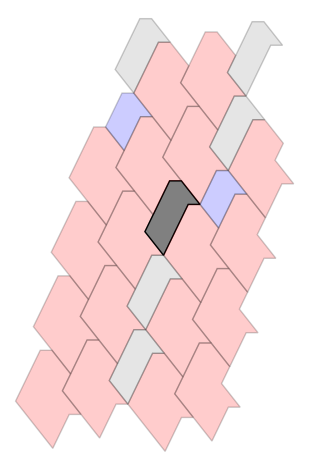

----------------------------------------------------------------------


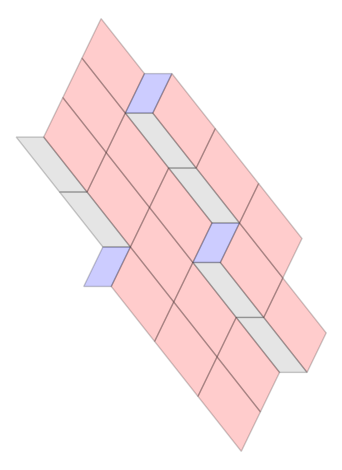

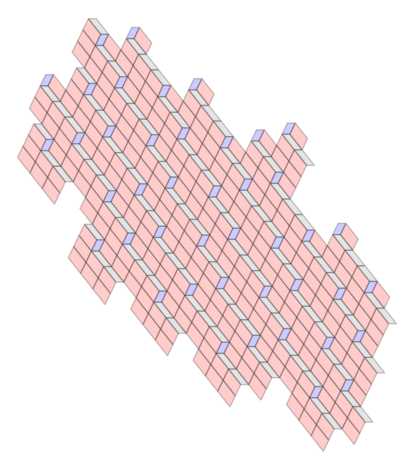

subbed_two_collar: ('1R', frozenset({('1B', -2*lam^2 + 2*lam + 1), ('1R', -lam^2 - 8*lam - 3), ('1G', -3*lam^2 - lam), ('1R', 2*lam^2 - 2*lam - 1), ('1B', lam^2 - 7*lam - 3), ('1R', -lam^2 + 7*lam + 3), ('1R', 5*lam + 2), ('1R', -3*lam^2 - 4*lam - 1), ('1G', 2*lam^2 + 6*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1R', lam^2 + 8*lam + 3), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1B', 2*lam^2 + lam), ('1R', -2*lam^2 + 4*lam + 2), ('1G', 3*lam^2 + 9*lam + 3), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', 10*lam + 4), ('1R', 0), ('1R', -2*lam^2 - lam), ('1R', lam^2 - 5*lam - 2), ('1R', 2*lam^2 + 3*lam + 1), ('1R', -2*lam^2 - 6*lam - 2), ('1R', -lam^2 + 2*lam + 1), ('1G', lam^2 - 2*lam - 1)}))
subbed lvl 0 two collar is a lvl 1 two collar


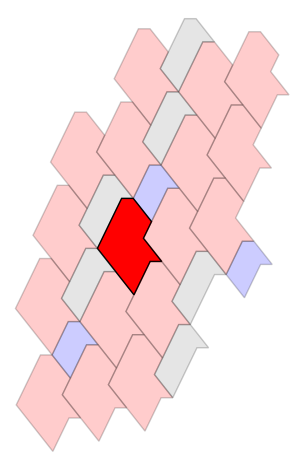

----------------------------------------------------------------------
('1R', frozenset({('1G', -3*lam^2 - lam), ('1B', lam^2 - 7*lam - 3), ('1R', -3*lam^2 - 4*lam - 1), ('1G', 3*lam^2 + 4*lam + 1), ('1R', -2*lam^2 + 4*lam + 2), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', -2*lam^2 - lam), ('1R', 4*lam^2 - lam - 1), ('1R', 3*lam^2 - 4*lam - 2), ('1G', lam^2 - 2*lam - 1), ('1B', 3*lam^2 + 4*lam + 1), ('1R', 2*lam^2 - 2*lam - 1), ('1R', lam^2 + 3*lam + 1), ('1R', 5*lam + 2), ('1R', -lam^2 - 3*lam - 1), ('1G', -2*lam^2 + 2*lam + 1), ('1R', 3*lam^2 + lam), ('1R', -4*lam^2 + lam + 1), ('1R', 0), ('1R', lam^2 - 5*lam - 2), ('1R', -2*lam^2 - 6*lam - 2), ('1R', -lam^2 + 2*lam + 1)}))
('1R', frozenset({('1G', -3*lam^2 - lam), ('1R', -3*lam^2 - 4*lam - 1), ('1R', -2*lam^2 + 4*lam + 2), ('1R', 3*lam^2 + 6*lam + 2), ('1G', 2*lam^2 + lam), ('1R', -2*lam^2 - lam), ('1R', 4*lam^2 - lam - 1), ('1R', 3*lam^2 - 4*lam - 2), ('1R', 4*lam^2 + 4*lam + 1), ('1G', lam^2 - 2*lam - 1), ('1R', 2*la

In [30]:
# test = Patch_2()
# test.add_prototile_code('1R', 0)
# show(test.graph_patch())
# for i in range(3):
#     test.substitute_patch()
#     show(test.graph_patch())

# test = Patch_2()
# test.add_prototile_code('1G', 0)
# show(test.graph_patch())
# for i in range(3):
#     test.substitute_patch()
#     show(test.graph_patch())

# test = Patch_2()
# test.add_prototile_code('1B', 0)
# show(test.graph_patch())
# for i in range(3):
#     test.substitute_patch()
#     show(test.graph_patch())

# test.remove_edge(k=2)
# show(test.graph_patch())

# half_collars = test.find_suptile_half_collars(k=2)
# for half_collar in half_collars:
#     print(half_collar)
#     test.display_half_collar(half_collar, 2)

# GETTING THE PICKLES
# with open("kenyon_uncollared_APlvl1_two_collars.pickle", "rb") as f:
#     uncollared_lvl_1_two_collars = pickle.load(f)

# with open("kenyon_uncollared_APlvl1_two_collars_code_to_list.pickle", "rb") as f:
#     uncollared_lvl_1_collar_code_to_list_dict = pickle.load(f)

# with open("kenyon_uncollared_APlvl1_two_collars_list_to_code.pickle", "rb") as f:
#     uncollared_lvl_1_collar_list_to_code_dict = pickle.load(f)

tile_types = ['R', 'G']

print(len(uncollared_lvl_1_two_collars))
print(len(half_collars))

# # FINDING 2 COLLARS
# num_collars, collars = find_suptile_collars_iteratively(8, start_level=0, starting_collars_set=None, k=2)

# # GRAPHING THEM
# test = Patch_2()
# for collar in collars:
#     print(collar)
#     show(test.display_collar(collar))

# # GENERATING DICTS AND PICKLING
# generate_code_dicts(collars, 'uncollared_APlvl1_two_collars')

# # GETTING THE PICKLES
# with open("kenyon_uncollared_APlvl1_two_collars.pickle", "rb") as f:
#     uncollared_lvl_1_two_collars = pickle.load(f)

# with open("kenyon_uncollared_APlvl1_two_collars_code_to_list.pickle", "rb") as f:
#     uncollared_lvl_1_collar_code_to_list_dict = pickle.load(f)

# with open("kenyon_uncollared_APlvl1_two_collars_list_to_code.pickle", "rb") as f:
#     uncollared_lvl_1_collar_list_to_code_dict = pickle.load(f)

# print(f'there are {len(uncollared_lvl_1_two_collars)} two collars')

# # FINDING 2.5 COLLARS
# num_half_collars, half_collars = find_suptile_half_collars_iteratively(8, start_level=2, starting_collars_set=None, k=2)

# print(f'there are {num_half_collars} 2.5 collars')

# # STORING IN PICKLE
# with open("kenyon_uncollared_APlvl1_2.5_collars.pickle", "wb") as f:
#         pickle.dump(half_collars, f)

# # GRAPHING THEM
# test = Patch_2()
# for half_collar in half_collars:
#     print(half_collar)
#     test.display_half_collar(half_collar, 2, True)

for two_collar in two_collars:
    test = Patch()
    for located_tile in two_collar[1]:
        test.add_prototile_code(located_tile[0], located_tile[1])
    show(test.graph_patch())
    test.substitute_patch()
    test.substitute_patch()
    test.substitute_patch()
    show(test.graph_patch())

    center_tile = two_collar[0]
    subbed_decoration = set()
    for located_tile in two_collar[1]:
        subbed_located_tile = ('1' + located_tile[0], located_tile[1]*lam**2)
        lvl_0_NF = located_tile[1].parent()
        subbed_decoration.add(subbed_located_tile)
    subbed_two_collar = ('1' + center_tile, frozenset(subbed_decoration))
    print(f'subbed_two_collar: {subbed_two_collar}')
    if subbed_two_collar in uncollared_lvl_1_two_collars or True:
        print('subbed lvl 0 two collar is a lvl 1 two collar')
        test_2 = Patch_2()
        show(test_2.display_collar(subbed_two_collar))
    print('----------------------------------------------------------------------')
        
for collar in uncollared_lvl_1_two_collars:
    print(collar)
    lvl_1_NF = list(collar[1])[0][1].parent()

print(lvl_1_NF is lvl_0_NF)
#     test = Patch_2()
#     show(test.display_collar(collar))
#     # for located_tile in two_collar[1]:
#     #     test.add_prototile_code(located_tile[0], located_tile[1])
#     # # show(test.graph_patch())
#     # test.substitute_patch()
#     # test.substitute_patch()
#     # show(test.graph_patch())

# Boundary Map (and other?) functions

In [15]:
# choosing a canonical orientation for one-cells
def canonical_orientation_for_one_cell(one_cell):
    """
    Choose a global orientation for a 1-cell that may be a single edge or an equivalence class of several edges.
    Returns an ordered pair (v1, v2) in global coordinates.
    """
    cell = list(one_cell[0])

    # Case A: cell itself is a single undirected edge: frozenset({v1, v2})
    if len(cell) == 1:
        #print('cas A cell', cell)
        #print(type(cell))
        items = [v for v in list(cell)[0]]
        # Single edge stored directly as frozenset({v1, v2})
        #print(items)
        if len(items) == 2:
            v1, v2 = sorted(items)
            #print("first pt",v1, "last pt", v2)
            #print()
            return (v1, v2)
        
#     if isinstance(cell, (set, frozenset)):
#         items = [normalize_vertex(v) for v in cell]
#         # Single edge stored directly as frozenset({v1, v2})
#         if len(items) == 2 and all(isinstance(v, tuple) for v in items):
#             v1, v2 = sorted(items)
#             return (v1, v2)

    # Case B: cell is a collection of edges (e.g. set/frozenset of frozensets)
    # Extract all edges from it.
    
    else:
        # will return ordered_pts at the end
        ordered_pts = []
        
        # combine all the points in all the subcells in cell into one list
        consolidated_cell = []
        for i in range(len(cell)):
            list_subcell_i = list(cell[i])
            for j in range(len(list_subcell_i)):
                consolidated_cell.append(list_subcell_i[j])

        # print(f'consolidated cell: {consolidated_cell}')
                
        # the first and last points appear oncee in consolidated cell, while all middle points
        # appear twice. we will use this to identify a first point
        first_pt = None
        found_first = False
        i = 0
        while not found_first:
            # print(f'consolidated_cell: {consolidated_cell}')
            if i >= len(consolidated_cell):
                print('Error: could not find edge points')
            pt = consolidated_cell[i]
            # check how many times pt appears
            if consolidated_cell.count(pt) > 1:
                i += 1
            else:
                found_first = True
                first_pt = consolidated_cell[i]

        # now we will use cell (list of frozensets/subcells) to do a walk along the one cell from the
        # defined first point to the last point
        current_pt = first_pt
        at_last = False
        while not at_last:
            found_nxt_pt = False
            # print(f'ordered_pts = {ordered_pts}')
            # print(f'cell = {cell}')
            ordered_pts.append(current_pt)
            # search through all the frozensets (subcells) in cell
            for subcell in cell:
                # check for pt in same frozenset (subcell) as current_pt. That is the next point
                # in the one cell
                if current_pt in set(subcell):
                    found_nxt_pt = True
                    next_pt = list(set(subcell) - {current_pt})[0]
                    current_pt = next_pt
                    # important: remove this subcell so that you dont accidentally start going backwards
                    # while walking along the one cell
                    cell.remove(subcell)
                    break
            # if next pt not found, we are at the last point
            if not found_nxt_pt:
                at_last = True      
        
        return tuple(ordered_pts)
        
        
#     try:
#         edges = set(cell)
#     except TypeError:
#         raise ValueError("Unsupported geometry format for one_cell[0].")

#     best = None  # lexicographically smallest oriented edge
#     for e in edges:
#         if isinstance(e, (set, frozenset)):
#             vs = [normalize_vertex(v) for v in e]
#         else:
#             vs = [normalize_vertex(v) for v in e]

#         if len(vs) != 2 or not all(isinstance(v, tuple) for v in vs):
#             continue

#         a, b = sorted(vs)
#         key = (a, b)
#         if best is None or key < best:
#             best = key

#     if best is None:
#         raise ValueError("Could not extract a representative edge for this 1-cell.")

#     return best


# for a one collar (we look at the prototile in the center of the one collar), gives the boundary map in the form of a dictionary with keys the code 
# for the one cells and the values being their coefficients in the boundary map
def bd_2_new(collar_code, cw_complex):
#     collar = collar_code_to_list_dict[collar_code]
    
    # create list of one cells in the collar by going through the list of one cells and checking if collar_code is in one of the tuples in edge[1]
    one_cells = []
    for edge in cw_complex.one_cells:
        for instance in edge[1]:
            x = list(instance)
            if x[0] == collar_code:
                one_cells.append(edge)
                break

    
    # create a dictionary for the one cells. the index is the edge and the values are \pm 1
    # we start by getting the vertices of the collar. Then, for every one cell in one_cells, we shift
    # it so that the one cell is in the coordinate system of the collar to determine if the one cell
    # should get a 1 or -1 (if the endpoints align, then it's +1, otherwise, if it's reversed, it's assigned -1)
    boundary = {}
    verts = generate_k_collar_vertices(collar_code, 0)
    
    # give an orientation for each one cell in one_cells
    for one_cell in one_cells:
        label = one_cell_to_label[one_cell]
        orient = canonical_orientation_for_one_cell(one_cell)
        
        # shift the pts in the orientation to be in the coordinate system of the collar
        for collar in one_cell[1]:
            if collar[0] == collar_code:
                translation = collar[1]
        translated_pts = [orient[0] - translation, orient[1] - translation]

        # determines the point that is the length of the one_cell away from the first point of the one cell
        # as given by the orientation, going in the counterclockwise direction. If this point is the same as
        # the last point given by the orientation, then the one cell is oriented positively.
        first_pt_idx = verts.index(translated_pts[0])
        last_pt_idx = (first_pt_idx + len(one_cell[0])) % len(verts)

    
        # if verts[last_pt_idx][0] == translated_pts[1][0] and verts[last_pt_idx][1] == translated_pts[1][1]:
        if verts[last_pt_idx] == translated_pts[1]:
            if label in boundary.keys():
                boundary[label] += 1
            else:
                boundary[label] = 1
        else:
            if label in boundary.keys():
                boundary[label] -= 1
            else:
                boundary[label] = -1
                    
    return boundary

# for a one cell, gives the boundary map in the form of a dictionary with keys the code for the zero cells and the values being their coefficients
# in the boundary map
def bd_1(one_cell_code, cw_complex):
    one_cell = label_to_one_cell[one_cell_code]
    boundary = {}
    
    endpoints = cw_complex.get_endpoints(one_cell[0])
#     zero_cell_1 = zero_cell_to_label[id(cw_complex.zero_cells[(one_cell_code, endpoints[0])]
#     zero_cell_2 = zero_cell_to_label[id(cw_complex.zero_cells[(one_cell_code, endpoints[1])]
    for pt in cw_complex.zero_cells:
        if tuple([one_cell_code, endpoints[0]]) in pt:
            #print(pt)
            #zero_cell_1 = zero_cell_to_label[id(pt)] 
            zero_cell_1 = zero_cell_to_label[pt]
        elif tuple([one_cell_code, endpoints[1]]) in pt:
            #zero_cell_2 = zero_cell_to_label[id(pt)]
            zero_cell_2 = zero_cell_to_label[pt]

   
    if zero_cell_1 in boundary.keys():
        boundary[zero_cell_1] -= 1
    else:
        boundary[zero_cell_1] = -1
    
    if zero_cell_2 in boundary.keys():
        boundary[zero_cell_2] += 1
    else:
        boundary[zero_cell_2] = 1
    
    #print(one_cell)
    return boundary
    
# creates a dictionary where the keys are the collar code and the values are a dictionary 
# representig the boundary of the collar
def bd_2_dict(cw_complex):
    result = {}
    for collar_code in collar_code_to_list_dict: 
        result[collar_code] = bd_2_new(collar_code, cw_complex)
        
    return result

# creates a dictionary where the keys are the one cell code and the values are a dictionary 
# representing the boundary of the one cell
def bd_1_dict(cw_complex):
    result = {}
    for one_cell_code in label_to_one_cell: 
        result[one_cell_code] = bd_1(one_cell_code, cw_complex)
        
    return result
    
# create a matrix where each column corresponds to a collar and each row corresponds to a one cell
# x is supposed to be the boundary dictionary
def dict_to_mat_for_sub_0(x, num_row, base_ring = ZZ):
    # num_row in this notebook should default to be len(label_to_one_cell)
    dict_entries = {}
    for key in x:
#         print(key[1:])
        col_idx = Integer(key[1:])
        row_idx = Integer(x[key][1:])
        dict_entries[(row_idx,col_idx)] = 1
    num_col = len(x)
    A = matrix(base_ring,num_row, num_col, dict_entries, sparse = False)
    
    return A

def dict_to_mat_for_sub_2(sub_2_dict, num_row, base_ring = ZZ):
    dict_entries = {}
    for key in sub_2_dict:
        key_collar = key[:1] + key[2:]
        key_collar_code = collar_list_to_code_dict[key_collar]
        col_idx = Integer(key_collar_code[1:])
        
        sub_collars = sub_2_dict[key][0]
        for collar in sub_collars:
            collar = collar[:1] + collar[2:]
            collar_code = collar_list_to_code_dict[collar]
            row_idx = Integer(collar_code[1:])
            dict_entries[(row_idx,col_idx)] = 1
    num_col = len(sub_2_dict)
    A = matrix(base_ring,num_row, num_col, dict_entries, sparse = False)
    
    return A


def dict_to_mat_for_sub(x, num_row, base_ring = ZZ):
    dict_entries = {}
    for key in x:
        col_idx = Integer(key[1:])
        for edge in x[key]:
            edge_id = edge[0]
            edge_sign = edge[2]
            row_idx = Integer(edge_id[1:])
            dict_entries[(row_idx,col_idx)] = edge_sign
    num_col = len(x)
    A = matrix(base_ring,num_row,num_col,dict_entries,sparse = False)
    return A

def dict_to_mat(x, num_row, base_ring = ZZ):
    # num_row in this notebook should default to be len(label_to_one_cell)
    dict_entries = {}
    for key in x:
        col_idx = Integer(key[1:])
        for edge in x[key]: # the labels "Exxx"
            # print(edge[1:])
            row_idx = Integer(edge[1:])
            dict_entries[(row_idx,col_idx)] = x[key][edge]
    
    
    num_col = len(x)
    A = matrix(base_ring,num_row, num_col, dict_entries, sparse = False)
    
    return A

# given a matrix, returns the kernel and the image
def matrix_processor(A):
    ker = (A).kernel()
    im = (A).image()
    
    return ker,im

# given a CW complex, computes the cohomology 
def compute_Z_cohomology(test_complex):
    bd_dict_2 = bd_2_dict(test_complex)
    A = dict_to_mat(bd_dict_2, len(label_to_one_cell))
    ker_d2, im_d2 = matrix_processor(A)

    bd_dict_1 = bd_1_dict(test_complex)
    B = dict_to_mat(bd_dict_1, len(label_to_zero_cell))
    ker_d1, im_d1 = matrix_processor(B)
    
#     H0 = FreeModule(ZZ,ker_d1.rank())
    H0 = ker_d1
    print(f"H0:", H0)
    
    H1 = ker_d2.quotient(im_d1)
    print(f"H1:", H1)
    # check if there's torsion!!!! 
    print("rank:",ker_d2.rank() - im_d1.rank())
    
    ker_d3 = FreeModule(ZZ,im_d2.degree())
    H2 = ker_d3.quotient(im_d2)
    print(f"H2:", H2)
    print("rank:",ker_d3.rank() - im_d2.rank())

    
    return H0, H1, H2
    

''' the following are untested pseudocode'''

    
# turns substitution dictionary into dictionary of the form key: code for zero cell, value: (dictionary of form key: code of zero cell, value: 1)
# def sub_0(cw_complex):
# #     zero_cell = label_to_zero_cell[zero_cell_code]
#     sub = {}
    
#     ###### maybe should change this so that it doesn't rely on a variable defined outside this function
#     ###### (zero_cell_sub_dict)
#     for cell in zero_cell_sub_dict:
#         temp = {}
#         print(set(cell))
#         cell_code = zero_cell_to_label[frozenset(cell)] # might be wrong
#         for cell_sub in zero_cell_sub_dict[cell]:
#             label = zero_cell_to_label[frozenset(cell_sub[0])] # also might be wrong
            
#             if label in temp.keys():
#                 temp[label] += 1
#             else:
#                 temp[label] = 1
#         sub[cell_code] = temp
    
#     return sub

# turns substitution dictionary into dictionary of the form key: code for one cell, value: (dictionary of form key: code of one cell value: 1)
# def sub_1(cw_complex):
#     #one_cell = label_to_one_cell[one_cell_code]
#     sub = {}
    
#     for cell in one_cell_sub_dict:
#         # one cells sub dict is already in terms of labels
#         #cell_code = one_cell_to_label[cell] # might be wrong
#         temp = {}
#         for cell_sub in one_cell_sub_dict[cell]:
#             #label = one_cell_to_label[cell_sub[0]] # also might be wrong
#             label = cell_sub[0]
#             if label in temp.keys():
#                 temp[label] += 1
#             else:
#                 temp[label] = 1
#         sub[cell] = temp
    
#     return sub

def induced_sub_1(sub_1_dict,H1):
    temp = {}
    # convert sub_1_dict into matrix form
    sub_1_mat = dict_to_mat_for_sub(sub_1_dict,len(label_to_one_cell),ZZ)
    
    for element in H1.gens():
        representative = element.lift()
        # recall matrix multiplication in Sage is handled as right multiplication (vector^T matrix = (matrix^T vector)^T). Matrix^T is the dual map (what we want). 
#         print(sub_1_mat * representative)
        image = H1.quotient_map()(representative * sub_1_mat)
        temp[element] = image
    
    return temp

def induced_sub_0(sub_0_dict,H0):
    temp = {}
    zero_cell_sub_dict_fix = {}
    for i in sub_0_dict:
        key_label = zero_cell_to_label[i]
        for j in sub_0_dict[i]:
            value_label = zero_cell_to_label[j]
        zero_cell_sub_dict_fix[key_label] = value_label
    
    # convert sub_0_dict into matrix form
    sub_0_mat = dict_to_mat_for_sub_0(zero_cell_sub_dict_fix,len(label_to_zero_cell),ZZ)
    
    for element in H0.gens():
        representative = element.lift()
        # recall matrix multiplication in Sage is handled as right multiplication (vector^T matrix = (matrix^T vector)^T). Matrix^T is the dual map (what we want). 
        image = H0(representative*sub_0_mat)
        temp[element] = image
    
    return temp

def induced_sub_2(sub_2_dict,H2):
    # this function should simply take the collared 2-cells to its class after substitution (in terms of collared tiles). 
    temp = {}
    # convert sub_2_dict into matrix form
    # collar_code_to_list_dict here is the dictionary of 1-collars
    sub_2_mat = dict_to_mat_for_sub_2(sub_2_dict,len(collar_code_to_list_dict),ZZ)
    
    for element in H2.gens():
        representative = element.lift()
        # recall matrix multiplication in Sage is handled as right multiplication (vector^T matrix = (matrix^T vector)^T). Matrix^T is the dual map (what we want). 
        image = H2.quotient_map()(representative*sub_2_mat)
        temp[element] = image
    
    return temp

# One and Zero Cell Substitutions Functions

In [18]:
"""
Methods for generating substitutions for one-cells and zero-cells. Lower is the CollaredPatch class, which represents a patch of tiles
which are collared. To use this class, you must first define the uncollared version and make a list of collared tiles. 
"""

# For the substitution rule: pick a collar to substitute, then check intersection. If the one-cell we are substituting is 
# just a single edge, then the intersection should be only two points. If it's not, then pick a different collar to figure
# out the subtitution for that one-cell.

# given all one cells, finds the sub rule for each one cell
def generate_one_cell_substitutions(lvl_1_one_cells, lvl_0_one_cells):
    global orientation_info
    
    orientation_info = {}
    one_cell_sub_dict = {}

    # we need the orientations of all one cells so we can compare them
    for lvl_0_one_cell in lvl_0_one_cells:
        ordered_pts = canonical_orientation_for_one_cell(lvl_0_one_cell)
        lvl_0_one_cell_lbl = one_cell_to_label_dict[lvl_0_one_cell]
        orientation_info[lvl_0_one_cell_lbl] = ordered_pts

    for lvl_1_one_cell in lvl_1_one_cells:
        ordered_pts = canonical_orientation_for_one_cell(lvl_1_one_cell)
        lvl_1_one_cell_lbl = lvl_1_one_cell_to_label_dict[lvl_1_one_cell]
        orientation_info[lvl_1_one_cell_lbl] = ordered_pts

        # finding the actual substitution rule
        image_one_cells = generate_single_one_cell_sub(lvl_1_one_cell_lbl, K(0))

        # add to dictionary
        one_cell_sub_dict[lvl_1_one_cell_lbl] = tuple(image_one_cells)   
               
    return one_cell_sub_dict

# inputs a lvl 1 two collar code, and outputs a Patch() object that has all the lvl 0 collared tiles
# in the lvl 1 two collar. Essentially it helps us convert Patch_2() collars into CollaredKenyonPatch() objects
def convert_lvl_1_collar_to_lvl_0_collared_patch(lvl_1_collar_code, lvl_1_collar_location, vector_pts = None):
    lvl_1_collar = uncollared_lvl_1_collar_code_to_list_dict[lvl_1_collar_code]

    # # graphing lvl 1 collar
    # lvl_1_patch = Patch_2()
    # lvl_1_patch.add_prototile_code(lvl_1_collar[0], 0)

    # for decoration_tile in lvl_1_collar[1]:
    #     lvl_1_patch.add_prototile_code(decoration_tile[0], decoration_tile[1])

    # show(lvl_1_patch.graph_patch())

    lvl_0_located_tiles = set()
    lvl_0_center_tiles = set()
    # iterate through all lvl 1 tiles in the lvl 1 collar
    for lvl_1_located_tile in lvl_1_collar[1]:
        lvl_1_tile = lvl_1_located_tile[0] # e.g. 1B
        lvl_1_tile_location = lvl_1_located_tile[1]

        center = False
        # check if center tile
        if lvl_1_tile == lvl_1_collar[0] and lvl_1_tile_location == 0:
            center = True
        
        # find all the lvl 0 tiles comprising the lvl 1 tile
        # remember, a 1B tile is just a doubly substituted B tile. same for R and G
        for located_subtile in substitutions[lvl_1_tile[1]]:
            # we substitute once and retreive important coordinate info
            subtile_shape = located_subtile[0]
            subtile_location = located_subtile[1] 
            # we sub another time to get the actual prototiles
            for located_tile in substitutions[subtile_shape]:
                # located_tile[1] is vector from subtile to prototile
                # subtile_location is vector from tile to subtile before full substitution happens (so we will expand by facotr of lam)
                # lvl_1_tile_location is vector from center tile of lvl 1 collar to decoration tile of lvl 1 collar
                # lvl_1_collar_location is vector from lvl 1 one cell origin to center tile of lvl 1 collar
                # we want the vector from lvl 1 one cell origin to each prototile, so you can see what vector addition we need:
                lvl_0_located_tiles.add((located_tile[0], located_tile[1] + subtile_location*lam + lvl_1_tile_location + lvl_1_collar_location))
                # we want to remember which lvl_0 tiles are in the center, so that we can collar them!
                if center: lvl_0_center_tiles.add((located_tile[0], located_tile[1] + subtile_location*lam + lvl_1_tile_location + lvl_1_collar_location))

    lvl_0_patch = Patch()
    for located_tile in lvl_0_located_tiles:
        lvl_0_patch.add_prototile_code(located_tile[0], located_tile[1])

    # graph lvl 0 patch
    G = lvl_0_patch.graph_patch()
    if vector_pts:
        G += line(vector_pts)
        G += point(vector_pts[0], size=20)
        # G += point((0,0), marker='*', size=50)
    show(G)

    lvl_0_patch.generate_adjacency_matrix()
    lvl_0_patch.generate_vertex_lists()
    
    # now time to collar our center lvl 0 tiles
    lvl_0_collars = set()
    for located_tile in lvl_0_center_tiles:
        mat = matrix_power(lvl_0_patch.adj, 2)
        collar = lvl_0_patch.generate_collar((located_tile[0], located_tile[1]), mat)
        lvl_0_collars.add((collar[0], located_tile[1], collar[1]))

    lvl_0_collared_patch = CollaredKenyonPatch()
    for located_collar in lvl_0_collars:
        lvl_0_collared_patch.add_collared_prototile(located_collar[0], located_collar[1], located_collar[2])


    return lvl_0_collared_patch

    
def generate_single_one_cell_sub(lvl_1_one_cell_lbl, origin, return_ordered_pts=False):
    one_cell_sub = []
    
    lvl_1_one_cell = lvl_1_label_to_one_cell_dict[lvl_1_one_cell_lbl]
    # we need to get the one cell pts in the right order
    ordered_pts = orientation_info[lvl_1_one_cell_lbl]

    # find the points of the lvl 1 one_cell.
    lvl_1_one_cell_pts = set()
    for line_ in lvl_1_one_cell[0]:
        for pt in line_:
            lvl_1_one_cell_pts.add(pt)

    # pick any collar containing this lvl 1 one cell, might as well be the first one
    located_lvl_1_collar = lvl_1_one_cell[1][0]

    lvl_1_collar_code = located_lvl_1_collar[0]
    lvl_1_collar_location = located_lvl_1_collar[1]

    print(f'We are finding sub rule for one cell {lvl_1_one_cell_lbl} by looking at collar {lvl_1_collar_code} which is at {lvl_1_collar_location}')
    lvl_1_collar = uncollared_lvl_1_collar_code_to_list_dict[lvl_1_collar_code]

    # graphing lvl 1 collar
    lvl_1_patch = Patch_2()
    lvl_1_patch.add_prototile_code(lvl_1_collar[0], lvl_1_collar_location)

    for decoration_tile in lvl_1_collar[1]:
        lvl_1_patch.add_prototile_code(decoration_tile[0], decoration_tile[1] + lvl_1_collar_location)

    G = lvl_1_patch.graph_patch()
    vector_pts = []
    for pt in ordered_pts:
        vector_pts.append(number_field_to_vector(pt))
    G += line(vector_pts)
    G += point(vector_pts[0], size=20)
    show(G)
    

    lvl_0_collared_patch = convert_lvl_1_collar_to_lvl_0_collared_patch(lvl_1_collar_code, lvl_1_collar_location, vector_pts)

    # graphing lvl 0 collars
    show(lvl_0_collared_patch.graph_patch() + line(vector_pts) + point(vector_pts[0], size=20))

    i = 0
    while i < len(ordered_pts) - 1:
        pt_1 = ordered_pts[i]
        pt_2 = ordered_pts[i + 1]

        for collar_list in lvl_0_collared_patch.collared_tiles:
                collar_code = collar_list_to_code_dict[(collar_list[0], collar_list[2])]
                collar_location = collar_list[1]
                collar_vertices = generate_k_collar_vertices(collar_code, collar_location, 0)
               
                if {pt_1, pt_2} <= set(collar_vertices):
                    break


        edge = [pt_1, pt_2]
        j = 2
        finished = False

        while not finished:
        
            found = find_one_cell((collar_code, collar_location), edge, one_cells)

            if not found:
                # We failed to find a one_cell, so try with a bigger edge
                print(f"Hit the except block. i={i}, j={j} ")
                pt_3 = ordered_pts[i + j]
                edge.append(pt_3)
                j += 1
                continue
            else:

                lvl_0_one_cell_lbl = found[0]
                relative_orientation = found[1]
                lvl_0_one_cell_to_collar = found[2]
                
                lvl_1_one_cell_to_collar = collar_location
                # we do some vector subtraction to get the vector from lvl 1 one cell to lvl 0 one cell
                lvl_1_one_cell_to_lvl_0_one_cell = lvl_1_one_cell_to_collar - lvl_0_one_cell_to_collar
                print(f'the lvl 0 one cell is {lvl_1_one_cell_to_lvl_0_one_cell} from the lvl 1 one cell')
    
                one_cell_sub.append((lvl_0_one_cell_lbl, K(lvl_1_one_cell_to_lvl_0_one_cell), relative_orientation))

                i += 1
                finished = True
  
    return one_cell_sub
    

# Given a collared tile COLLAR (code, origin) with origin at ORIGIN, and a specific ORIENTED EDGE (given as list of two points) 
# on the collared tile, finds the associated one-cell and its relative orientation to the given oriented edge.
def find_one_cell(collar, edge, one_cells):
    print(f'looking up the lvl 0 one cell on collar {collar}')
    # Note: all coordinates inputted are wrt an origin that is not necessarily the collar center nor the edge location

    # For lookup, need: 1. the code, 2. the orienation, 3. the relative position of the collar
    collar_origin = collar[1]
    
    # graph the collar with its edge:
    collar_list = collar_code_to_list_dict[collar[0]]
    collar_patch = CollaredKenyonPatch()
    collar_patch.add_collared_prototile(collar_list[0], collar_origin, collar_list[1])

    print('Graph of the collar with its oriented edge (i.e. part of a lvl 1 one cell):')
    G = collar_patch.graph_patch()
    vector_pts = []
    for pt in edge:
        vector_pts.append(number_field_to_vector(K(pt)))

    G += line(vector_pts)
    G += point(vector_pts[0], size=20)
    show(G)
                        
    shifted_edge = []
    for pt in edge:
        shifted_edge.append(vector(ZZ, pt - collar_origin, immutable=True))

    # tx = min(pt[0] for pt in shifted_edge)
    # ty = min(pt[1] for pt in shifted_edge)
    # translation = vector(QQ[a], (-tx, -ty), immutable=True)
    translation = vector(ZZ, [- min(shifted_edge[0][i], shifted_edge[1][i]) for i in range(K.degree())], immutable=True)

    translated_edge = []
    for pt in shifted_edge:
        translated_edge.append(vector(ZZ, pt + translation, immutable=True))
                           
    relative_collar_origin = K(vector(collar_origin) + translation)
    # relative_collar_origin = vector(ZZ, translation, immutable=True)
    
    endpoints_set = set()
    
    for i in range(len(translated_edge)-1):
        endpoints_set.add(frozenset({K(translated_edge[i]), K(translated_edge[i+1])}))
        
    endpoints_set = frozenset(endpoints_set)

    
    # print(f'Endpoints after shifting: {endpoints_set}')
    # print(f'collar with relative origin: {(collar[0], translation)}')
   
    for one_cell in one_cells:
        if ((collar[0], K(translation)) in one_cell[1]):
#             print(f"Found {collar[0]} in one cell: {one_cell}")
        
            if (endpoints_set == one_cell[0]):
                
                one_cell_lbl = one_cell_to_label_dict[one_cell]
                one_cell_ordered_pts = orientation_info[one_cell_lbl]

                # we need to convert the translated edge to K to compare its order to the lvl 0 one cell
                translated_K_edge = []
                for pt in translated_edge:
                    translated_K_edge.append(K(pt))
                translated_K_edge = tuple(translated_K_edge)

                # compare order!! iff same order, they should be identical!
                if one_cell_ordered_pts == translated_K_edge:
                    relative_orientation = 1
                else:
                    relative_orientation = -1

                print(f"We identified a one cell! it is: {one_cell}")
                print(f'Its at orientation of {relative_orientation} compared to the given oriented edge')

                print('Graph of the collar with its lvl 0 one cell:')
                vector_pts = []
                for pt in one_cell_ordered_pts:
                    vector_pts.append(number_field_to_vector(K(pt) - K(translation) + K(collar_origin)))
                show(collar_patch.graph_patch() + line(vector_pts) + point(vector_pts[0], size=20))

                return one_cell_lbl, relative_orientation, relative_collar_origin
    
    print("Failed to find a one-cell!!!")
    return None
    
    
# Generate the substitution rule for zero cells, as a dictionary mapping (zero cell) --> (zero cell)
def generate_zero_cell_substitutions(zero_cells):  
    # We already keep zero_cells as a list, so let's just say zero_cells[i] gets substituted to image_zero_cells[i]  
    image_zero_cells = dict()
    
    
    # For each zero cell, identify two one cells which border each other within the same collar
    # substitute them and check the intersection
    for zero_cell in zero_cells:
        # print(f"\nGenerating a substitution for: {zero_cell}")
        found_image = False
        image_zero_cells[zero_cell] = set()
        
        for i in range(len(zero_cell)):
            if len(image_zero_cells[zero_cell]) == 1:
                break
                
            for j in range(i+1, len(zero_cell)):
                # get the raw one cells
                one_cell_1 = label_to_one_cell_dict[zero_cell[i][0]]
                one_cell_2 = label_to_one_cell_dict[zero_cell[j][0]]
                
                
                # TODO: it seems like this (below) check isn't always getting triggered. Does that make any sense?
                # If a zero cell

                # Check if they are on the same collar and share an endpoint
                are_bordering, collar_1, collar_2 = are_bordering_one_cells_edit(zero_cell, i, j)
                
                if are_bordering:
                    
                    common_collar = CollaredKenyonPatch(K(0), collared_sub_dict)
                    raw_collar = collar_code_to_list_dict[collar_1[0]]
                    common_collar.add_collared_prototile(raw_collar[0], K(0), raw_collar[1])
                    common_collar.substitute_once(2, set())
                    common_collar.substitute_once(2, set())
                    G = Graphics()
                    G += common_collar.graph_patch()
                    
#                     pt_1, pt_2 = are_bordering_one_cells_edit(zero_cell, i, j)
#                 if are_bordering_one_cells(one_cell_1, one_cell_2):
                    # print(f"Found two bordering one cells: {one_cell_1} ({one_cell_to_label_dict[one_cell_1]})\nAnd: {one_cell_2} ({one_cell_to_label_dict[one_cell_1]})")
    
                    # Location of zero cell with respect to the one cell at zero_cell[i/j]
                    zero_cell_loc_1 = zero_cell[i][1]
                    zero_cell_loc_2 = zero_cell[j][1]
    
                    # TODO: Check that this works... also need to switch from one cell code --> actual one cell to do this maybe?
                    # I made one_cell_1 and 2 already the raw one cells, bc thats how we use them in these functions
                    image_one_cells_1 = generate_single_one_cell_sub(one_cell_to_label_dict[one_cell_1], zero_cell_loc_1)
                    image_one_cells_2 = generate_single_one_cell_sub(one_cell_to_label_dict[one_cell_2], zero_cell_loc_2)

                    if image_one_cells_1 == () or image_one_cells_2 == ():
                        print('L one cell substitution')
                        continue

                    for loc_image in image_one_cells_1:
                        image_lbl = loc_image[0]
                        location = K(loc_image[1])
                        image = label_to_one_cell_dict[image_lbl]
                        image_pts = []
                        for line_ in image[0]:
                            for pt in line_:
                                image_pts.append(number_field_to_vector(pt + location))# - lam^2*collar_1[1]))
                        G += line(image_pts)

                    for loc_image in image_one_cells_2:
                        image_lbl = loc_image[0]
                        location = K(loc_image[1])
                        image = label_to_one_cell_dict[image_lbl]
                        image_pts = []
                        for line_ in image[0]:
                            for pt in line_:
                                image_pts.append(number_field_to_vector(pt + location))# - lam^2*collar_2[1]))
                        G += line(image_pts)

                    G += points((0,0))
                    show(G)

                        
                    print(f'collar_1[1] = {collar_1[1]}')      
                    print(f'collar_2[1] = {collar_2[1]}')      
                                       
                    # Now we know all the one cells that we care about. Find the zero cells which occur
                    found_zero_cells_1 = find_all_zero_cells(image_one_cells_1)
                    found_zero_cells_2 = find_all_zero_cells(image_one_cells_2)
                    
                    # print(f"Substituting {one_cell_1}\nand: {one_cell_2}\n")
                    # print(f"Substituting the one cells gives: {image_one_cells_1}\nand: {image_one_cells_2}\n")
                    # print("Found these sets:")
                    # print('1:')
                    # for cell in found_zero_cells_1:
                    #     print(cell)
                    # print('2:')
                    # for cell in found_zero_cells_2:
                    #     print(cell)
                        
                    intersection = found_zero_cells_1 & found_zero_cells_2
#                     print(f"The intersection is:")
#                     for z in intersection:
#                         print(f'\t edges: {z[0]}')
#                         print(f'\t location: {z[1]}')
#                         print('---------------------')
                    # print(len(intersection))
                    if len(intersection) == 1: # We hope this is true.                    
                        for item in intersection:
                            image_zero_cells[zero_cell].add(item[0])
                        break
                    elif len(intersection) == 0:
                        print('NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?')
                        continue
                    
            # This should only trigger in a bad case!!! (i think...?)
            if i == len(zero_cell) - 1:
                for l in range(len(zero_cell)):
                    print('FOR THIS ZERO CELL WE COULNDT FIND GOOD ONE CELLS :(((')
                    print(label_to_one_cell_dict[zero_cell[l][0]])
                
    return image_zero_cells


# Check if two one cells are neighbors, i.e. there exists a collar where the two sit next to each other (share an endpoint)
def are_bordering_one_cells(one_cell_1, one_cell_2):
    for collar_1 in one_cell_1[1]:
        for collar_2 in one_cell_2[1]:
            if collar_1[0] != collar_2[0]:
                continue
            
                
            common_collar = CollaredKenyonPatch(K(0), collared_sub_dict)
            collar_list = collar_code_to_list_dict[collar_1[0]]
            common_collar.add_collared_prototile(collar_list[0], K(0), collar_list[1])
                
            # Now check that they share an endpoint within this collar.
            edges_1 = one_cell_1[0]
            edges_2 = one_cell_2[0]
            
            shifted_edges_1 = []
            shifted_edges_2 = []
            
            success = False
            
            # This looks weird but it's because of how one cells are formatted. The first element is a list of edges,
            # so we have to go through a few layers to get to the points we care about.
            for edge_1 in edges_1:
                for edge_2 in edges_2:
                    for pt_1 in edge_1:
                        shifted_edges_1.append(pt_1 - collar_1[1])
                        for pt_2 in edge_2: # maybe this needs to be negative below? I forgot
                            shifted_edges_2.append(pt_2 - collar_2[1])
                            # compares location of collar origin relativee to pt_1 versus pt_2
                            if pt_1 - collar_1[1] == pt_2 - collar_2[1]:
                                # yippee!!! the two one cells indeed border each other.
                                # ok but consider what if they intersect at the wrong zero cell? We should
                                # check the zero cell too I think
                                success = True

            G = common_collar.graph_patch()
            G += line(shifted_edges_1)
            G += line(shifted_edges_2)
            show(G)
            
            if success:
                return True
           
    return False

def are_bordering_one_cells_edit(zero_cell, i, j):
    # get the raw one cells. We want to see if they do intersect at the zero cell somewhere in the patch
    one_cell_1 = label_to_one_cell_dict[zero_cell[i][0]]
    one_cell_2 = label_to_one_cell_dict[zero_cell[j][0]]
    
    # get one cell locations relative to zero cell
    one_cell_loc_1 = zero_cell[i][1]
    one_cell_loc_2 = zero_cell[j][1]
    
    
    for collar_1 in one_cell_1[1]:
        for collar_2 in one_cell_2[1]:
            if collar_1[0] != collar_2[0]:
                continue
                
            # print(collar_1[0])
            common_collar = CollaredKenyonPatch(K(0), collared_sub_dict)
            raw_collar = collar_code_to_list_dict[collar_1[0]]
            common_collar.add_collared_prototile(raw_collar[0], K(0), raw_collar[1])
            # show(common_collar.graph_patch())
            # common_collar.substitute()
            # show(common_collar.graph_patch())
                
            # Now check that they share an endpoint within this collar.
            edges_1 = one_cell_1[0]
            edges_2 = one_cell_2[0]

            shifted_edges_1 = []
            shifted_edges_2 = []

            for edge_1 in edges_1:
                for pt_1 in edge_1:
                    shifted_edges_1.append(number_field_to_vector(pt_1 - collar_1[1]))

            
            for edge_2 in edges_2:
                for pt_2 in edge_2:
                    shifted_edges_2.append(number_field_to_vector(pt_2 - collar_2[1]))

            print(shifted_edges_1)
            print(shifted_edges_2)
            
            # This looks weird but it's because of how one cells are formatted. The first element is a list of edges,
            # so we have to go through a few layers to get to the points we care about.
            for edge_1 in edges_1:
                for edge_2 in edges_2:
                    for pt_1 in edge_1:
                        # check if pt_1 is the zero_cell or not
                        if pt_1 - one_cell_loc_1 != 0:
                            continue
                        for pt_2 in edge_2:
                            # check if pt_2 is the zero cell or not
                            if pt_2 - one_cell_loc_2 != 0:
                                continue
                            # compares location of pt_1 and pt_2 (with respect to collar origin) 
                            if pt_1 - collar_1[1] == pt_2 - collar_2[1]:
                                # yippee!!! the two one cells indeed border each other at the zero cell.
                                
                                # ok but consider what if they intersect at the wrong zero cell? We should
                                # check the zero cell too I think (i included that edit above)

                                G = common_collar.graph_patch()
                                G += line(shifted_edges_1)
                                G += line(shifted_edges_2)
                                G += points((0,0))
                                show(G)
                                
                                return True, collar_1, collar_2
#                                 return pt_1, pt_2
           
    return False, collar_1, collar_2

# Finds all zero cells which come from any one cell within the input list. Returns the zero cells as a set.
def find_all_zero_cells(one_cell_list):
    found_zero_cells = set()
    
    for zero_cell in zero_cells:
        for one_cell in one_cell_list:
            for relative_one_cell in zero_cell:
                
                # Here, we need to also return the position of the zero cell. This way the intersection is of size <= 1.
                if relative_one_cell[0] == one_cell[0]:                   
                    
                    # one_cell[1] gives the location of the one cell, with respect to the origin
                    origin = one_cell[1] + relative_one_cell[1] # maybe right??
                    
                    found_zero_cells.add((zero_cell, origin))
                    
    return found_zero_cells


def find_zero_cell(one_cell, pt):
    
    for zero_cell in zero_cells:
            for _ in zero_cell:
                
                # Here, we need to also return the position of the zero cell. This way the intersection is of size <= 1.
                if _[0] == one_cell[0]:
                    if pt == -_[1]:
                        return zero_cell
                    
    return

# Calculations

## Finding $k$ and $k+0.5$-collars

Found 47 2.5 collars! Took 1541.497605085373 seconds.


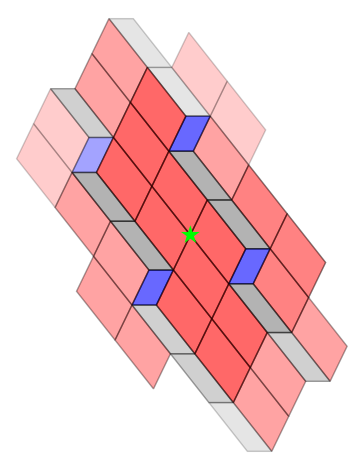

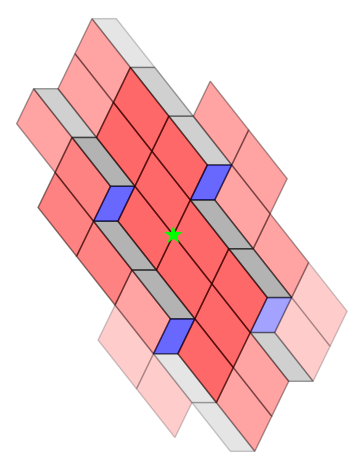

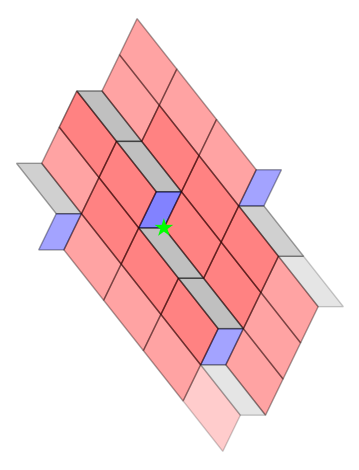

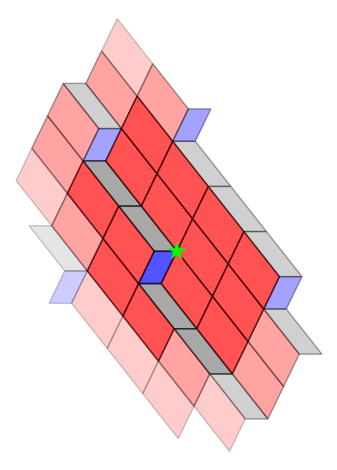

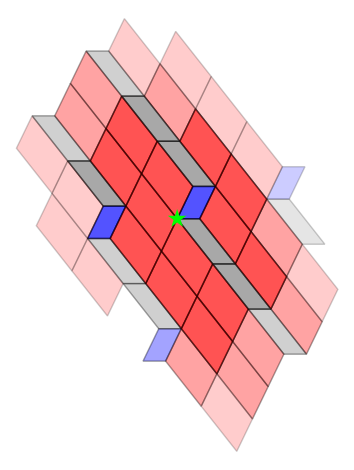

...

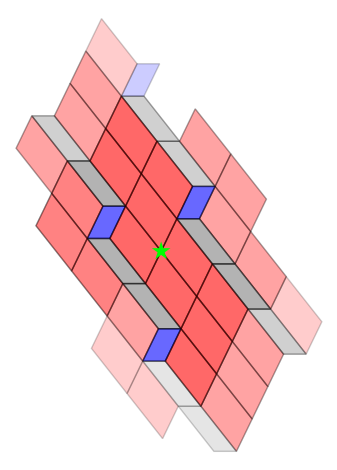

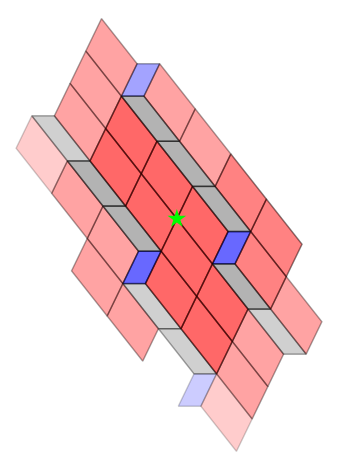

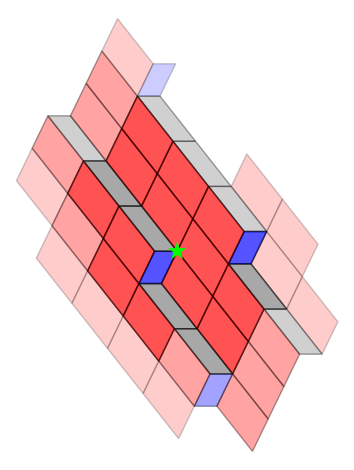

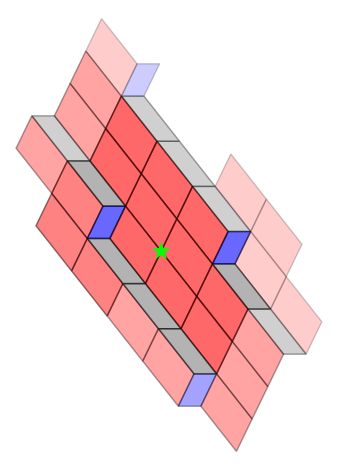

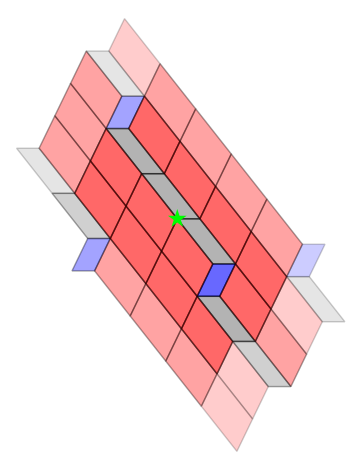

In [68]:
# level_max = 8

# start = time.time()
# num_collars, half_collars = find_half_collars_iteratively(level_max, k=2)
# finish = time.time()



print(f"Found {(num_collars)} 2.5 collars! Took {finish-start} seconds.")
for half_collar in half_collars:
    test = Patch()
    test.display_half_collar(half_collar, 2, True)

# if input('generate dicts and create pickle files? (y/n)') == 'y':
#     generate_code_dicts(collars, '2_collars')  

In [69]:
with open("kenyon_2.5_collars.pickle", "wb") as f:
        pickle.dump(half_collars, f)

### Finding and Gluing one cells and zero cells

In [19]:
tile_types = {'B', 'R', 'G'}

#Generate 1-cells and 0-cells

test_complex = CWComplex(uncollared_lvl_1_collar_code_to_list_dict, uncollared_lvl_1_collar_list_to_code_dict)
print('initiating disjoint set...')
test_complex.initiate_disjoint_set(k=2, AP_level=1)

# test_complex.one_cells = one_cells
# test_complex.zero_cells = zero_cells

print('finding all edge lists...')
all_edge_lists = test_complex.get_half_collar_prototile_vertices(uncollared_lvl_1_two_half_collars)

print('gluing all edges...')
test_complex.glue_all_edges(all_edge_lists)
print('making label dictionaries for one cells...')
label_to_one_cell, one_cell_to_label = test_complex.obj_to_label_map(prefix = '1E')
print('gluing zero cells...')
test_complex.glue_zero_cells(one_cell_to_label)

print('converting one cell to polynomial format...')
test_complex.convert_one_cells_to_poly()
label_to_one_cell, one_cell_to_label=test_complex.obj_to_label_map(prefix = '1E')
print('converting zero cells to polynomial format...')
test_complex.convert_zero_cells_to_poly()
label_to_zero_cell, zero_cell_to_label = test_complex.obj_to_label_map_zero_cells(prefix = '1V')

one_cells = test_complex.one_cells
zero_cells = test_complex.zero_cells


j = 0
lengths = set()
total_little_cells = 0
for i in test_complex.one_cells:
#     print(i[0])
    lengths.add(len(i[0]))
    total_little_cells += len(i[0])
    j += 1
#     if i[0] == frozenset({vector(QQ[a], (0, 1), immutable=True), vector(QQ[a], (0, 0), immutable=True)}):
#         if ('C0', vector(QQ[a], (-2, 0), immutable=True)) in i[1]:
#             print('We found it!')
#             print(i)            

print('num new one cells:', j)
print('nums of little cells in a single new one cell:', lengths)
print('num of little cells accounted for:', total_little_cells)
print()
print('num zero cells:', len(test_complex.zero_cells))

print(one_cells[0])


# Save to pickle
with open("kenyon-APlvl1-one-cell.pickle", "wb") as f:
    pickle.dump(one_cells, f)

with open("kenyon-APlvl1-label-to-one-cell.pickle", "wb") as f:
    pickle.dump(label_to_one_cell, f)
    
with open("kenyon-APlvl1-one-cell-to-label.pickle", "wb") as f:
    pickle.dump(one_cell_to_label, f)

with open("kenyon-APlvl1-zero-cell.pickle", "wb") as f:
    pickle.dump(zero_cells, f)
    
with open("kenyon-APlvl1-zero-cell-to-label.pickle", "wb") as f:
    pickle.dump(zero_cell_to_label, f)
    
with open("kenyon-APlvl1-label-to-zero-cell.pickle", "wb") as f:
    pickle.dump(label_to_zero_cell, f)

initiating disjoint set...
finding all edge lists...
	creating edge list of half collar 1/158
	creating edge list of half collar 2/158
	creating edge list of half collar 3/158
	creating edge list of half collar 4/158
	creating edge list of half collar 5/158
	creating edge list of half collar 6/158
	creating edge list of half collar 7/158
	creating edge list of half collar 8/158
	creating edge list of half collar 9/158
	creating edge list of half collar 10/158
	creating edge list of half collar 11/158
	creating edge list of half collar 12/158
	creating edge list of half collar 13/158
	creating edge list of half collar 14/158
	creating edge list of half collar 15/158
	creating edge list of half collar 16/158
	creating edge list of half collar 17/158
	creating edge list of half collar 18/158
	creating edge list of half collar 19/158
	creating edge list of half collar 20/158
	creating edge list of half collar 21/158
	creating edge list of half collar 22/158
	creating edge list of half coll

### Generating One Cell sub rule

In [ ]:
###### print(lvl_1_label_to_one_cell_dict['1E00'])

# print(canonical_orientation_for_one_cell(lvl_1_label_to_one_cell_dict['1E00']))

# generate_one_cell_substitutions([lvl_1_label_to_one_cell_dict['1E00']], one_cells)

# print(orientation_info)

one_cell_sub_dict = generate_one_cell_substitutions(lvl_1_one_cells, one_cells)

with open("kenyon_one_cell_sub_dict.pickle", "wb") as f:
    pickle.dump(one_cell_sub_dict, f)

with open("kenyon_one_cell_orientations.pickle", "wb") as f:
    pickle.dump(orientation_info, f)

In [40]:
one_cell_sub_dict = dict()
for one_cell in one_cells:
    # print('-------------------------------------------------------------------------------------------------------------')
    image_one_cell_lbls = generate_single_one_cell_sub(one_cell_to_label_dict[one_cell], K(0))
    # image_one_cell_lbls_list = generate_single_one_cell_sub(one_cell_to_label_dict[one_cell], K(0))
    one_cell_sub_dict[one_cell_to_label_dict[one_cell]] = image_one_cell_lbls
    # for image_one_cell_lbls in image_one_cell_lbls_list:
    
    #     print(f'{one_cell_to_label_dict[one_cell]} turns into {image_one_cell_lbls}')
    
    #     G = Graphics()
    #     one_cell_pts = []
    #     for line_ in one_cell[0]:
    #         for pt in line_:
    #             one_cell_pts.append(number_field_to_vector(pt*lam^2))
    #     G += line(one_cell_pts)
    #     G.set_aspect_ratio(1)
    #     # show(G)
    
    #     # G = Graphics()
    #     for loc_image in image_one_cell_lbls:
    #         image_lbl = loc_image[0]
    #         location = K(loc_image[1])
    #         image = label_to_one_cell_dict[image_lbl]
    #         image_pts = []
    #         for line_ in image[0]:
    #             for pt in line_:
    #                 image_pts.append(number_field_to_vector(pt + location))
    #         G += line(image_pts)
    
    #     G.set_aspect_ratio(1)
    #     show(G)
            

print(one_cell_sub_dict)


# with open("kenyon_one_cell_sub_dict.pickle", "wb") as f:
#     pickle.dump(one_cell_sub_dict, f)
    

KeyError: 'E00'

# testing testing testing

### testing one cells

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C01', lam^2 - lam), ('1C17', lam^2 - lam), ('1C16', -lam^2 - 2*lam)))


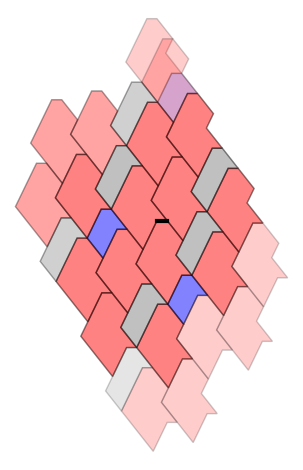

(frozenset({frozenset({0, lam^2})}), (('1C04', -3*lam - 1), ('1C02', -3*lam - 1), ('1C06', -3*lam - 1), ('1C09', lam^2)))


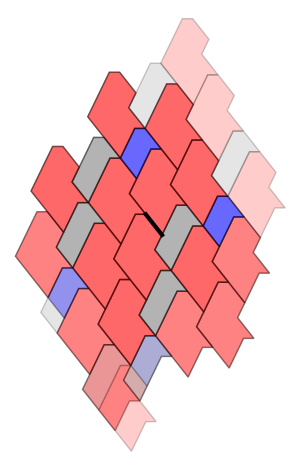

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C25', lam^2), ('1C19', -lam^2 - lam)))


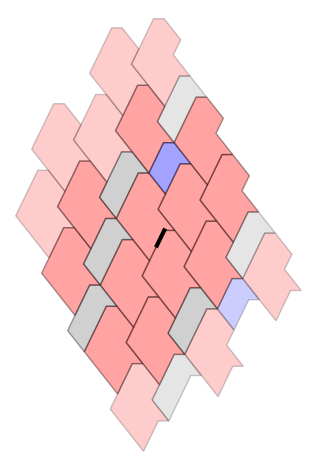

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C03', lam^2), ('1C23', lam^2), ('1C26', 0)))


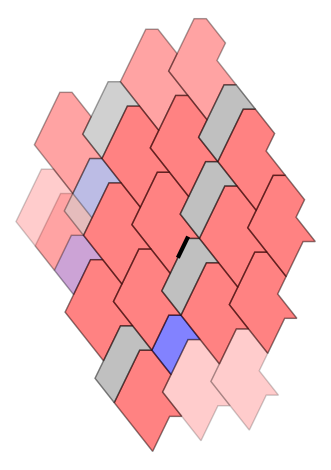

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C03', lam^2 - 2*lam - 1), ('1C18', lam^2 + lam), ('1C23', lam^2 - 2*lam - 1)))


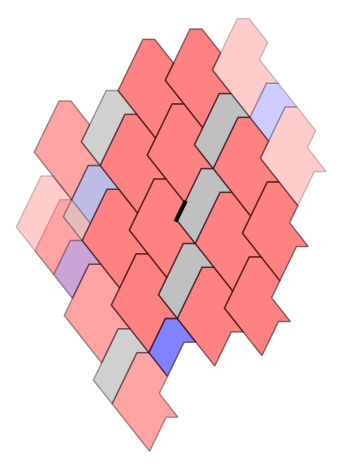

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C14', lam^2), ('1C04', -lam^2 - lam)))


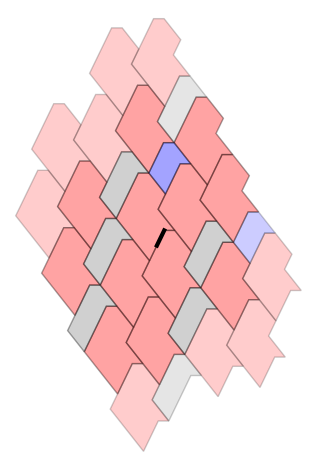

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C14', lam^2 - 2*lam - 1), ('1C09', 0), ('1C11', lam^2 - 2*lam - 1)))


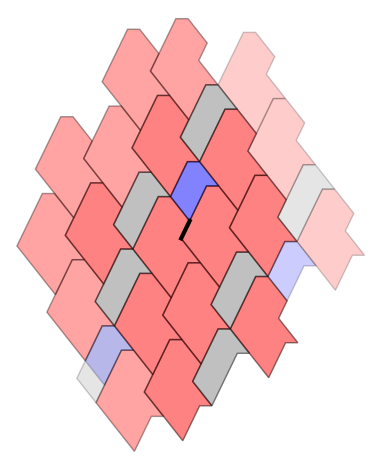

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C24', -lam), ('1C07', -lam), ('1C09', lam^2 - lam)))


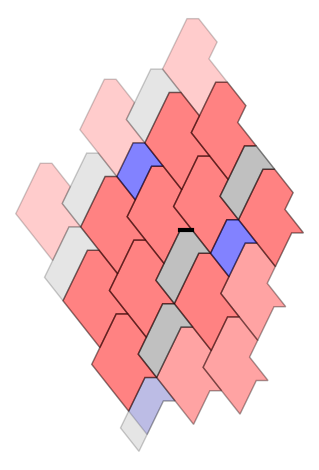

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C10', lam^2 - lam), ('1C00', -lam), ('1C02', lam^2 - lam)))


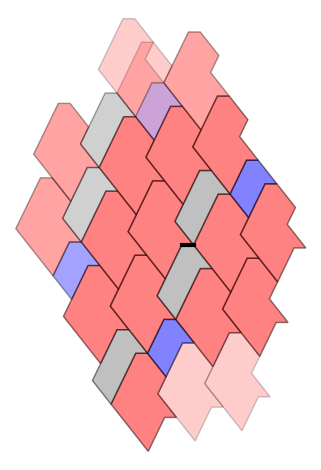

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C22', lam^2), ('1C10', -lam^2 - lam)))


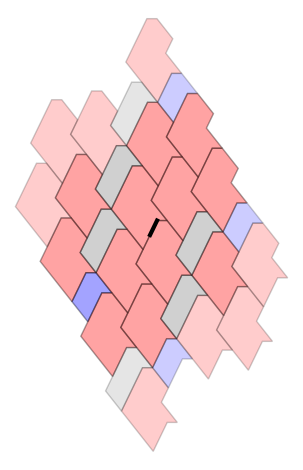

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C18', -lam), ('1C06', lam^2 - lam), ('1C04', lam^2 - lam)))


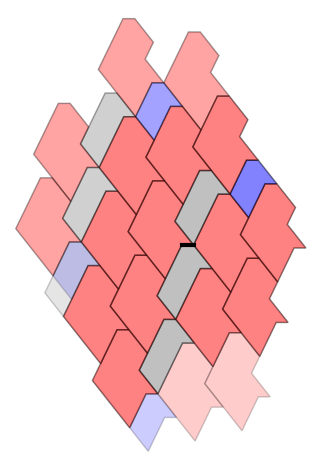

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C26', lam^2 + lam), ('1C12', lam^2 - 2*lam - 1), ('1C00', lam^2 + lam), ('1C16', lam^2 - 2*lam - 1)))


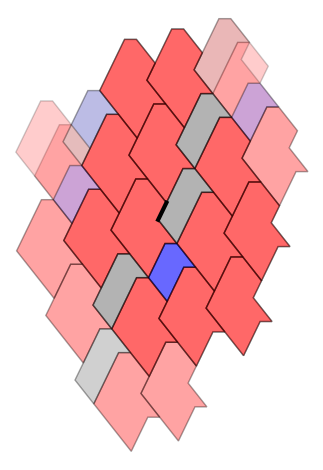

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C09', lam^2), ('1C24', 0), ('1C07', 0)))


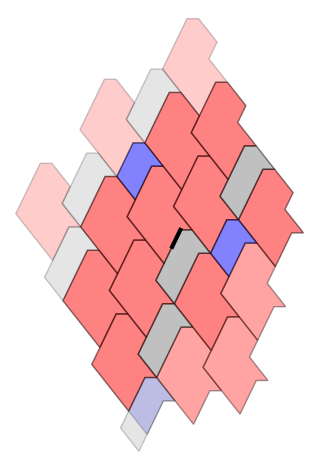

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C05', lam^2 - 3*lam - 1), ('1C16', lam^2 - lam), ('1C20', lam^2 - 3*lam - 1), ('1C12', lam^2 - lam)))


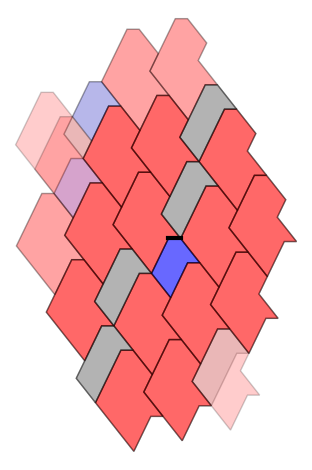

(frozenset({frozenset({0, lam^2})}), (('1C19', lam^2), ('1C10', -3*lam - 1)))


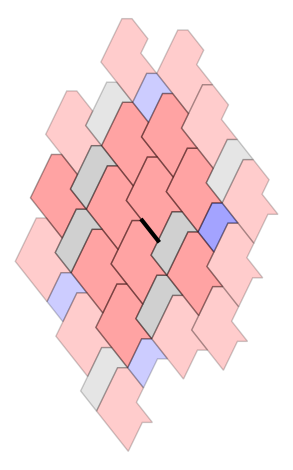

(frozenset({frozenset({0, lam^2})}), (('1C17', lam^2), ('1C01', lam^2), ('1C09', -3*lam - 1)))


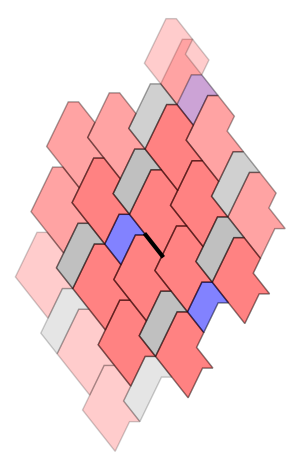

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C21', lam^2), ('1C23', -lam^2 - lam)))


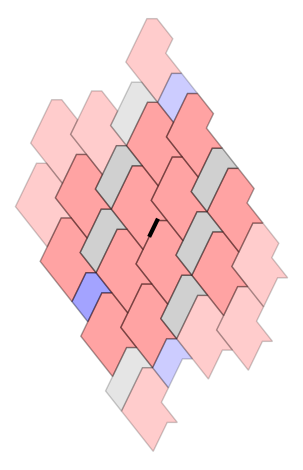

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C19', lam^2 - 2*lam - 1), ('1C12', 0)))


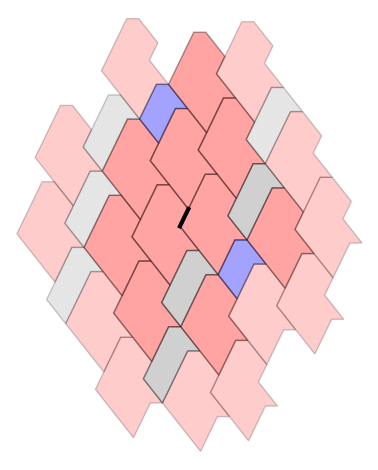

(frozenset({frozenset({0, lam^2})}), (('1C21', 0), ('1C22', 0), ('1C26', lam^2 - 2*lam - 1)))


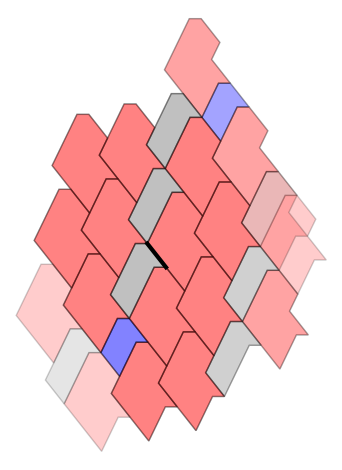

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C20', 2*lam^2 - 2*lam - 1), ('1C15', -lam^2 - lam)))


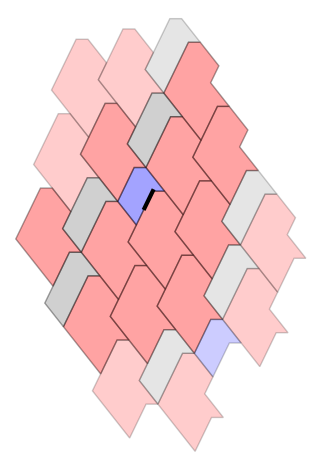

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C24', lam^2 - lam), ('1C13', lam^2 - lam), ('1C11', -lam^2 - 2*lam)))


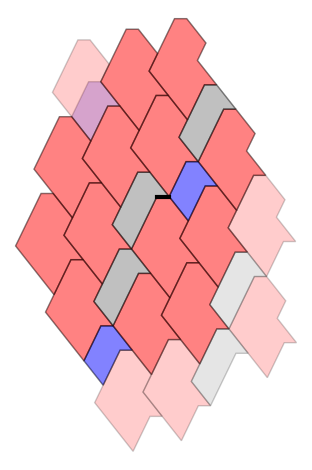

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C03', lam^2 - lam), ('1C26', -lam), ('1C23', lam^2 - lam)))


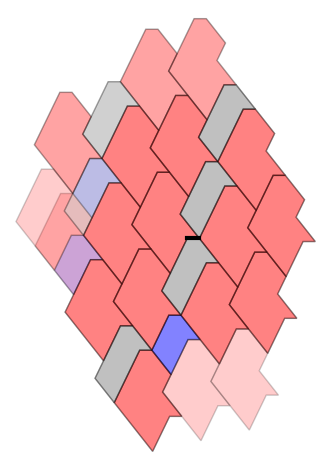

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C08', -lam^2 - lam), ('1C00', lam^2), ('1C01', -lam^2 - lam)))


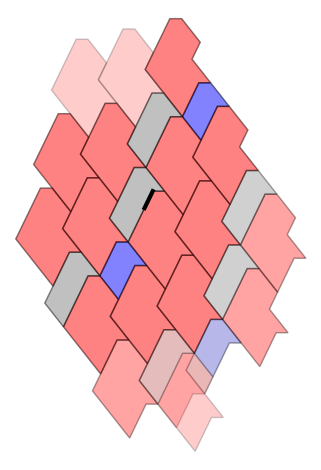

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C08', -lam^2), ('1C00', lam^2 + lam), ('1C01', -lam^2)))


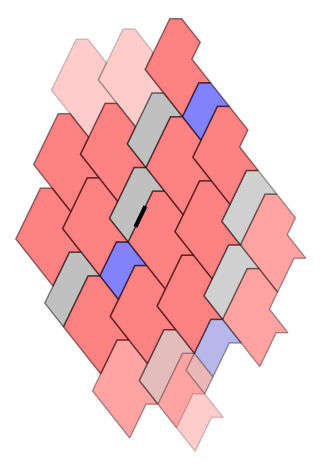

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C17', -lam^2 - 2*lam), ('1C26', lam^2 - lam)))


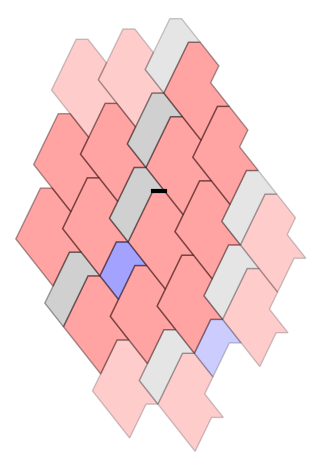

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C06', lam^2), ('1C04', lam^2), ('1C18', 0)))


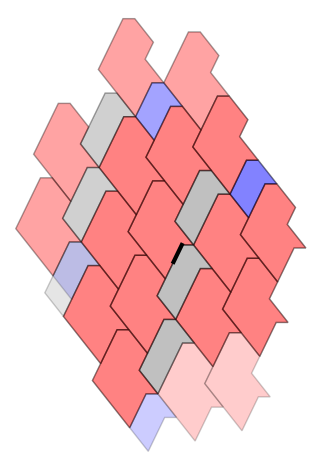

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C05', lam^2 - 2*lam - 1), ('1C12', lam^2), ('1C16', lam^2), ('1C20', lam^2 - 2*lam - 1)))


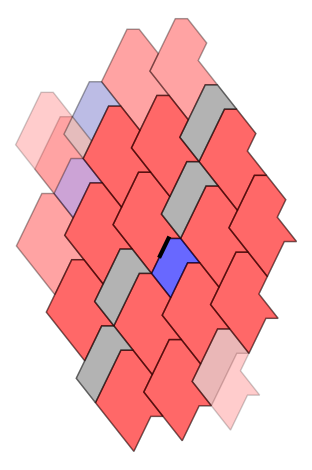

(frozenset({frozenset({0, lam^2})}), (('1C17', -3*lam - 1), ('1C21', lam^2), ('1C22', lam^2)))


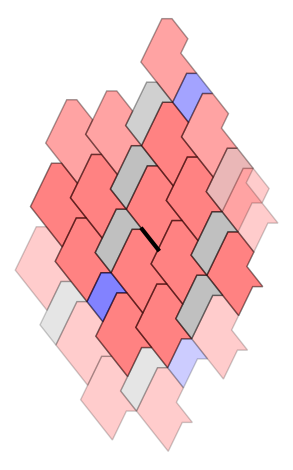

(frozenset({frozenset({0, lam^2})}), (('1C19', -3*lam - 1), ('1C15', lam^2)))


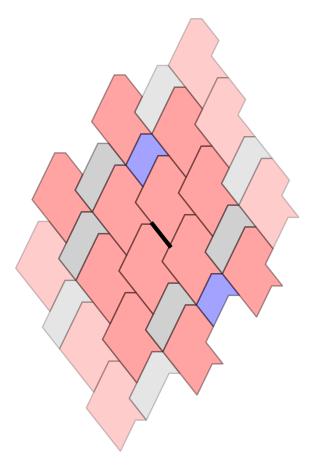

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C13', -lam), ('1C19', lam^2 - lam)))


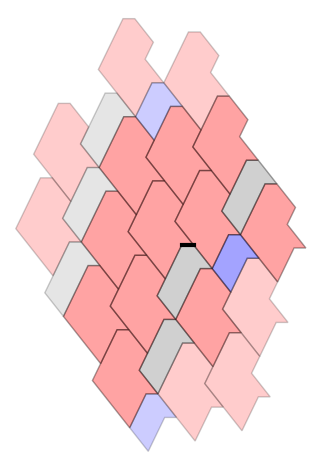

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C15', lam^2 - 2*lam - 1), ('1C03', 0)))


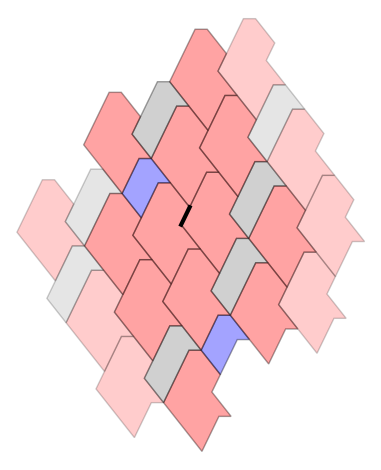

(frozenset({frozenset({0, 1})}), (('1C01', -lam^2 - 3*lam), ('1C08', -lam^2 - 3*lam), ('1C00', lam^2 - 2*lam)))


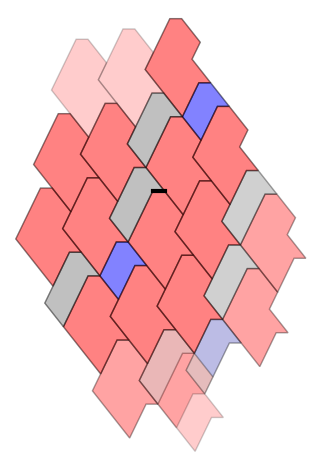

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C01', lam^2 - 2*lam - 1), ('1C02', 0)))


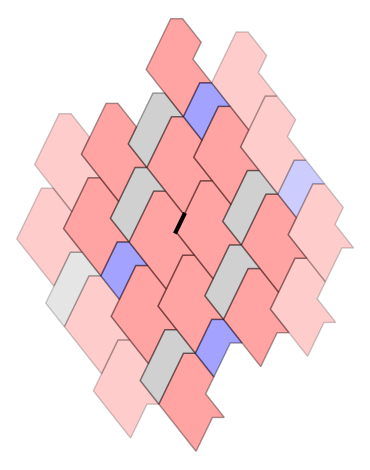

(frozenset({frozenset({0, lam^2})}), (('1C16', lam^2), ('1C07', lam^2 - 2*lam - 1), ('1C24', lam^2 - 2*lam - 1)))


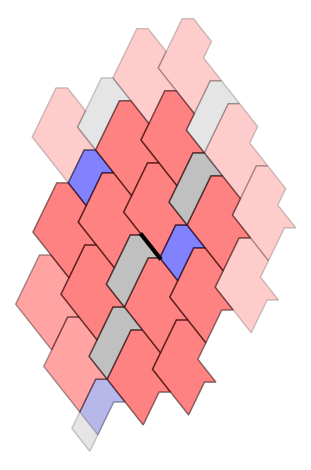

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C18', lam^2), ('1C22', -lam^2 - lam), ('1C21', -lam^2 - lam)))


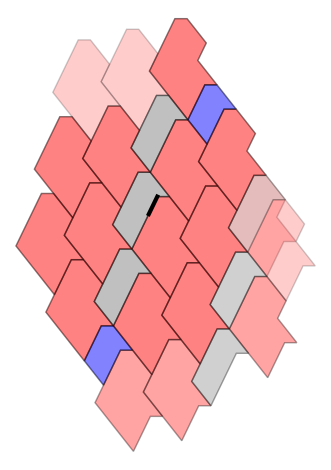

(frozenset({frozenset({0, lam^2})}), (('1C08', lam^2), ('1C15', -3*lam - 1)))


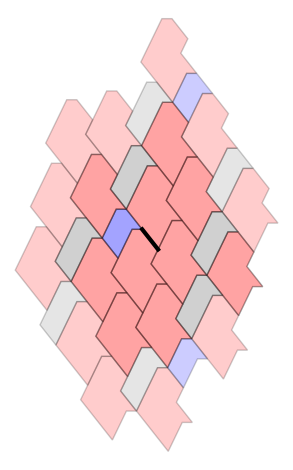

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C24', lam^2), ('1C11', -lam^2 - lam), ('1C13', lam^2)))


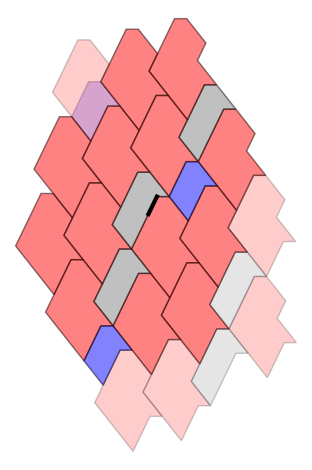

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C10', 0), ('1C23', 0), ('1C17', lam^2 - 2*lam - 1)))


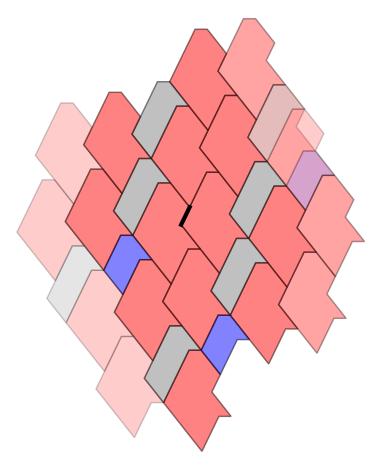

(frozenset({frozenset({0, lam^2})}), (('1C08', -3*lam - 1), ('1C11', lam^2), ('1C01', -3*lam - 1)))


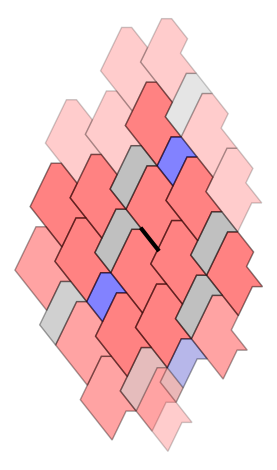

(frozenset({frozenset({0, lam^2})}), (('1C20', 2*lam^2 - 4*lam - 2), ('1C08', 0)))


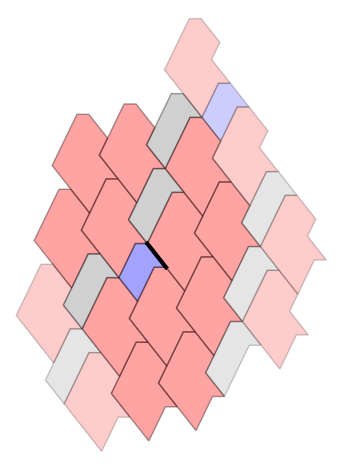

(frozenset({frozenset({0, lam^2})}), (('1C14', 0), ('1C25', 0), ('1C18', lam^2 - 2*lam - 1)))


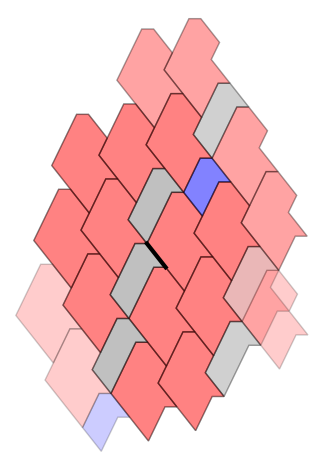

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C02', lam^2), ('1C10', lam^2), ('1C00', 0)))


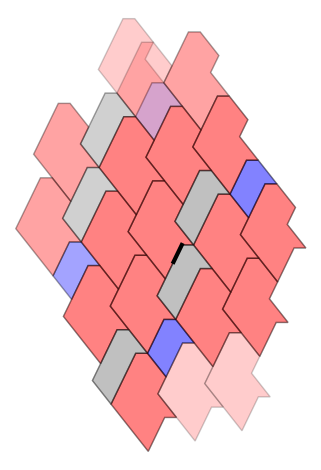

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C02', lam^2 - 2*lam - 1), ('1C24', lam^2 + lam)))


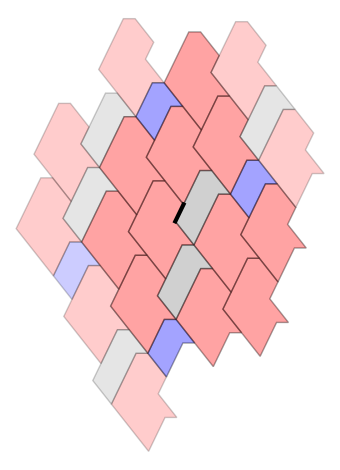

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C07', lam^2 + lam), ('1C06', lam^2 - 2*lam - 1), ('1C04', lam^2 - 2*lam - 1)))


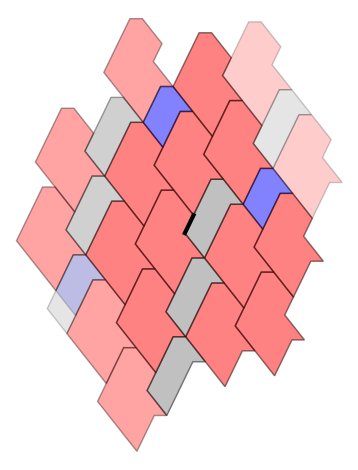

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C04', 0), ('1C21', lam^2 - 2*lam - 1)))


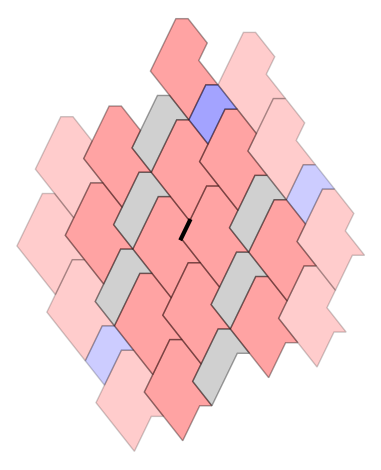

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C15', lam^2 - lam), ('1C12', -lam^2 - 2*lam)))


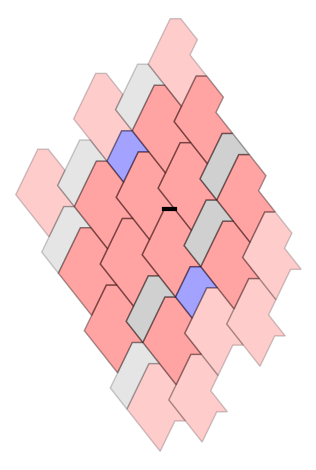

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C14', -lam^2 - lam), ('1C25', -lam^2 - lam), ('1C07', lam^2)))


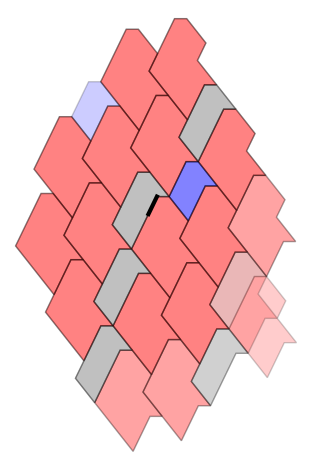

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C13', 0), ('1C19', lam^2)))


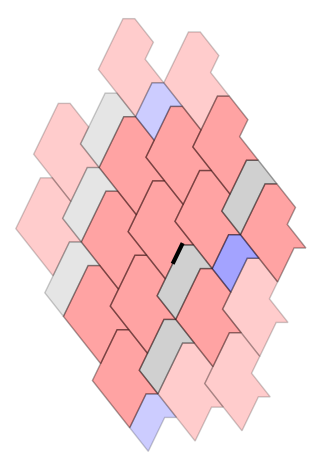

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C14', -lam^2), ('1C25', -lam^2), ('1C07', lam^2 + lam)))


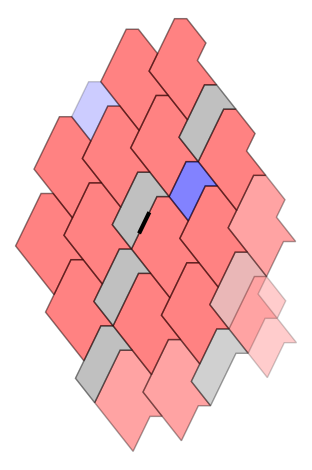

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C22', -lam^2), ('1C18', lam^2 + lam), ('1C21', -lam^2)))


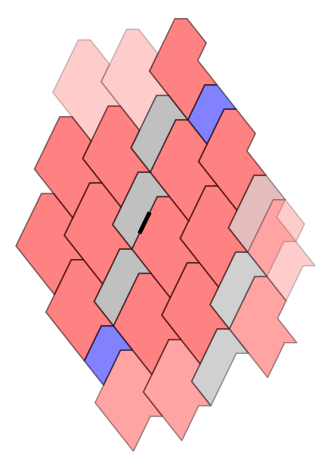

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C04', -lam^2 - 2*lam), ('1C14', lam^2 - lam)))


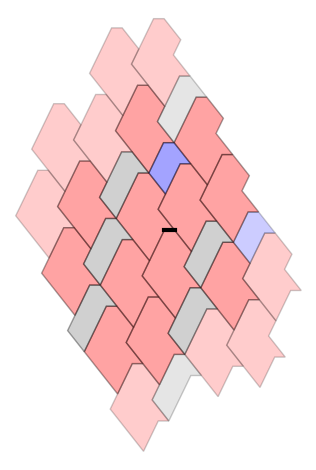

(frozenset({frozenset({0, lam^2})}), (('1C21', -3*lam - 1), ('1C14', lam^2)))


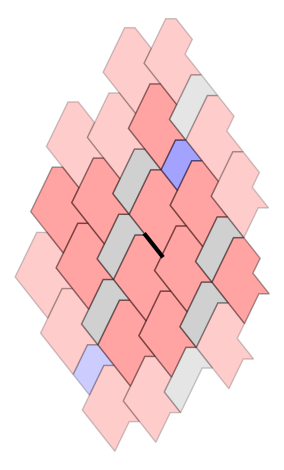

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C15', lam^2), ('1C12', -lam^2 - lam)))


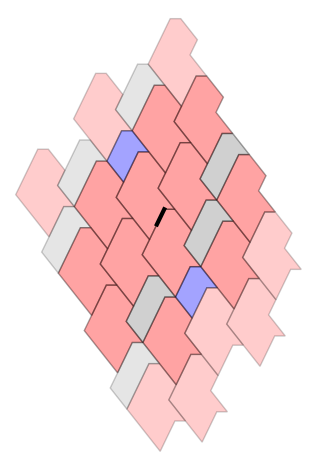

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C22', lam^2 - 2*lam - 1), ('1C19', 0)))


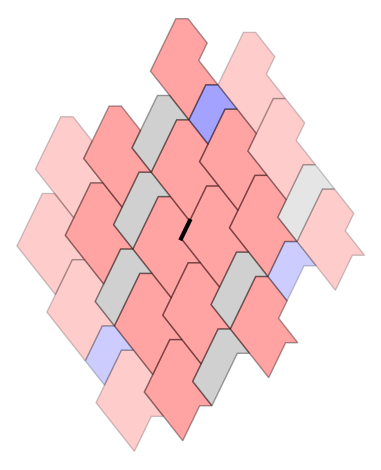

(frozenset({frozenset({0, lam^2})}), (('1C10', lam^2), ('1C16', -3*lam - 1), ('1C23', lam^2), ('1C02', lam^2)))


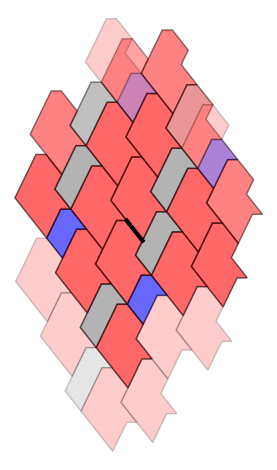

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C06', -lam^2 - lam), ('1C02', -lam^2 - lam), ('1C11', lam^2)))


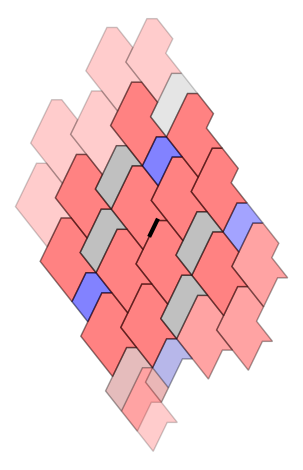

(frozenset({frozenset({0, lam^2})}), (('1C03', lam^2), ('1C12', -3*lam - 1)))


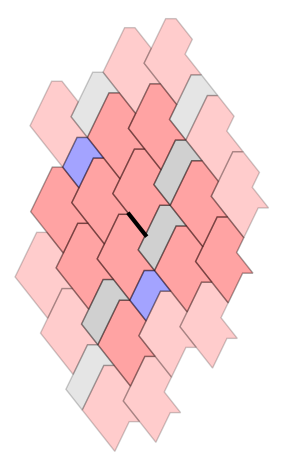

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C10', lam^2 - 2*lam - 1), ('1C13', lam^2 + lam)))


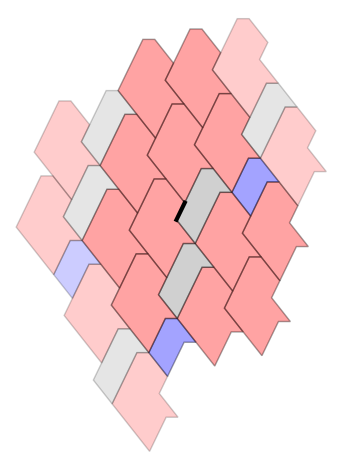

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C16', 0), ('1C09', lam^2 - 2*lam - 1)))


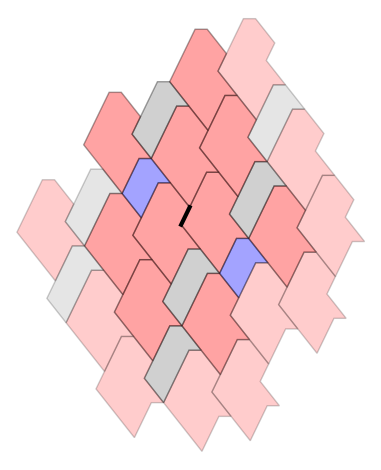

(frozenset({frozenset({0, lam^2})}), (('1C22', -3*lam - 1), ('1C25', lam^2)))


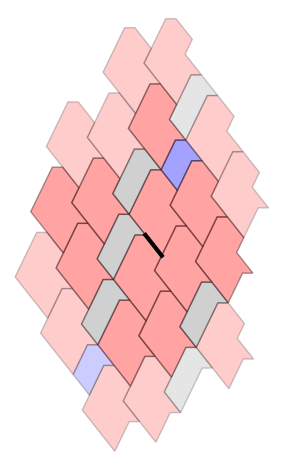

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C17', -lam^2), ('1C26', lam^2 + lam)))


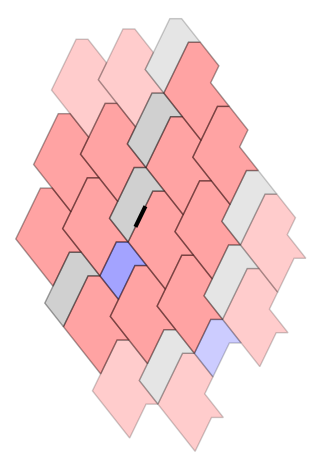

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C26', lam^2), ('1C17', -lam^2 - lam)))


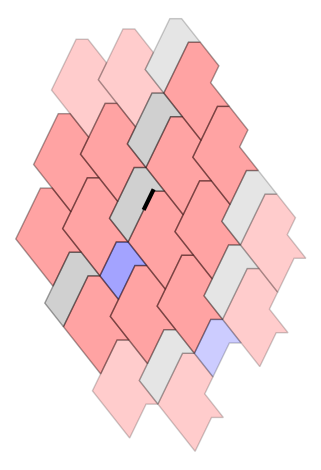

(frozenset({frozenset({0, 1})}), (('1C22', -lam^2 - 3*lam), ('1C21', -lam^2 - 3*lam), ('1C18', lam^2 - 2*lam)))


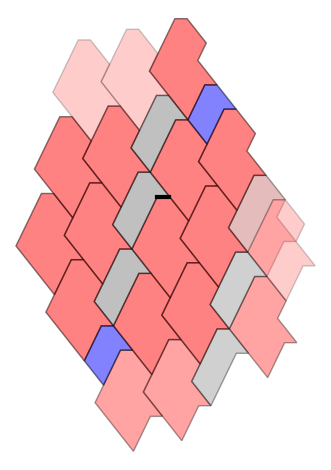

(frozenset({frozenset({0, lam^2})}), (('1C00', lam^2 - 2*lam - 1), ('1C11', 0)))


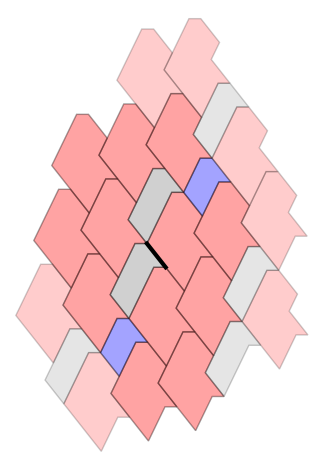

(frozenset({frozenset({0, lam})}), (('1C16', -lam^2 - lam), ('1C17', lam^2), ('1C01', lam^2)))


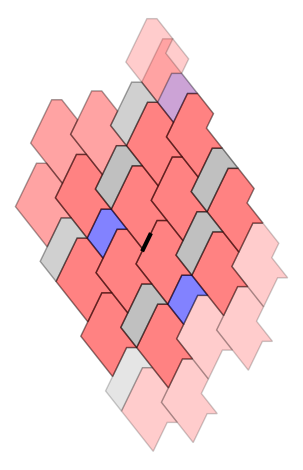

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C15', 0), ('1C25', lam^2 - 2*lam - 1)))


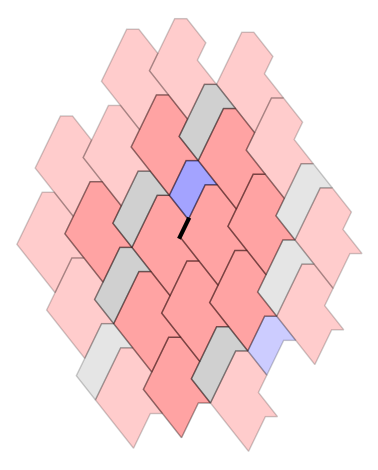

(frozenset({frozenset({0, 1})}), (('1C19', -lam^2 - 3*lam), ('1C25', lam^2 - 2*lam)))


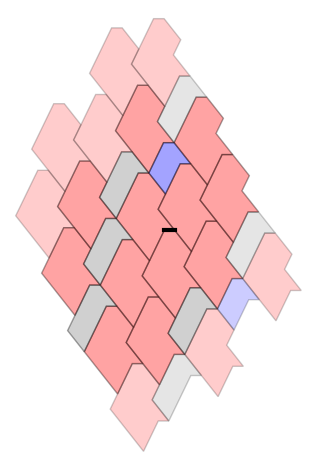

(frozenset({frozenset({0, lam^2})}), (('1C03', -3*lam - 1), ('1C06', lam^2)))


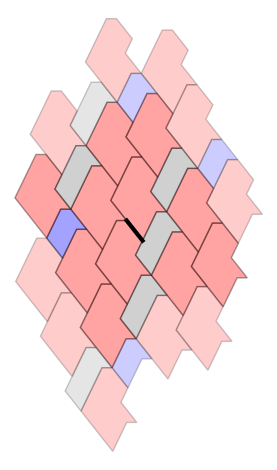

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C22', lam^2 - lam), ('1C10', -lam^2 - 2*lam)))


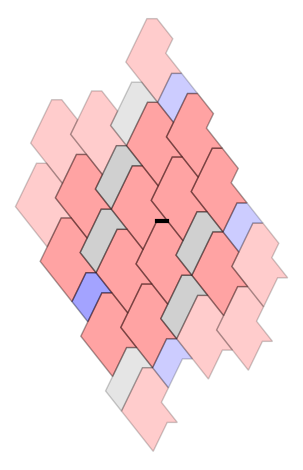

(frozenset({frozenset({0, 1})}), (('1C06', -lam^2 - 3*lam), ('1C02', -lam^2 - 3*lam), ('1C11', lam^2 - 2*lam)))


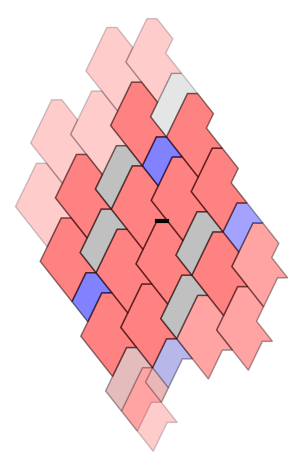

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C11', -lam^2), ('1C24', lam^2 + lam), ('1C13', lam^2 + lam)))


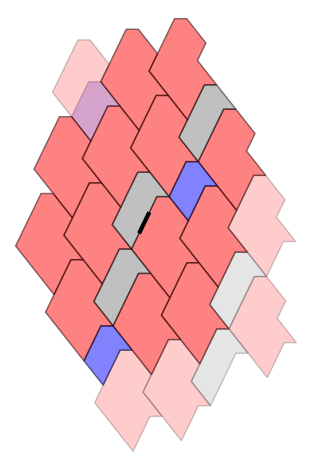

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C03', -lam^2 - lam), ('1C08', lam^2)))


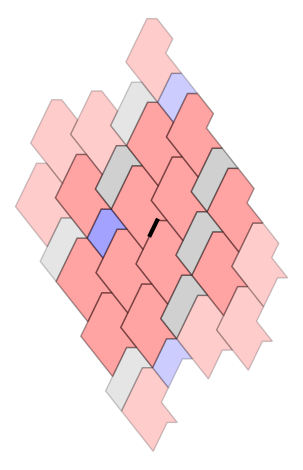

(frozenset({frozenset({lam, 2*lam}), frozenset({0, lam})}), (('1C05', 2*lam^2 - 2*lam - 1), ('1C09', -lam^2 - lam)))


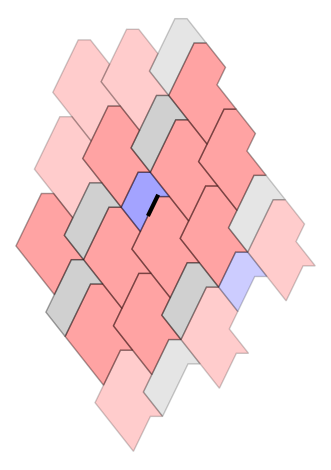

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C08', lam^2 - lam), ('1C03', -lam^2 - 2*lam)))


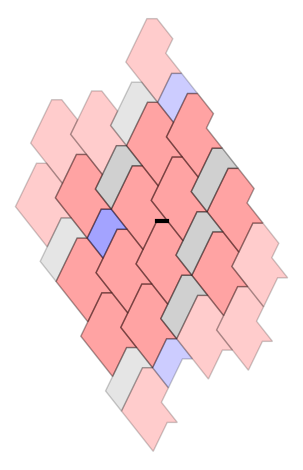

(frozenset({frozenset({lam^2, lam^2 + lam}), frozenset({0, lam^2})}), (('1C08', lam^2 - 2*lam - 1), ('1C06', 0)))


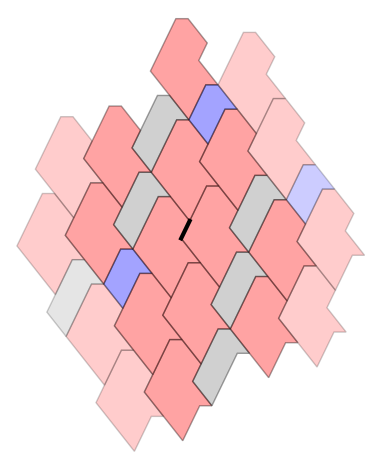

(frozenset({frozenset({0, lam^2})}), (('1C11', -3*lam - 1), ('1C14', -3*lam - 1), ('1C05', 2*lam^2 - 2*lam - 1)))


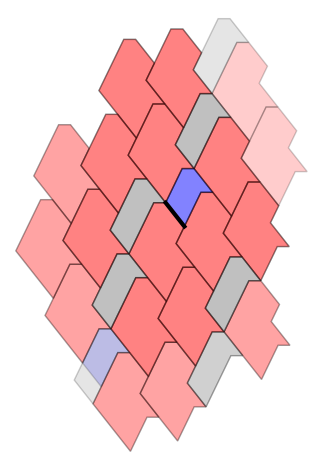

(frozenset({frozenset({0, 1})}), (('1C20', 2*lam^2 - 4*lam - 1), ('1C15', -lam^2 - 3*lam)))


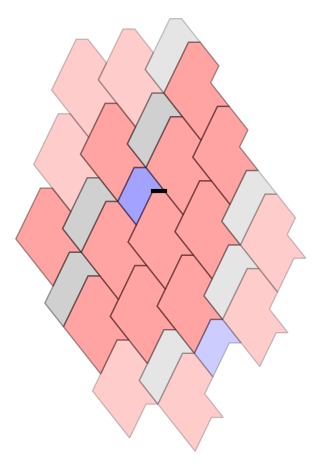

(frozenset({frozenset({lam, lam + 1}), frozenset({0, lam})}), (('1C05', 2*lam^2 - 3*lam - 1), ('1C09', -lam^2 - 2*lam)))


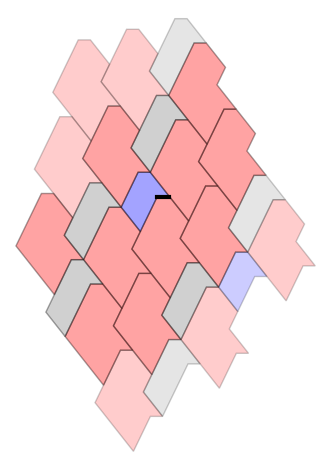

(frozenset({frozenset({0, 1})}), (('1C14', -lam^2 - 3*lam), ('1C07', lam^2 - 2*lam), ('1C25', -lam^2 - 3*lam)))


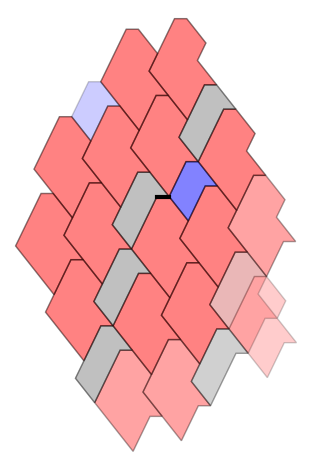

(frozenset({frozenset({0, lam^2})}), (('1C12', lam^2), ('1C13', lam^2 - 2*lam - 1)))


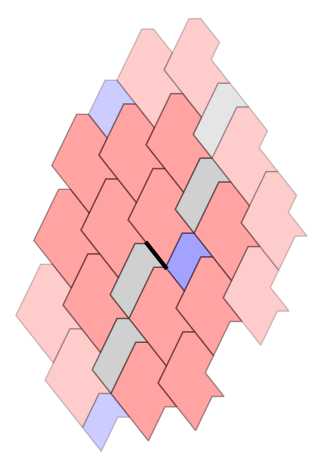

(frozenset({frozenset({0, lam^2})}), (('1C23', -3*lam - 1), ('1C04', lam^2)))


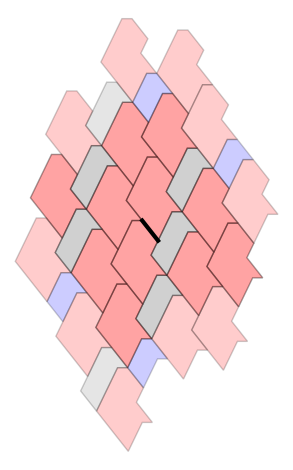

(frozenset({frozenset({0, lam^2})}), (('1C01', 0), ('1C17', 0), ('1C05', 2*lam^2 - 4*lam - 2)))


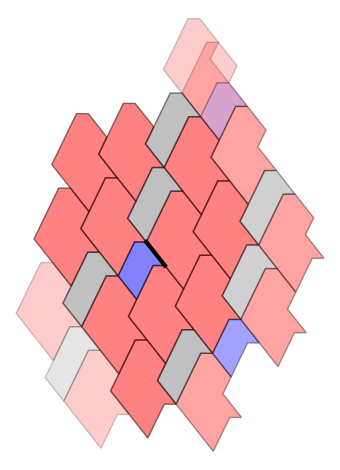

(frozenset({frozenset({0, 1})}), (('1C23', -lam^2 - 3*lam), ('1C21', lam^2 - 2*lam)))


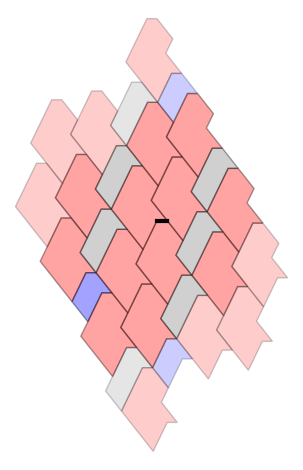

(frozenset({frozenset({0, lam^2})}), (('1C25', -3*lam - 1), ('1C20', 2*lam^2 - 2*lam - 1)))


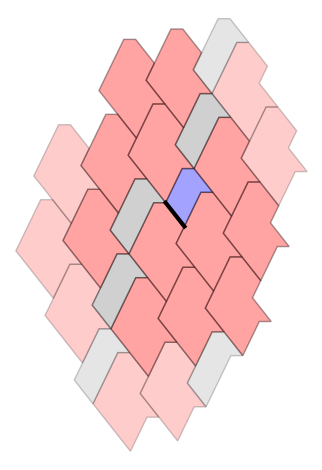

In [28]:
# test = Patch()
for one_cell in one_cells:
    test = Patch_2()
    print(one_cell)
    G = Graphics()
    
    nf_endpoints = list(list(one_cell[0])[0])
    endpoints = []
    for pt in nf_endpoints:
        endpoints.append(number_field_to_vector(pt))
    G += line(endpoints, thickness=3, rgbcolor=(0,0,0))
   
    for located_collar in one_cell[1]:
        collar_code = located_collar[0]
        collar_loc = located_collar[1]
        unshifted_collar = uncollared_lvl_1_collar_code_to_list_dict[collar_code]
        for located_tile in unshifted_collar[1]:
            tile_code = located_tile[0]
            tile_loc = located_tile[1]
            test.add_prototile_code(tile_code, tile_loc + collar_loc)
        # new_decoration = set()
        # for tile in unshifted_collar[1]:
        #     new_tile = (tile[0], tile[1] + collar_loc)
        #     new_decoration.add(new_tile)
        # shifted_collar = (unshifted_collar[0], frozenset(new_decoration))
        
        # G += test.display_collar(shifted_collar)
    G += test.graph_patch()
    show(G)    


### testing zero cells

(frozenset({frozenset({0, lam})}), (('C22', 0), ('C26', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C24', lam^2), ('C26', lam^2), ('C23', -1)))
(frozenset({frozenset({0, lam})}), (('C04', 0), ('C24', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C04', lam^2), ('C15', -1), ('C22', lam^2)))
(frozenset({frozenset({0, 1})}), (('C23', 0), ('C15', -lam^2)))


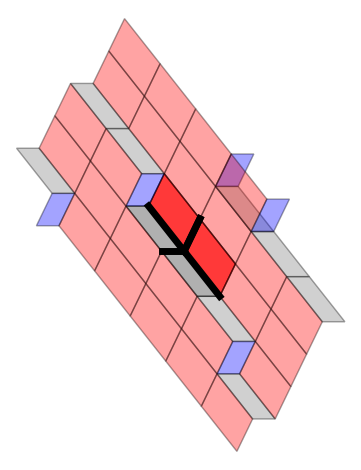

(frozenset({frozenset({0, 1})}), (('C16', -lam^2), ('C06', lam)))
(frozenset({frozenset({0, lam^2})}), (('C16', 0), ('C19', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C18', lam^2), ('C14', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C19', 0), ('C14', lam^2)))
(frozenset({frozenset({0, lam})}), (('C06', lam), ('C18', lam^2)))


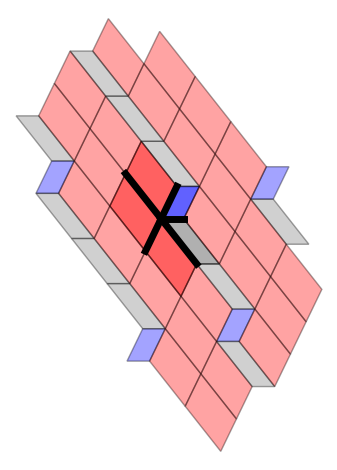

(frozenset({frozenset({0, lam^2})}), (('C13', lam^2 - lam), ('C12', lam^2)))
(frozenset({frozenset({0, lam})}), (('C13', lam^2), ('C20', 0)))
(frozenset({frozenset({0, lam^2})}), (('C17', lam^2), ('C20', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C17', 0), ('C12', lam^2)))


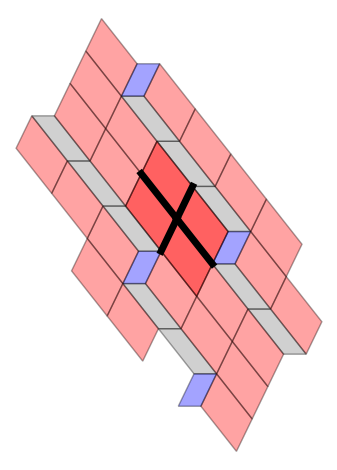

(frozenset({frozenset({0, lam^2})}), (('C25', lam^2 - lam), ('C07', lam^2 - lam), ('C23', 0)))
(frozenset({frozenset({0, lam^2})}), (('C17', lam^2), ('C20', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C01', 0), ('C25', 0), ('C00', lam^2), ('C20', lam^2)))
(frozenset({frozenset({0, 1})}), (('C23', -lam^2), ('C02', -lam^2), ('C11', lam), ('C29', lam)))
(frozenset({frozenset({0, lam^2})}), (('C05', lam^2), ('C00', lam^2 - lam), ('C30', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C11', lam), ('C17', lam^2), ('C29', lam), ('C05', lam^2)))
(frozenset({frozenset({0, lam})}), (('C07', 0), ('C30', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C02', 0), ('C01', lam^2 - lam)))


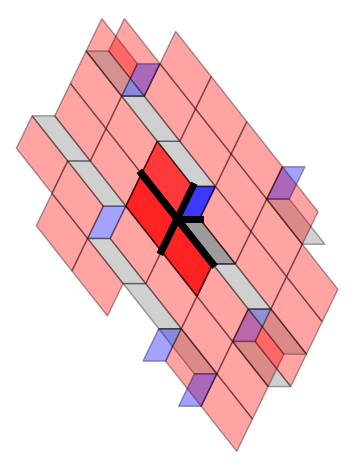

(frozenset({frozenset({0, lam^2})}), (('C31', lam^2), ('C08', -1)))
(frozenset({frozenset({0, lam})}), (('C29', lam - 1), ('C09', 0), ('C06', lam - 1), ('C24', 0)))
(frozenset({frozenset({0, lam^2})}), (('C10', lam^2), ('C13', lam^2), ('C21', -1)))
(frozenset({frozenset({0, 1})}), (('C08', 0), ('C21', 0), ('C29', 0), ('C06', 0)))
(frozenset({frozenset({0, lam})}), (('C10', lam^2), ('C31', lam^2), ('C00', 0), ('C30', 0)))
(frozenset({frozenset({0, lam})}), (('C13', lam^2), ('C20', 0)))
(frozenset({frozenset({0, lam^2})}), (('C00', lam^2), ('C20', lam^2), ('C09', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C30', lam^2), ('C24', lam^2 - lam)))


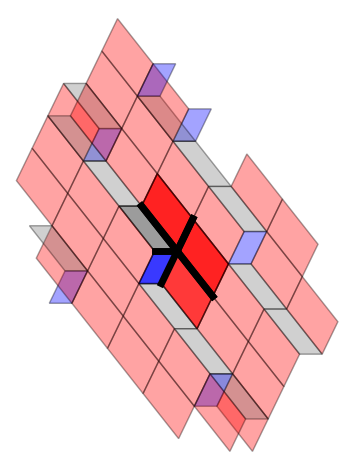

(frozenset({frozenset({0, lam})}), (('C01', lam^2), ('C05', 0), ('C19', lam^2)))
(frozenset({frozenset({0, lam})}), (('C10', lam^2), ('C31', lam^2), ('C00', 0), ('C30', 0)))
(frozenset({frozenset({0, lam^2})}), (('C10', lam^2 - lam), ('C19', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C05', lam^2), ('C00', lam^2 - lam), ('C30', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C01', lam^2), ('C31', lam^2 - lam)))


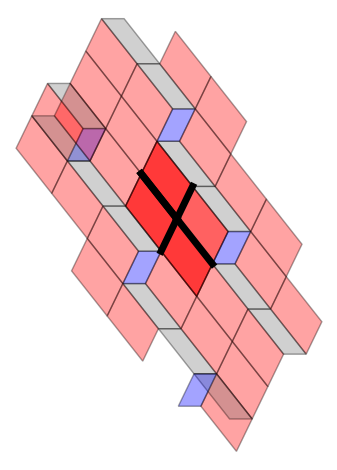

(frozenset({frozenset({0, lam})}), (('C12', 0), ('C07', lam^2)))
(frozenset({frozenset({0, lam})}), (('C28', 0), ('C25', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C15', 0), ('C12', lam^2 - lam), ('C28', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C25', lam^2 - lam), ('C07', lam^2 - lam), ('C23', 0)))
(frozenset({frozenset({0, 1})}), (('C23', 0), ('C15', -lam^2)))


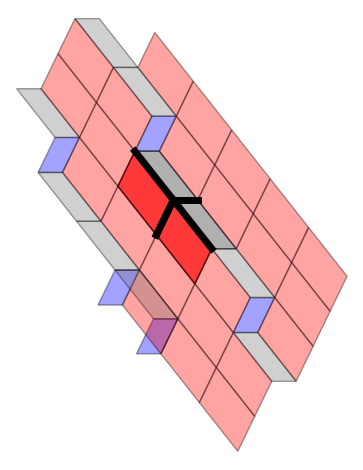

(frozenset({frozenset({0, 1})}), (('C16', -lam^2), ('C06', lam)))
(frozenset({frozenset({0, lam^2})}), (('C24', lam^2), ('C26', lam^2), ('C23', -1)))
(frozenset({frozenset({0, 1})}), (('C23', -lam^2), ('C02', -lam^2), ('C11', lam), ('C29', lam)))
(frozenset({frozenset({0, lam})}), (('C29', lam - 1), ('C09', 0), ('C06', lam - 1), ('C24', 0)))
(frozenset({frozenset({0, lam})}), (('C26', 0), ('C11', lam - 1)))
(frozenset({frozenset({0, lam^2})}), (('C09', lam^2), ('C16', -1), ('C02', -1)))


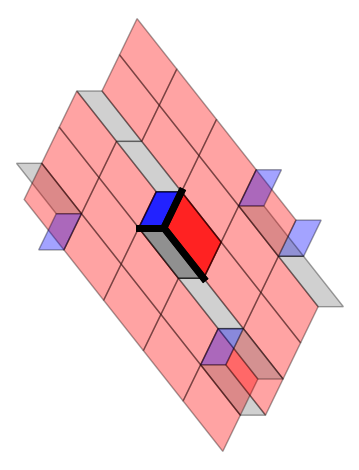

(frozenset({frozenset({0, lam})}), (('C32', lam^2), ('C14', 0)))
(frozenset({frozenset({0, lam^2})}), (('C22', lam^2 - lam), ('C14', lam^2)))
(frozenset({frozenset({0, lam})}), (('C22', 0), ('C26', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C32', lam^2), ('C26', lam^2 - lam)))


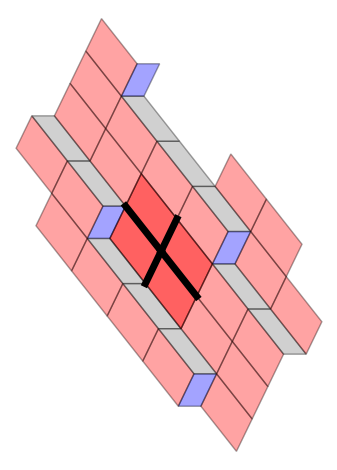

(frozenset({frozenset({0, lam})}), (('C17', 0), ('C12', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C17', lam^2 - lam), ('C18', lam^2 - lam), ('C21', 0)))
(frozenset({frozenset({0, lam^2})}), (('C15', 0), ('C12', lam^2 - lam), ('C28', lam^2 - lam)))
(frozenset({frozenset({0, 1})}), (('C21', -lam^2), ('C15', 0)))
(frozenset({frozenset({0, lam})}), (('C28', lam^2), ('C18', 0)))


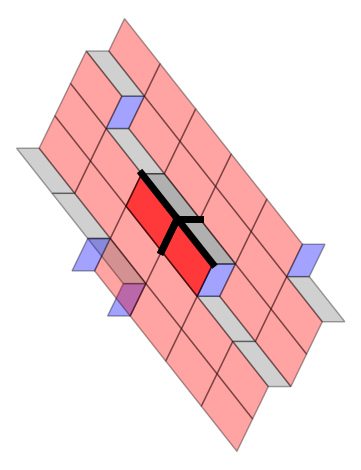

(frozenset({frozenset({0, lam^2})}), (('C01', lam^2), ('C31', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C00', lam^2), ('C20', lam^2), ('C09', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C27', 0), ('C09', lam^2), ('C31', 0)))
(frozenset({frozenset({0, lam^2})}), (('C25', lam^2), ('C27', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C01', 0), ('C25', 0), ('C00', lam^2), ('C20', lam^2)))


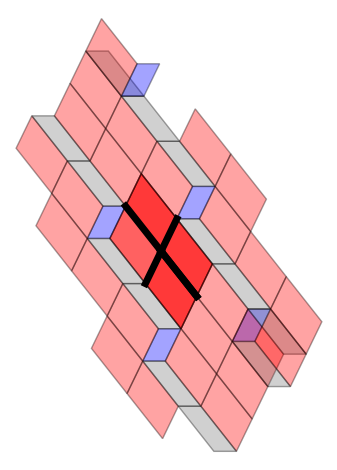

(frozenset({frozenset({0, lam^2})}), (('C16', 0), ('C19', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C02', 0), ('C01', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C01', lam^2), ('C05', 0), ('C19', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C08', 0), ('C05', lam^2 - lam), ('C03', 0)))
(frozenset({frozenset({0, 1})}), (('C03', -lam^2), ('C02', 0), ('C08', -lam^2), ('C16', 0)))


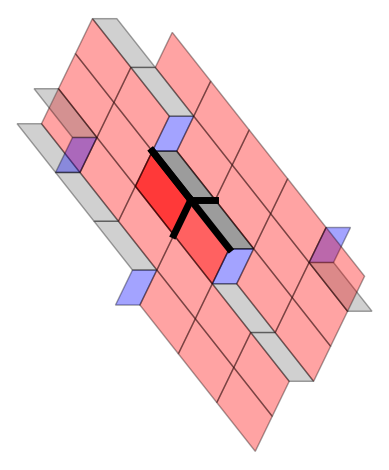

(frozenset({frozenset({0, lam^2})}), (('C32', lam^2), ('C26', lam^2 - lam)))
(frozenset({frozenset({0, 1})}), (('C11', 0), ('C03', 0)))
(frozenset({frozenset({0, lam^2})}), (('C03', -1), ('C27', lam^2)))
(frozenset({frozenset({0, lam})}), (('C26', 0), ('C11', lam - 1)))
(frozenset({frozenset({0, lam})}), (('C27', lam^2), ('C32', 0)))


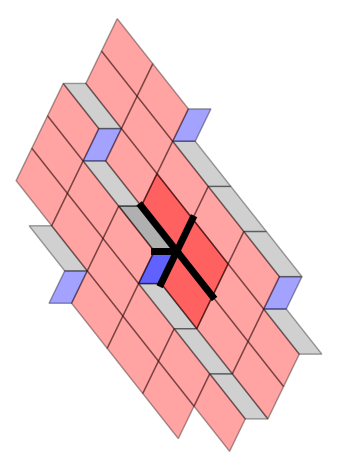

(frozenset({frozenset({0, lam})}), (('C28', lam^2), ('C18', 0)))
(frozenset({frozenset({0, lam^2})}), (('C28', lam^2), ('C32', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C18', lam^2), ('C14', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C32', lam^2), ('C14', 0)))


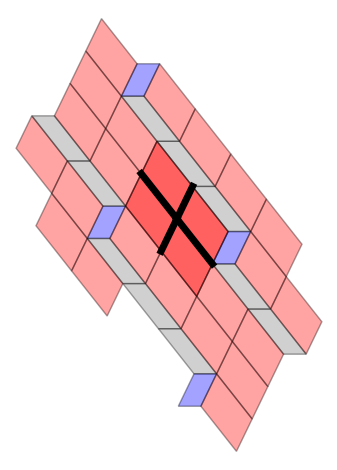

(frozenset({frozenset({0, lam})}), (('C07', 0), ('C30', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C30', lam^2), ('C24', lam^2 - lam)))
(frozenset({frozenset({0, lam^2})}), (('C04', lam^2 - lam), ('C07', lam^2)))
(frozenset({frozenset({0, lam})}), (('C04', 0), ('C24', lam^2)))


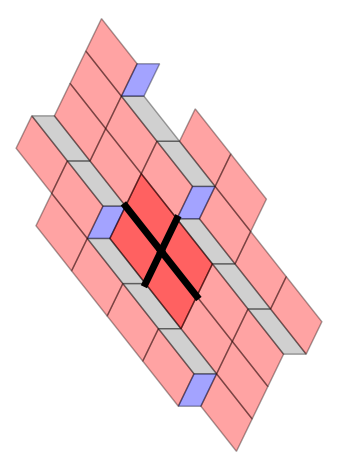

(frozenset({frozenset({0, lam})}), (('C04', lam^2), ('C13', 0)))
(frozenset({frozenset({0, lam^2})}), (('C13', lam^2 - lam), ('C12', lam^2)))
(frozenset({frozenset({0, lam})}), (('C12', 0), ('C07', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C04', lam^2 - lam), ('C07', lam^2)))


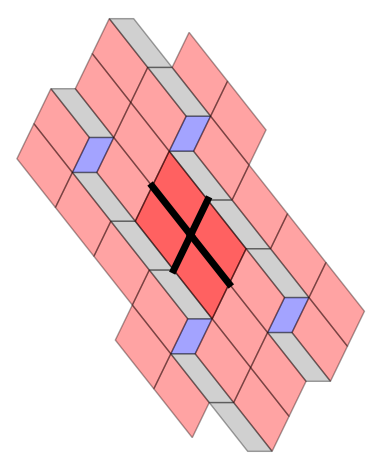

(frozenset({frozenset({0, lam^2})}), (('C25', lam^2), ('C27', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C27', lam^2), ('C32', 0)))
(frozenset({frozenset({0, lam^2})}), (('C28', lam^2), ('C32', lam^2 - lam)))
(frozenset({frozenset({0, lam})}), (('C28', 0), ('C25', lam^2)))


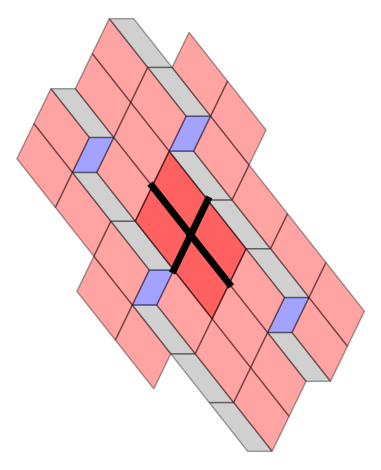

(frozenset({frozenset({0, 1})}), (('C11', 0), ('C03', 0)))
(frozenset({frozenset({0, lam})}), (('C11', lam), ('C17', lam^2), ('C29', lam), ('C05', lam^2)))
(frozenset({frozenset({0, 1})}), (('C08', 0), ('C21', 0), ('C29', 0), ('C06', 0)))
(frozenset({frozenset({0, lam})}), (('C06', lam), ('C18', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C08', 0), ('C05', lam^2 - lam), ('C03', 0)))
(frozenset({frozenset({0, lam^2})}), (('C17', lam^2 - lam), ('C18', lam^2 - lam), ('C21', 0)))


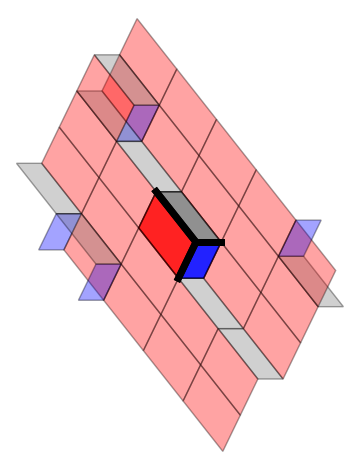

(frozenset({frozenset({0, lam^2})}), (('C31', lam^2), ('C08', -1)))
(frozenset({frozenset({0, lam^2})}), (('C09', lam^2), ('C16', -1), ('C02', -1)))
(frozenset({frozenset({0, lam^2})}), (('C03', -1), ('C27', lam^2)))
(frozenset({frozenset({0, lam})}), (('C27', 0), ('C09', lam^2), ('C31', 0)))
(frozenset({frozenset({0, 1})}), (('C03', -lam^2), ('C02', 0), ('C08', -lam^2), ('C16', 0)))


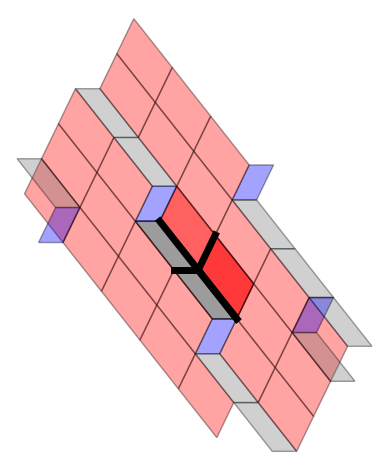

(frozenset({frozenset({0, 1})}), (('C21', -lam^2), ('C15', 0)))
(frozenset({frozenset({0, lam^2})}), (('C04', lam^2), ('C15', -1), ('C22', lam^2)))
(frozenset({frozenset({0, lam})}), (('C04', lam^2), ('C13', 0)))
(frozenset({frozenset({0, lam^2})}), (('C10', lam^2), ('C13', lam^2), ('C21', -1)))
(frozenset({frozenset({0, lam})}), (('C10', 0), ('C22', lam^2)))


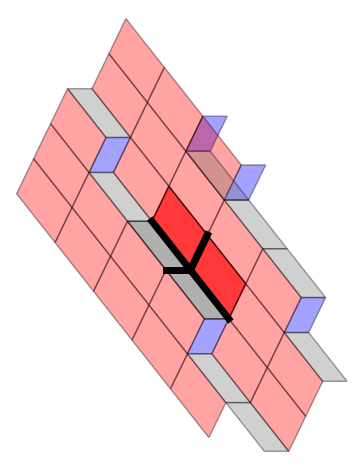

(frozenset({frozenset({0, lam})}), (('C10', 0), ('C22', lam^2)))
(frozenset({frozenset({0, lam})}), (('C19', 0), ('C14', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C10', lam^2 - lam), ('C19', lam^2)))
(frozenset({frozenset({0, lam^2})}), (('C22', lam^2 - lam), ('C14', lam^2)))


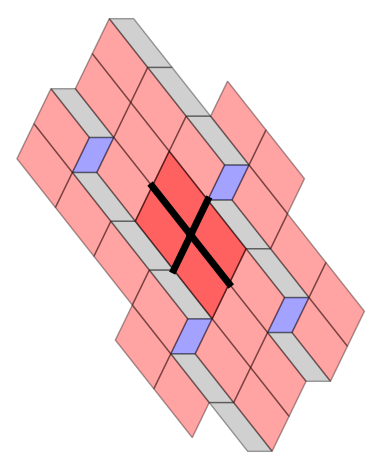

In [31]:
for zero_cell in zero_cells:
    test = CollaredKenyonPatch()
    G = Graphics()
    for located_one_cell in zero_cell:
        one_cell = label_to_one_cell[located_one_cell[0]]
        one_cell_loc = located_one_cell[1]
        print(one_cell)
        
        nf_endpoints = list(list(one_cell[0])[0])
        endpoints = []
        for pt in nf_endpoints:
            endpoints.append(number_field_to_vector(pt - one_cell_loc))
        G += line(endpoints, thickness=5, rgbcolor=(0,0,0))
       
        for located_collar in one_cell[1]:
            collar_code = located_collar[0]
            collar_loc = located_collar[1]
            unshifted_collar = collar_code_to_list_dict[collar_code]
            test.add_collared_prototile(unshifted_collar[0], collar_loc - one_cell_loc, unshifted_collar[1])
            # new_decoration = set()
            # for tile in unshifted_collar[1]:
            #     new_tile = (tile[0], tile[1] + collar_loc)
            #     new_decoration.add(new_tile)
            # shifted_collar = (unshifted_collar[0], frozenset(new_decoration))
            
            # G += test.display_collar(shifted_collar)
    G += test.graph_patch()
    show(G)    

In [12]:
for one in label_to_one_cell.keys():
    print(one)
    break

E00


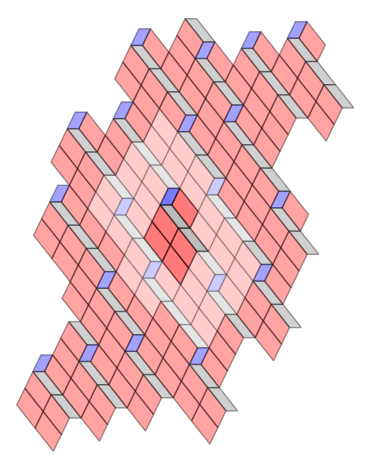

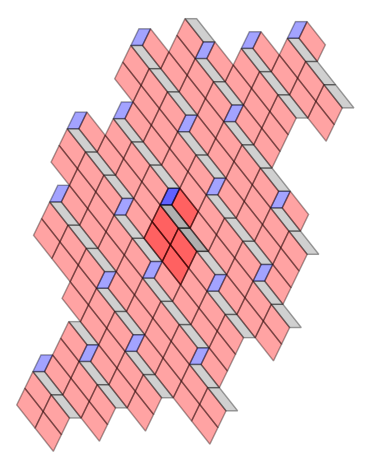

In [92]:
(center_tile, decoration) = collar_code_to_list_dict['C00']

test = CollaredKenyonPatch(0, collared_sub_dict)
test.add_collared_prototile(center_tile, 0, decoration)
# show(test.graph_patch())
test.substitute_once(2)
test.substitute_once(2)
show(test.graph_patch())

test = CollaredKenyonPatch(0, collared_sub_dict)
test.add_collared_prototile(center_tile, 0, decoration)
# show(test.graph_patch())
test.substitute()
show(test.graph_patch())

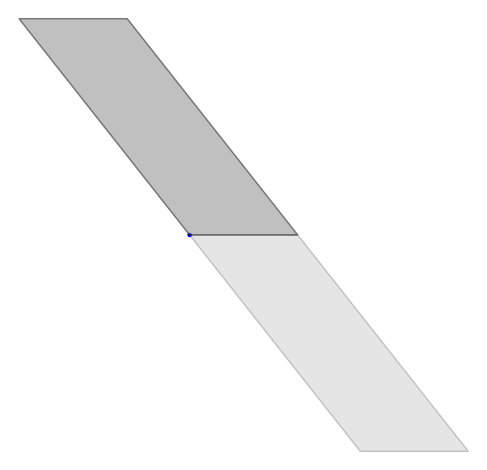

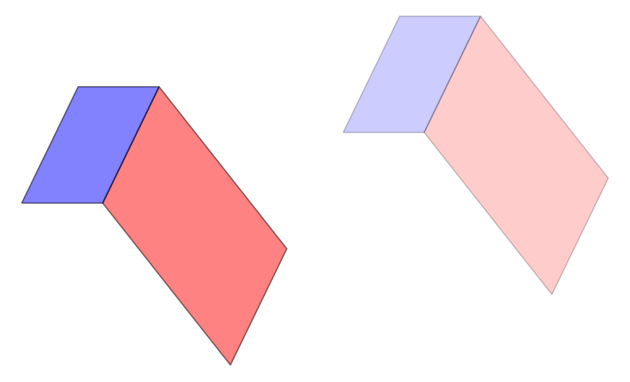

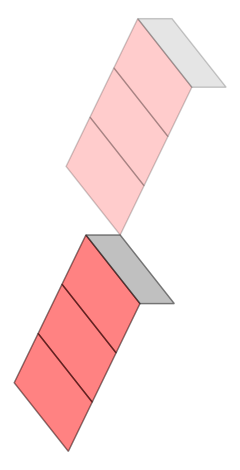

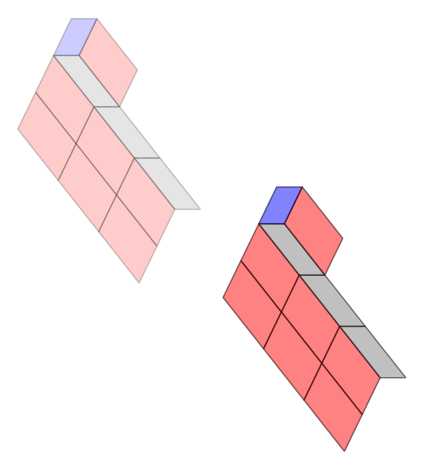

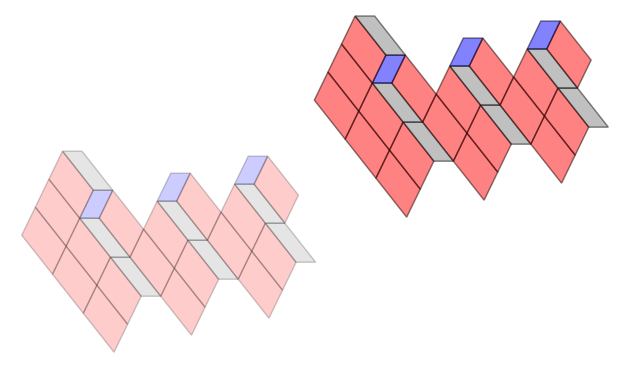

...

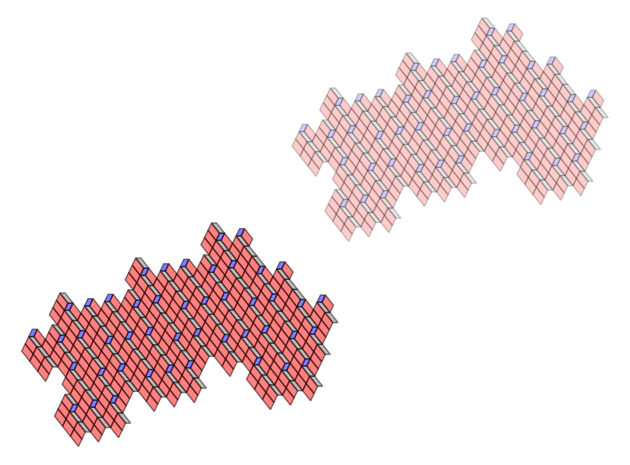

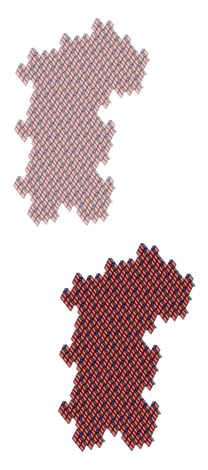

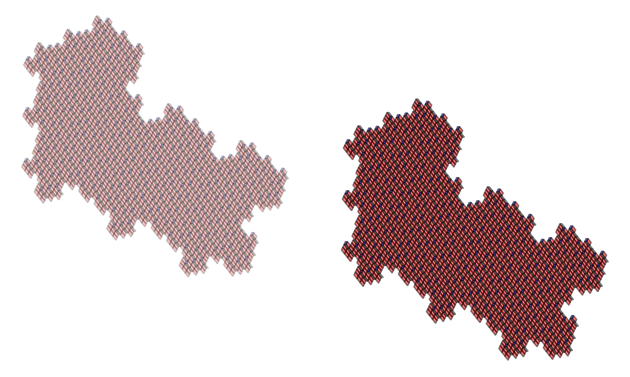

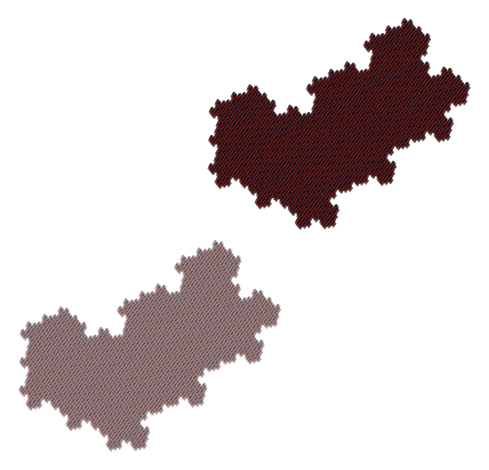

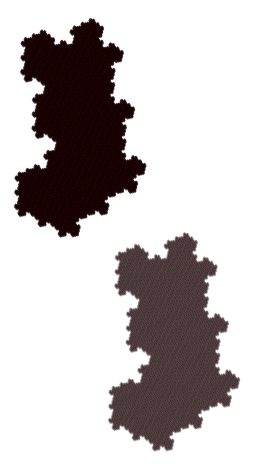

KeyboardInterrupt: 

In [109]:
test = Patch()

test.add_prototile_code('G', 0)
test.add_prototile_code('G', 0)
test.add_prototile_code('G', 0)
test.add_prototile_code('G', -lam^2)
# test.add_prototile_code('R', lam^2)
G = Graphics()
G += test.graph_patch()
G += points((0,0))
# G += line([(0,0), number_field_to_vector(lam)])
# G += line([(0,0), number_field_to_vector(-lam^2)])
show(G)


for i in range(15):
    test.substitute_patch()
    show(test.graph_patch())



# test = Patch()

# test.add_prototile_code('R', 0)
# test.add_prototile_code('R', 0)
# test.add_prototile_code('R', 0)
# test.add_prototile_code('R', -lam^2)
# # test.add_prototile_code('R', lam^2)
# G = Graphics()
# G += test.graph_patch()
# G += points((0,0))
# # G += line([(0,0), number_field_to_vector(lam)])
# # G += line([(0,0), number_field_to_vector(-lam^2)])
# show(G)

# test.substitute_patch()
# show(test.graph_patch())
# test.substitute_patch()
# G = Graphics()
# G += test.graph_patch()
# # G += line([(0,0), number_field_to_vector(lam^3)])
# # G += line([(0,0), number_field_to_vector(-lam^4)])
# show(G)
# test.substitute_patch()
# test.substitute_patch()
# test.substitute_patch()
# show(test.graph_patch())

[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


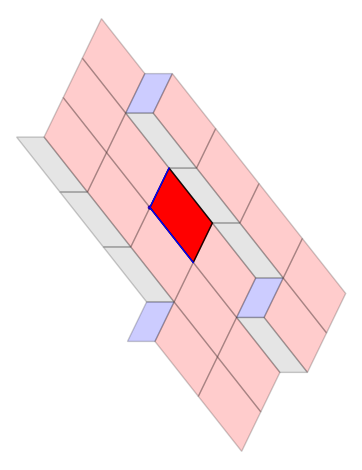

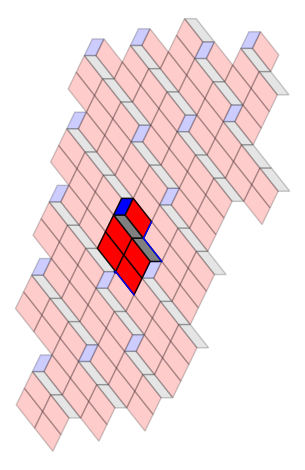

collar_1[1] = lam^2
collar_2[1] = 0
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


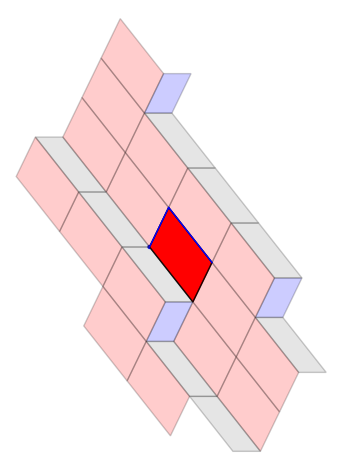

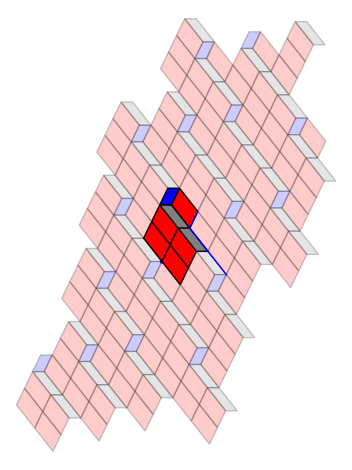

collar_1[1] = lam^2 - lam
collar_2[1] = 0
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


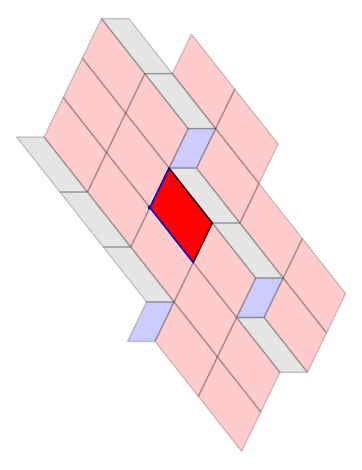

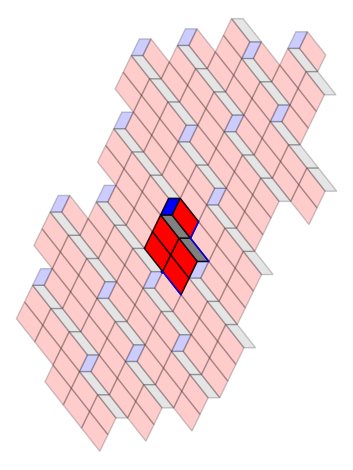

collar_1[1] = lam^2
collar_2[1] = 0
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


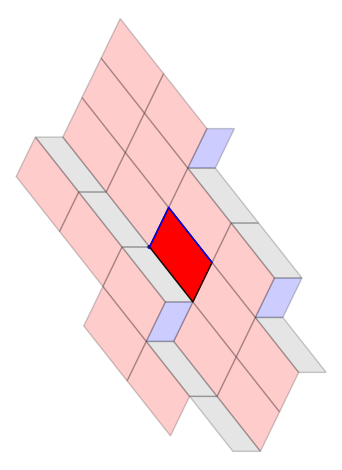

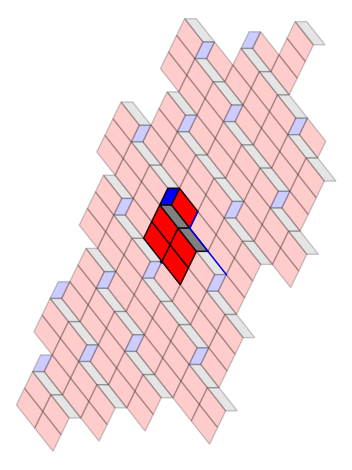

collar_1[1] = lam^2 - lam
collar_2[1] = 0
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


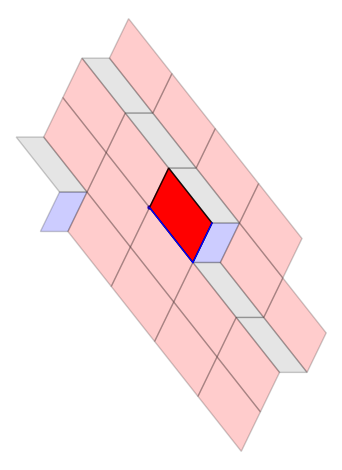

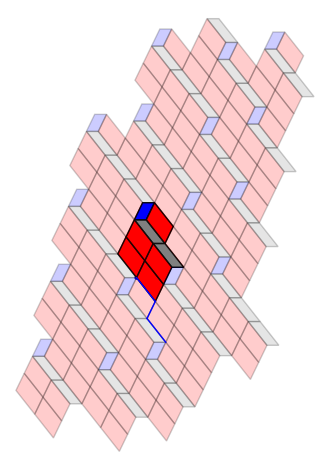

collar_1[1] = lam^2
collar_2[1] = lam^2
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


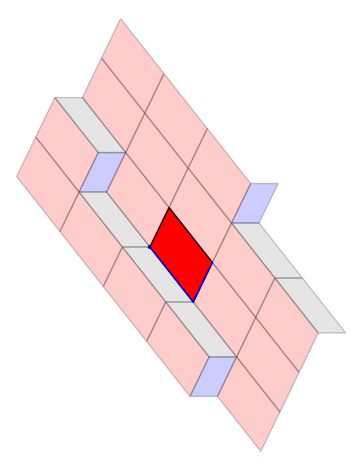

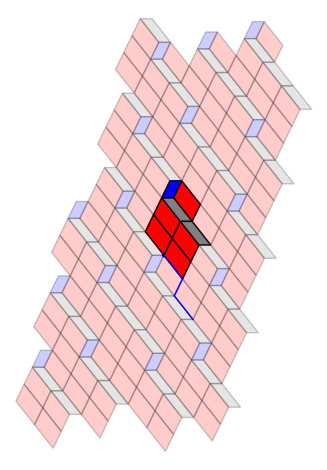

collar_1[1] = lam^2
collar_2[1] = lam^2
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


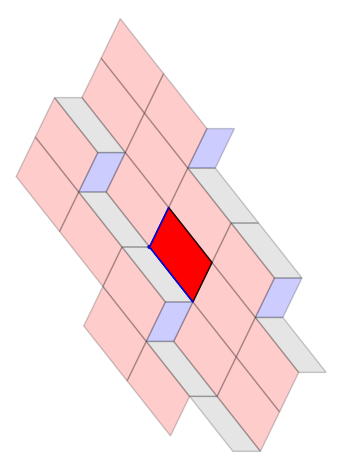

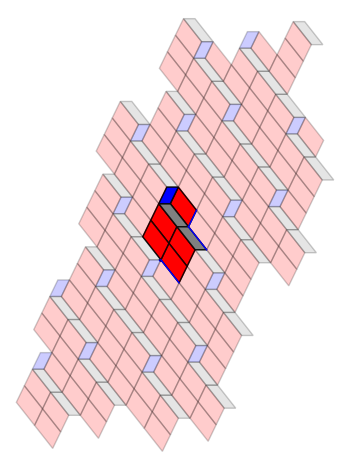

collar_1[1] = 0
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


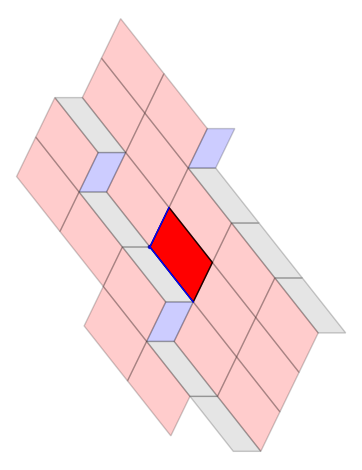

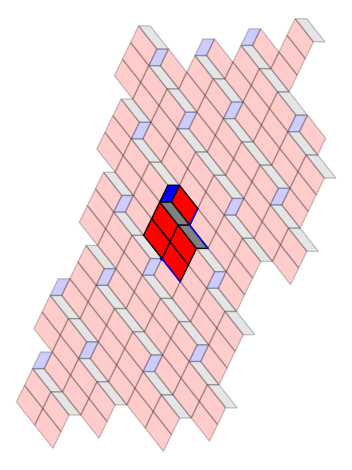

collar_1[1] = 0
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


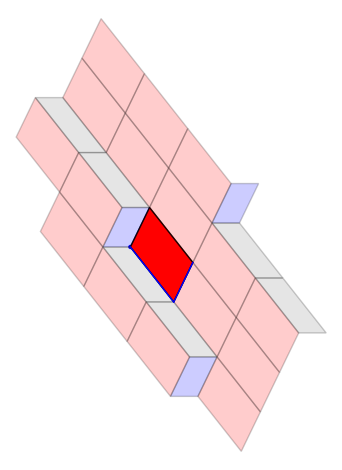

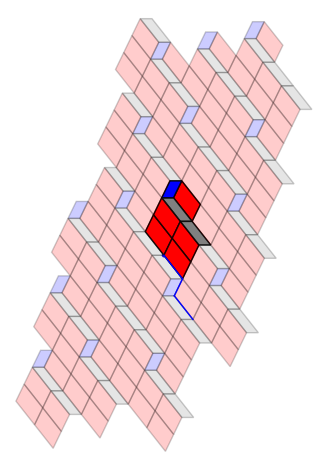

collar_1[1] = lam^2
collar_2[1] = lam^2
[(0.000000000000000, 0.000000000000000), (1.00000000000000, 0.000000000000000)]
[(0.303676609148680, -1.43594986410996), (1.00000000000000, 0.000000000000000)]


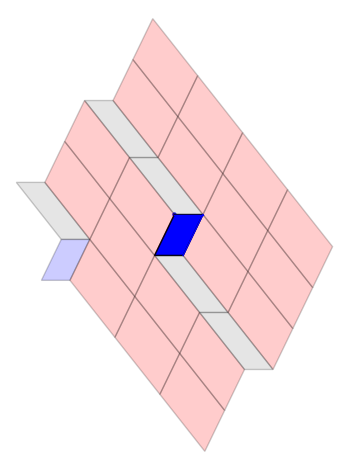

L one cell substitution
[(0.000000000000000, 0.000000000000000), (1.00000000000000, 0.000000000000000)]
[(1.00000000000000, 0.000000000000000), (-0.577085747590721, 1.99977095693907)]


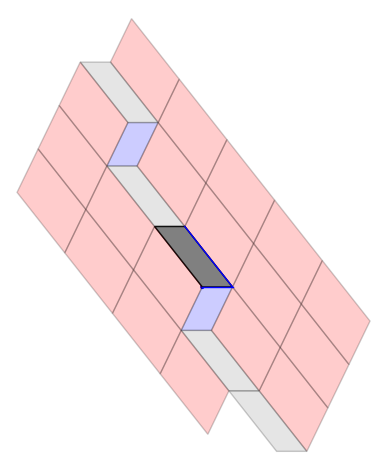

L one cell substitution
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]


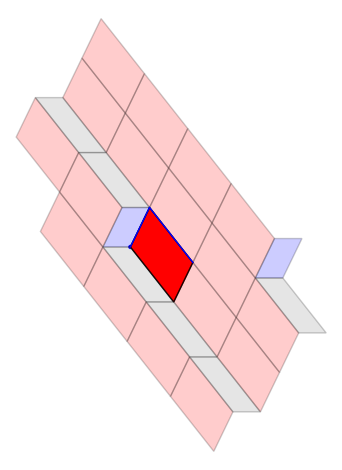

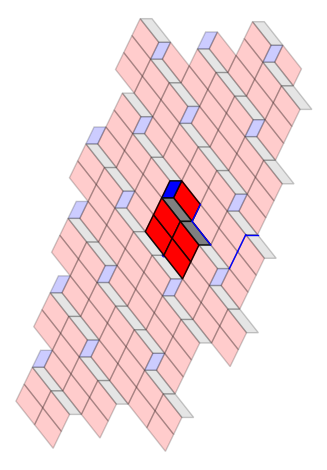

collar_1[1] = 0
collar_2[1] = lam^2 - lam
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


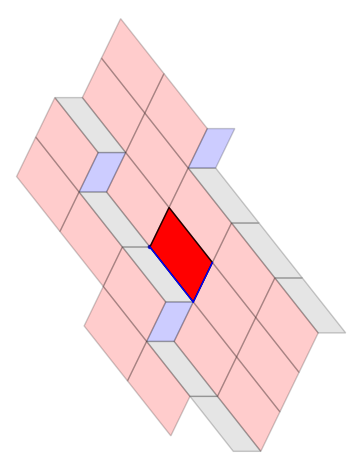

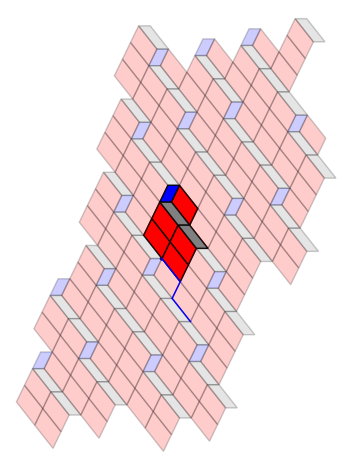

collar_1[1] = lam^2
collar_2[1] = lam^2
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


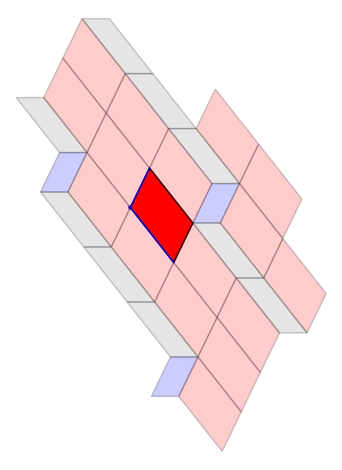

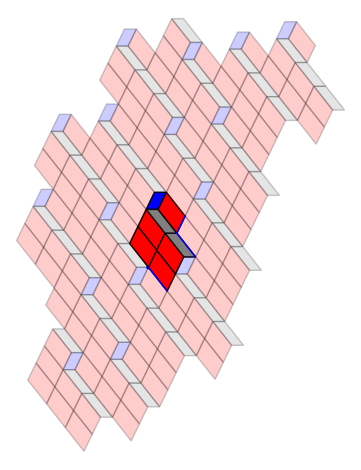

collar_1[1] = lam^2
collar_2[1] = 0
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


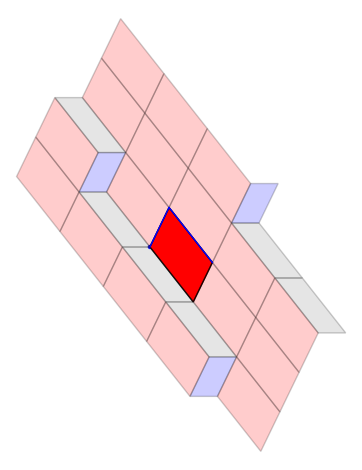

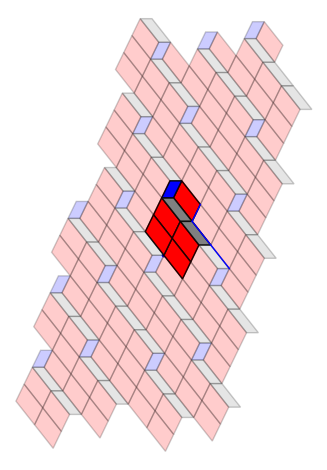

collar_1[1] = lam^2 - lam
collar_2[1] = 0
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]


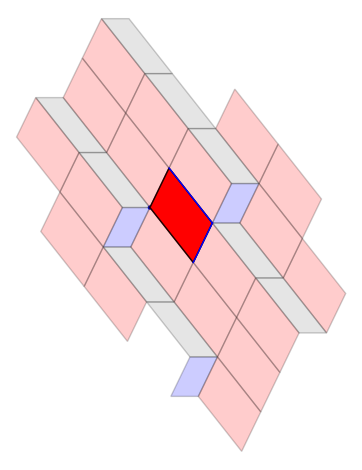

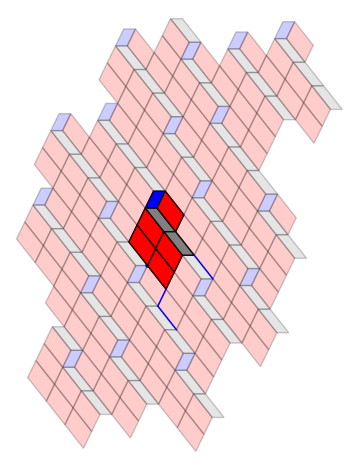

collar_1[1] = lam^2 - lam
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]


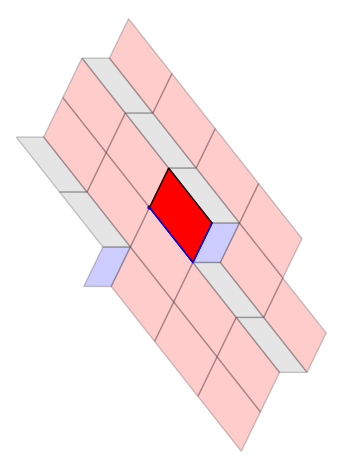

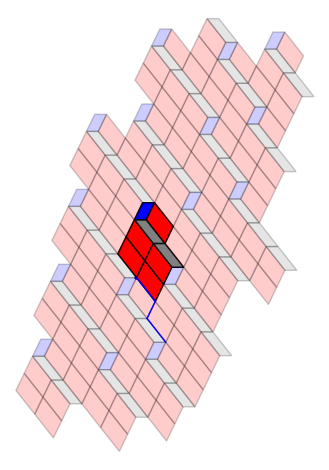

collar_1[1] = lam^2
collar_2[1] = lam^2
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


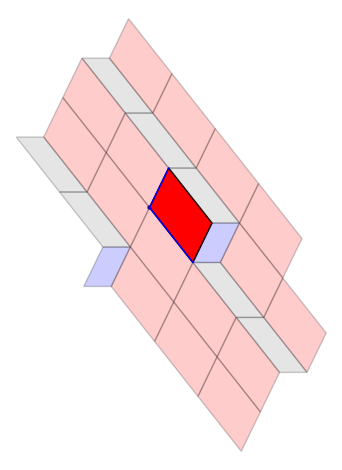

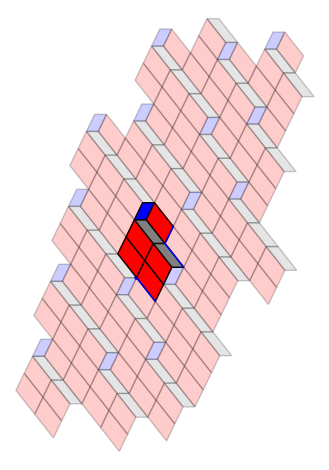

collar_1[1] = 0
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


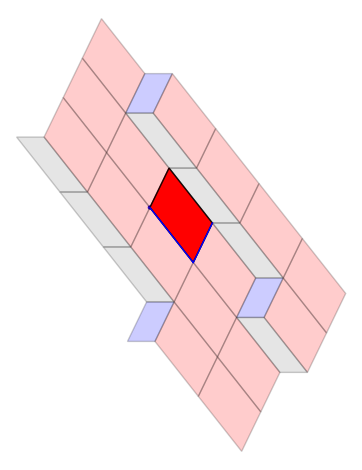

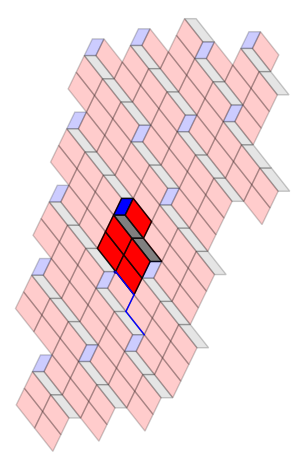

collar_1[1] = lam^2
collar_2[1] = lam^2
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]


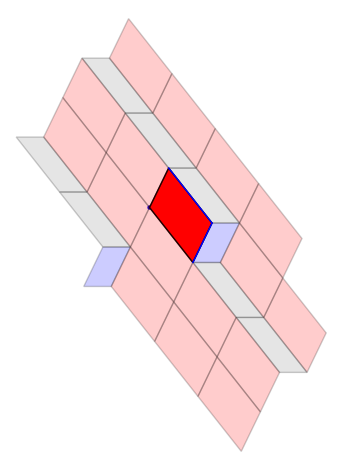

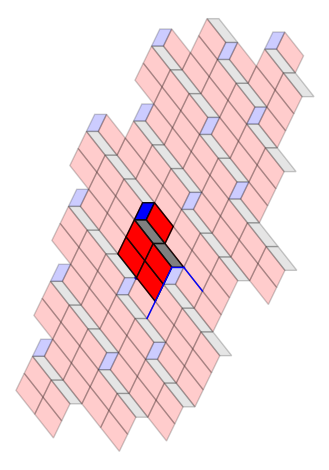

collar_1[1] = lam^2
collar_2[1] = lam^2 - lam
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


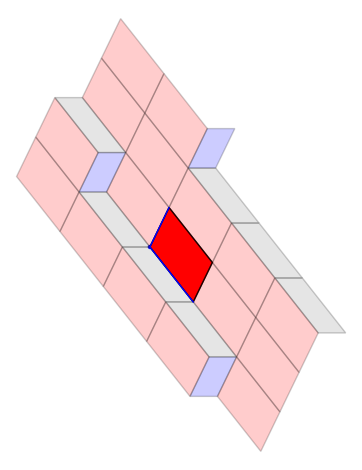

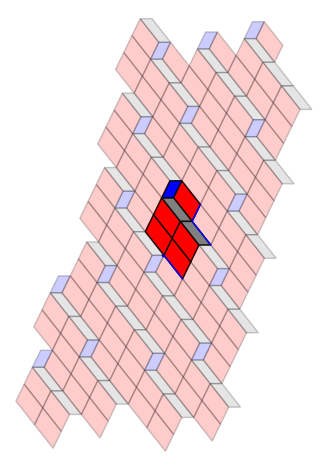

collar_1[1] = 0
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


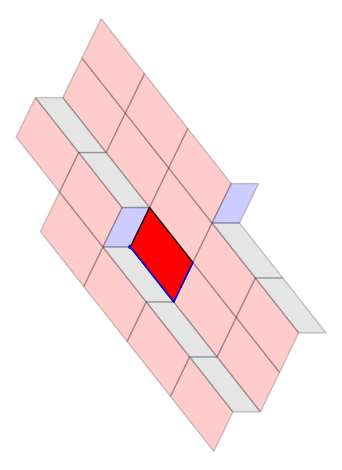

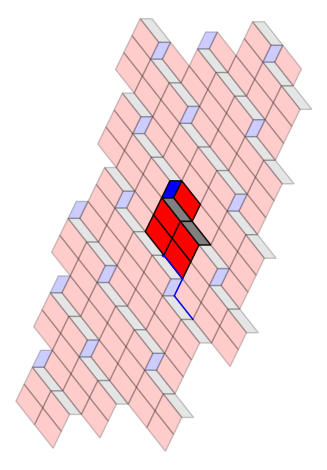

collar_1[1] = lam^2
collar_2[1] = lam^2
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


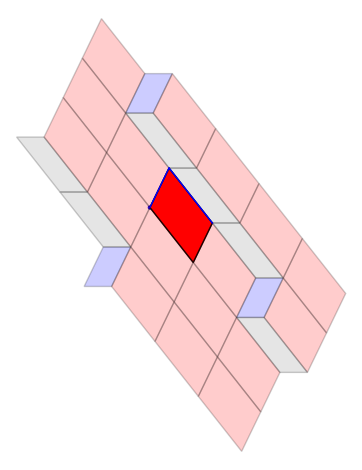

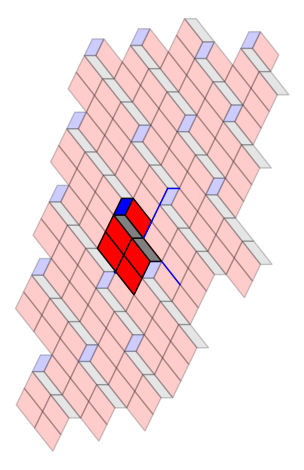

collar_1[1] = lam^2 - lam
collar_2[1] = 0
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(0.000000000000000, 0.000000000000000), (-1.57708574759072, 1.99977095693907)]
[(-1.57708574759072, 1.99977095693907), (-0.577085747590721, 1.99977095693907)]


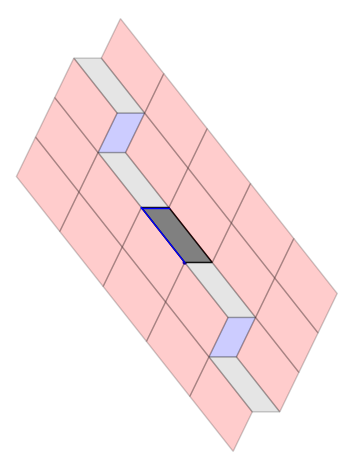

L one cell substitution
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


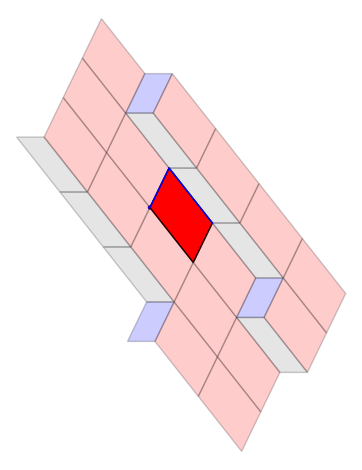

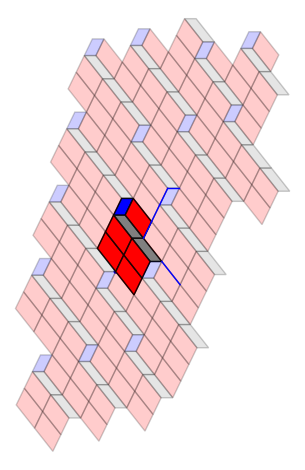

collar_1[1] = lam^2 - lam
collar_2[1] = 0
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]


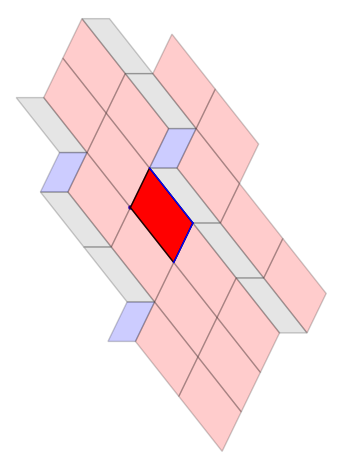

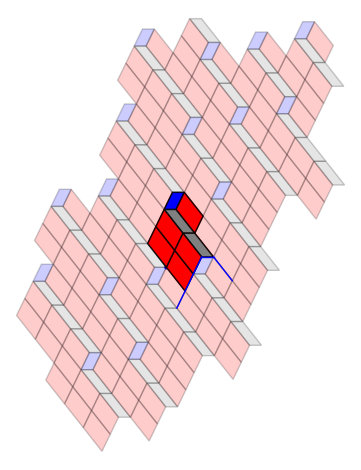

collar_1[1] = lam^2 - lam
collar_2[1] = lam^2
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]


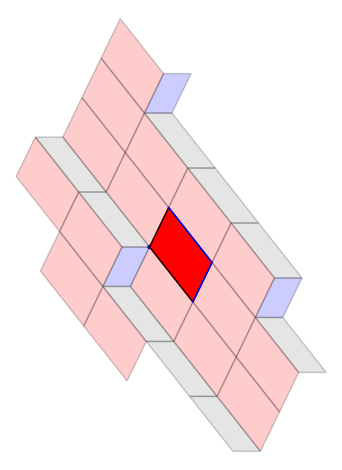

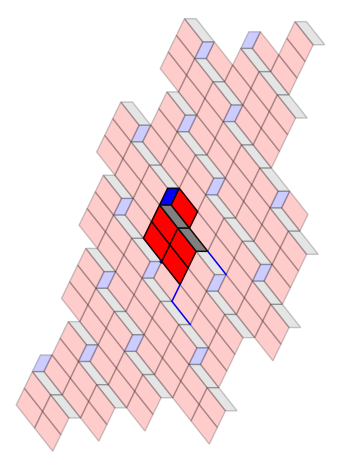

collar_1[1] = lam^2 - lam
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]


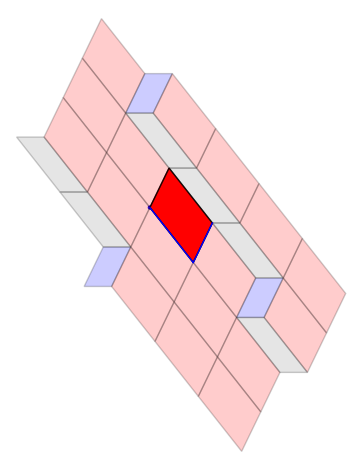

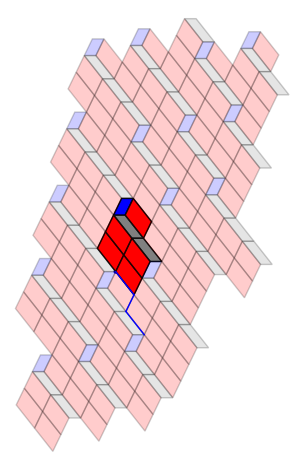

collar_1[1] = lam^2
collar_2[1] = lam^2
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


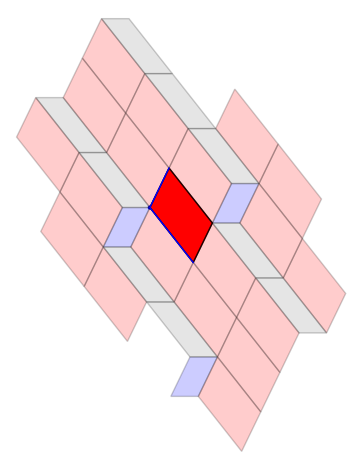

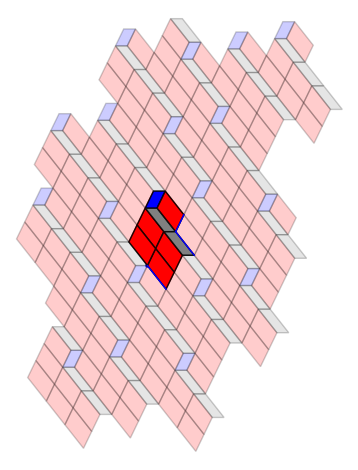

collar_1[1] = 0
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


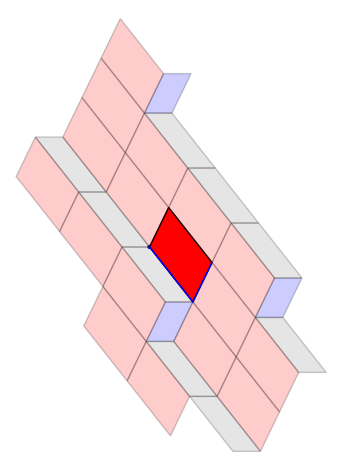

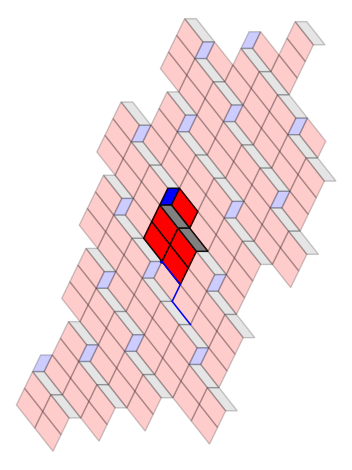

collar_1[1] = lam^2
collar_2[1] = lam^2
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


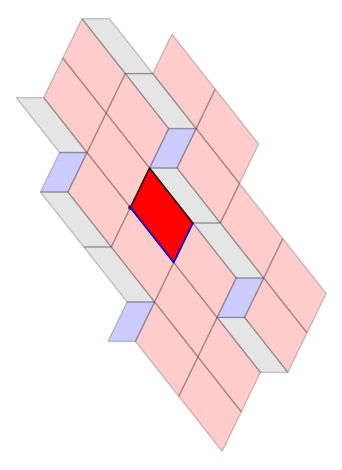

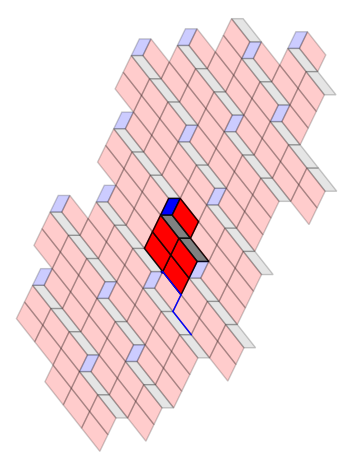

collar_1[1] = lam^2
collar_2[1] = lam^2
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


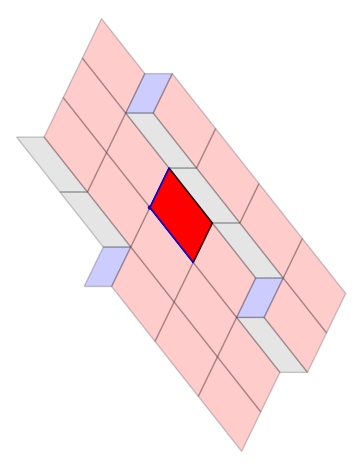

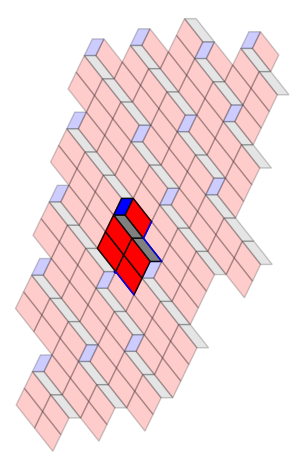

collar_1[1] = 0
collar_2[1] = lam^2
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]


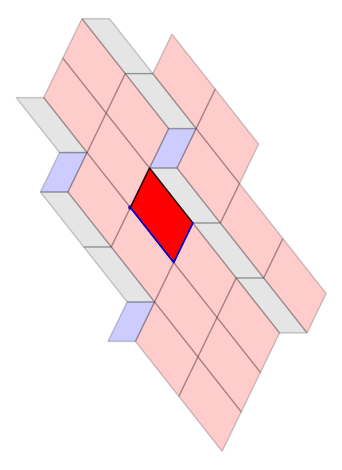

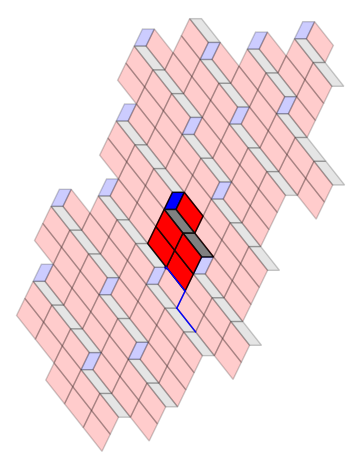

collar_1[1] = lam^2
collar_2[1] = lam^2
[(0.000000000000000, 0.000000000000000), (1.00000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (-1.57708574759072, 1.99977095693907)]


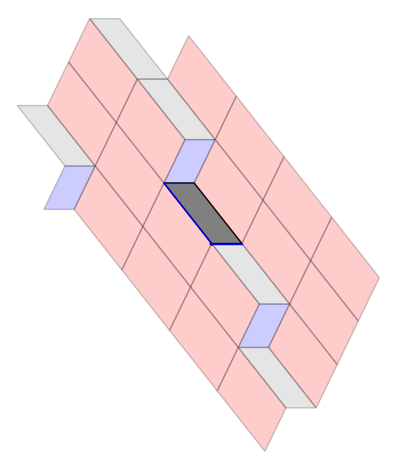

L one cell substitution
[(-1.57708574759072, 1.99977095693907), (-0.577085747590721, 1.99977095693907)]
[(0.000000000000000, 0.000000000000000), (-1.57708574759072, 1.99977095693907)]


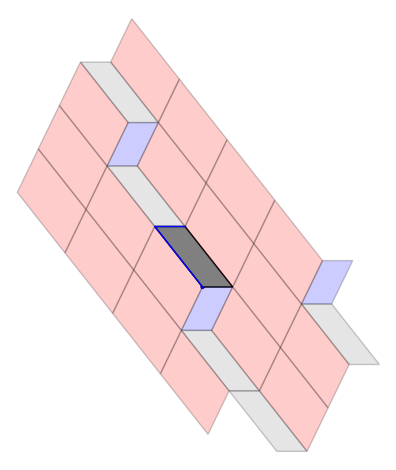

L one cell substitution
[(0.000000000000000, 0.000000000000000), (1.00000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (-1.57708574759072, 1.99977095693907)]


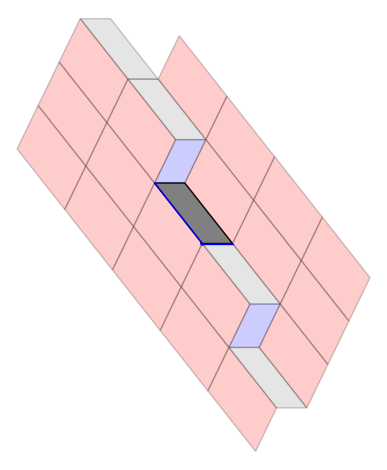

L one cell substitution
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]


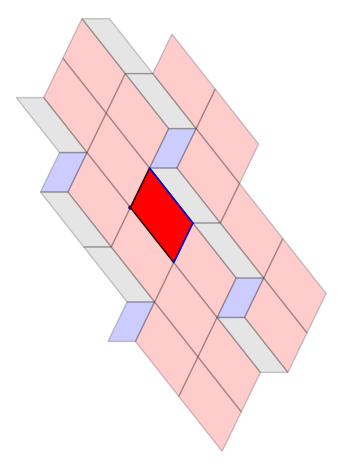

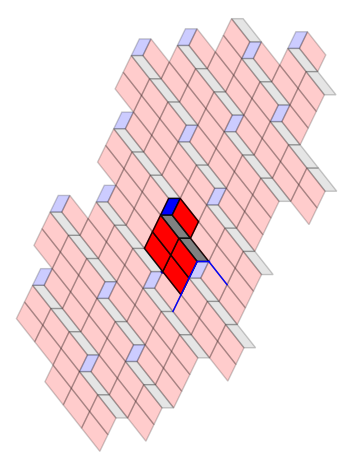

collar_1[1] = lam^2 - lam
collar_2[1] = lam^2
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


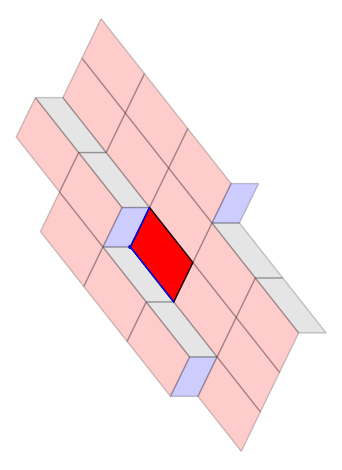

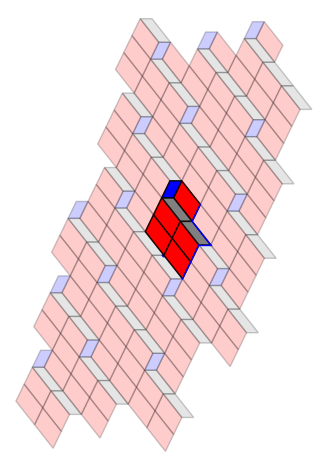

collar_1[1] = lam^2
collar_2[1] = 0
[(-1.57708574759072, 1.99977095693907), (-0.577085747590721, 1.99977095693907)]
[(0.000000000000000, 0.000000000000000), (-1.57708574759072, 1.99977095693907)]


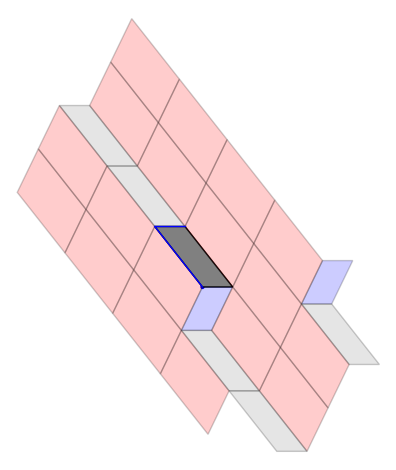

L one cell substitution
[(0.000000000000000, 0.000000000000000), (1.00000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (-1.57708574759072, 1.99977095693907)]


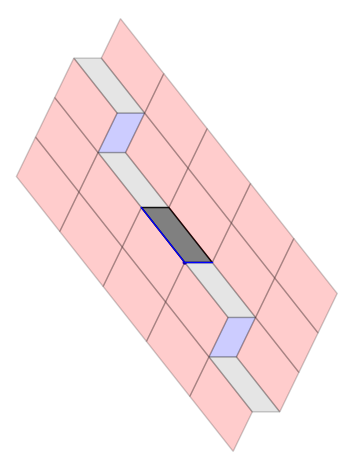

L one cell substitution
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]


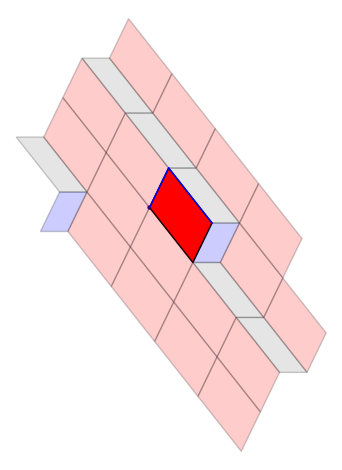

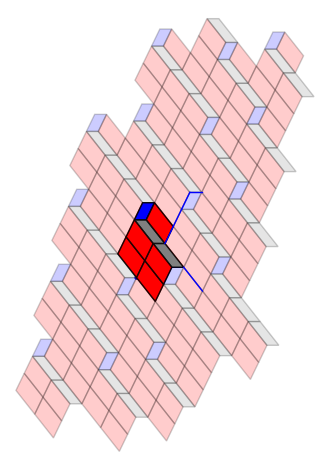

collar_1[1] = 0
collar_2[1] = lam^2 - lam
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]


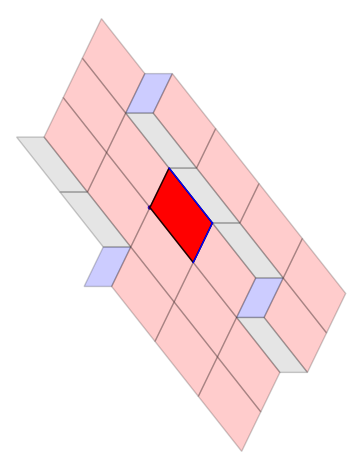

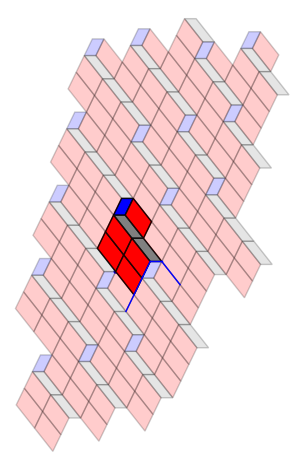

collar_1[1] = lam^2
collar_2[1] = lam^2 - lam
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(1.57708574759072, -1.99977095693907), (2.27340913844204, -0.563821092829119)]


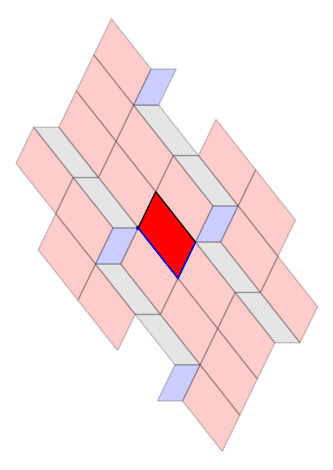

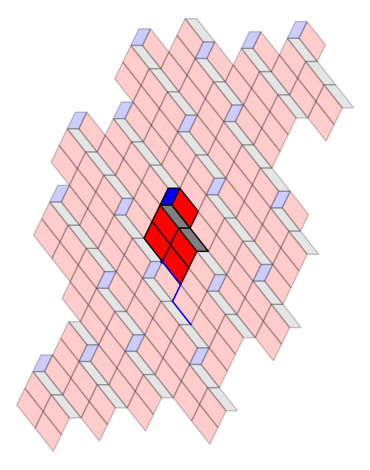

collar_1[1] = lam^2
collar_2[1] = lam^2
[(1.57708574759072, -1.99977095693907), (0.000000000000000, 0.000000000000000)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


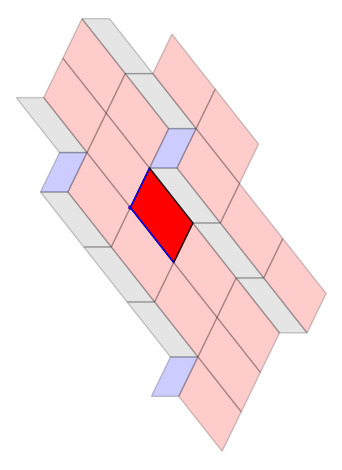

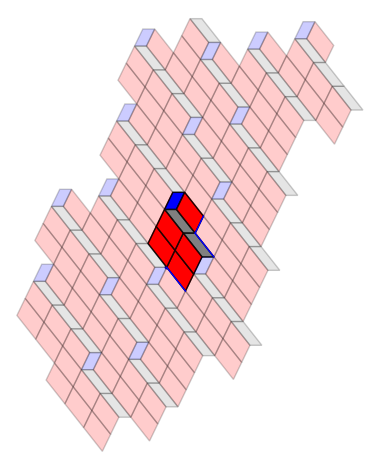

collar_1[1] = lam^2
collar_2[1] = 0
NO INTERSECTION BETWEEN IMAGE ONE CELLS, LETS TRY SOME OTHER ONE CELLS?
[(2.27340913844204, -0.563821092829119), (0.696323390851320, 1.43594986410996)]
[(0.000000000000000, 0.000000000000000), (0.696323390851320, 1.43594986410996)]


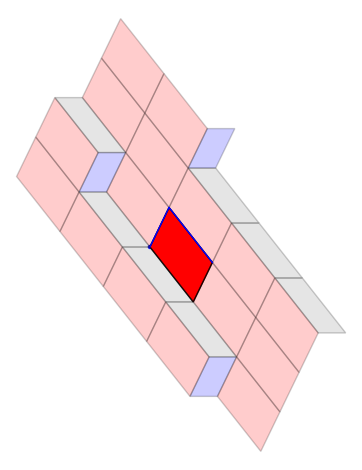

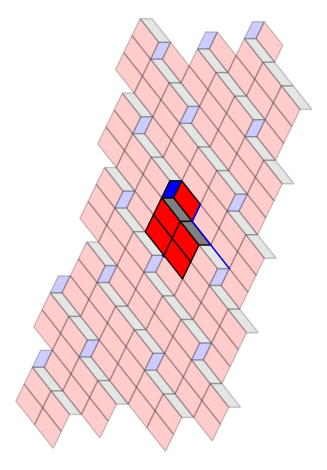

collar_1[1] = lam^2 - lam
collar_2[1] = 0


In [82]:
zero_cell_sub_dict = generate_zero_cell_substitutions(zero_cells)

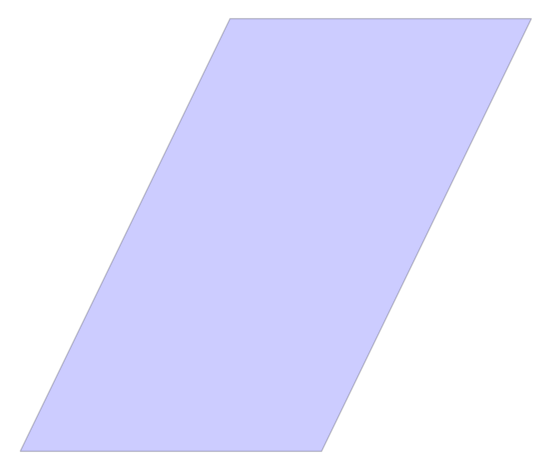

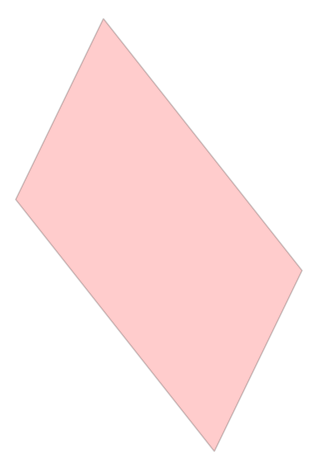

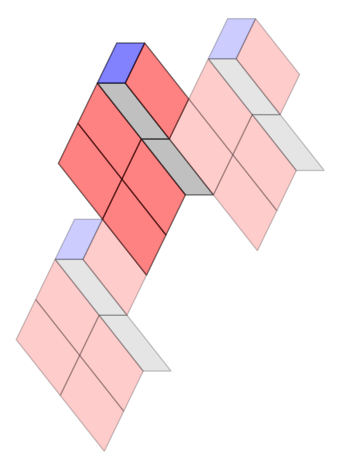

In [85]:
test = Patch()

test.add_prototile_code('B', K(0))
# G = Graphics()
show(test.graph_patch())
test.substitute_patch()
# test.substitute_patch()
show(test.graph_patch())

# show(G)
